# Data exploration
Initial data exploration. Includes individual plots (P0002) and grand average over all subjects. Similar plots are replicated as in the Binocular Rivalry article: Evaluating the Role of Theta Power as 
a Neural Index of Conflict (A. Drew, J. San-Segundo, S. Soto-Faraco, M. Torralba Cuello), among others.

## Objectives of this notebook
1. Run shared initialization to load amounts, routes, constants, and reusable functions.
2. Load a work item for individual scanning and validate channel availability/conditions.
3. Build the behavioral and dominance EDA layer with the common functions.
4. Generate individual visualizations (ERP, time-courses theta/alpha, differential TFR) with common conventions.
5. Run the grand average route over all subjects with the same global parameters.
6. Report data quality results and consistency with the reference article.

In [118]:
import gc
import importlib.util
import subprocess
import sys
import warnings
from pathlib import Path
import tempfile, shutil

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, Rectangle
import mne
import numpy as np
import pandas as pd
import pickle
from scipy.signal import stft
from scipy.stats import ConstantInputWarning, binomtest, spearmanr

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive", force_remount=False)
    required_packages = ["mne", "imbalanced-learn", "xgboost", "lightgbm"]
    for pkg in required_packages:
        if importlib.util.find_spec(pkg.replace("-", "_")) is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*does not conform to MNE naming conventions.*",
)
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*events passed to the Epochs constructor are not chronologically ordered.*",
)
mne.set_log_level("WARNING")

In [119]:
if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
META_DIR = PROJECT_DIR / "02_Data" / "02_meta"

ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
EXPLORATION_DIR = ANALYSIS_ROOT / "01_exploracio"
RESULTS_DIR = EXPLORATION_DIR
FIGURES_DIR = EXPLORATION_DIR / "figures"
TABLES_DIR = EXPLORATION_DIR / "tables"
for folder in (DATA_DIR, META_DIR, ANALYSIS_ROOT, EXPLORATION_DIR, FIGURES_DIR, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

# Constants compartides
COND_EVENTS_CODES = {
    "Congruent": [1, 2],
    "Incongruent_Pure": [3, 4, 5, 6],
    "Incongruent_Mixed": [7, 8],
    "Incongruent": [3, 4, 5, 6, 7, 8],
    "Errors": [9, 10, 11, 12],
}

EVENT_TO_LABEL = {
    1: "CRP",
    2: "CGP",
    3: "IPR",
    4: "IPR",
    5: "IPG",
    6: "IPG",
    7: "IM",
    8: "IM",
    9: "CRG",
    10: "CGG",
    11: "CRM",
    12: "CGM",
}

LABELS = {
    "Congruent": "Congruent (C)",
    "Incongruent_Pure": "Incongruent Pure (IP)",
    "Incongruent_Mixed": "Incongruent Mixed (IM)",
    "Incongruent": "Incongruent (I)",
    "Errors": "Errors",
}
COLORS = {
    "Congruent": "steelblue",
    "Incongruent_Pure": "darkorange",
    "Incongruent_Mixed": "forestgreen",
    "Incongruent": "slategray",
    "Errors": "firebrick",
}

LABELS_ORDER = ["CRP", "CGP", "IPR", "IPG", "IM", "CRM", "CRG", "CGM", "CGG"]

TRIAL_START = -0.74
TRIAL_END = 1.5
FULL_TRIAL = (TRIAL_START, TRIAL_END)
BASELINE = (-0.74, -0.24)
ERP_WINDOW = (0.5, 1.0)

FREQS_THETA = np.arange(5, 8)
FREQS_ALPHA = np.arange(8, 13)
FREQS_WIDE = np.arange(2, 21)

ROI_FRONTAL = ["Fz", "FCz", "Cz"]
ROI_PO = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"]

EYE_LEFT_CODES = [3, 6]
EYE_RIGHT_CODES = [4, 5]
COLOR_RED_CODES = [1, 3, 4, 10]
COLOR_GREEN_CODES = [2, 5, 6, 9]
ERROR_CODES = [9, 10, 11, 12]

STFT_WINDOW_SEC = 0.5
STFT_STEP_SEC = 0.02

N_BINS = 10
BOOT_N = 3000
SMOOTH_WIN = 5

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Data directory: {DATA_DIR}")
print(f"Exploration results: {EXPLORATION_DIR}")
print(f".fif files found: {len(DATA_FILES)}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Data directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Exploration results: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio
.fif files found: 47


In [190]:
def load_subject(fif_path):
    ep = mne.read_epochs(fif_path, preload=False, verbose=False)
    ep.load_data()

    for ch in ep.info["chs"]:
        if ch["unit"] == 0:
            ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
            ch["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

    # Convert microvolts to volts (µV -> V)
    ep._data *= 1e-6

    mapping = {ch_name: "eeg" for ch_name in ep.ch_names}
    ep.set_channel_types(mapping, on_unit_change="ignore")

    # There were many bugs and inconsistencies with event_X between different subjects
    # Now we do this based on the actual numerical codes of the events present in each subject
    # The tags are the ground truth and yes they are correct. event_id will now have the code "id"
    ep.event_id = {f"event_{code}": code for code in np.unique(ep.events[:, 2])}
    cond = {}
    for cond_name, codes_list in COND_EVENTS_CODES.items():
        valid_names = [f"event_{code}" for code in codes_list if f"event_{code}" in ep.event_id]
        if valid_names:
            cond[cond_name] = ep[valid_names]
    return ep, cond


def row_binom_ci(successes, total):
    if int(total) <= 0:
        return np.nan, np.nan
    bt = binomtest(int(successes), n=int(total), p=0.5, alternative="two-sided")
    ci = bt.proportion_ci(confidence_level=0.95, method="exact")
    return ci.low, ci.high


def build_behavior_dominance_summary(data_dir=DATA_DIR):
    """Calculate behavioral dominance metrics and save series for reuse."""
    subject_rows = []
    comptes_classes = {cond: 0 for cond in COND_EVENTS_CODES}

    for fif_path in sorted(data_dir.glob("*.fif")):
        ep = mne.read_epochs(fif_path, preload=False, verbose=False)
        events = ep.events[:, 2]

        for cond_name, codes in COND_EVENTS_CODES.items():
            comptes_classes[cond_name] += int(np.isin(events, codes).sum())

        counts = {k: 0 for k in ["CRP", "CRM", "CRG", "CGP", "CGM", "CGG", "IPR", "IPG", "IM"]}
        for ev in events:
            if ev in EVENT_TO_LABEL:
                counts[EVENT_TO_LABEL[ev]] += 1

        left_eye = int(np.sum(np.isin(events, EYE_LEFT_CODES)))
        right_eye = int(np.sum(np.isin(events, EYE_RIGHT_CODES)))
        n_eye = left_eye + right_eye
        eye_index = (left_eye - right_eye) / n_eye if n_eye > 0 else np.nan
        p_eye = binomtest(left_eye, n=n_eye, p=0.5).pvalue if n_eye > 0 else np.nan
        ci_eye_low, ci_eye_high = row_binom_ci(left_eye, n_eye)

        ip_count = counts["IPR"] + counts["IPG"]
        im_count = counts["IM"]
        im_vs_ip_index = (im_count - ip_count) / (im_count + ip_count) if (im_count + ip_count) > 0 else np.nan
        p_im_vs_ip = binomtest(im_count, n=(im_count + ip_count), p=0.5).pvalue if (im_count + ip_count) > 0 else np.nan
        ci_im_vs_ip_low, ci_im_vs_ip_high = row_binom_ci(im_count, (im_count + ip_count))
        red_count = int(np.sum(np.isin(events, COLOR_RED_CODES)))
        green_count = int(np.sum(np.isin(events, COLOR_GREEN_CODES)))
        n_color = red_count + green_count
        color_index = (red_count - green_count) / n_color if n_color > 0 else np.nan
        p_color = binomtest(red_count, n=n_color, p=0.5).pvalue if n_color > 0 else np.nan
        ci_color_low, ci_color_high = row_binom_ci(red_count, n_color)

        left_red = int(np.sum(events == 3))
        left_green = int(np.sum(events == 6))
        right_red = int(np.sum(events == 4))
        right_green = int(np.sum(events == 5))

        row = {
            "subject": fif_path.stem,
            **counts,
            "dominance_index_im": im_vs_ip_index,
            "ci95_im_vs_ip_low": ci_im_vs_ip_low,
            "ci95_im_vs_ip_high": ci_im_vs_ip_high,
            "p_im_vs_ip": p_im_vs_ip,
            "left_eye": left_eye,
            "right_eye": right_eye,
            "n_eye": n_eye,
            "dominance_index_eye": eye_index,
            "p_eye": p_eye,
            "ci95_eye_low": ci_eye_low,
            "ci95_eye_high": ci_eye_high,
            "red_count": red_count,
            "green_count": green_count,
            "n_color": n_color,
            "dominance_index_color": color_index,
            "p_color": p_color,
            "ci95_color_low": ci_color_low,
            "ci95_color_high": ci_color_high,
            "left_red": left_red,
            "left_green": left_green,
            "right_red": right_red,
            "right_green": right_green,
        }
        subject_rows.append(row)

    df = pd.DataFrame(subject_rows).sort_values("subject").reset_index(drop=True)
    label_counts = {k: int(df[k].sum()) for k in ["CRP", "CRM", "CRG", "CGP", "CGM", "CGG", "IPR", "IPG", "IM"]}
    globals_summary = {
        "left_global": int(df["left_eye"].sum()),
        "right_global": int(df["right_eye"].sum()),
        "red_global": int(df["red_count"].sum()),
        "green_global": int(df["green_count"].sum()),
    }
    return df, comptes_classes, label_counts, globals_summary


def stft_power_db(ep, picks, freqs=FREQS_WIDE, baseline=BASELINE):
    x = ep.copy().pick(picks).get_data().astype(np.float32, copy=False)
    sfreq = ep.info["sfreq"]

    nperseg = int(round(STFT_WINDOW_SEC * sfreq))
    hop = int(round(STFT_STEP_SEC * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    f, t, z = stft(
        x,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    power = np.abs(z).astype(np.float32) ** 2

    freq_targets = np.asarray(freqs)
    freq_idx = np.array([np.argmin(np.abs(f - fr)) for fr in freq_targets])
    f_sel = f[freq_idx]
    power = power[:, :, freq_idx, :]

    times = ep.tmin + t
    bmask = (times >= baseline[0]) & (times <= baseline[1])
    b = power[..., bmask].mean(axis=-1, keepdims=True)
    power_db = 10 * np.log10((power + 1e-20) / (b + 1e-20))
    return f_sel, times, power_db.astype(np.float32)


def stft_band_timecourse(ep, picks, band, baseline=BASELINE):
    f, times, power_db = stft_power_db(ep, picks=picks, freqs=FREQS_WIDE, baseline=baseline)
    fmask = (f >= band[0]) & (f <= band[1])
    band_db = power_db[:, :, fmask, :]
    mean_ts = band_db.mean(axis=(0, 1, 2))
    sem_ts = band_db.std(axis=(0, 1, 2)) / np.sqrt(band_db.shape[0])
    return times, mean_ts, sem_ts


def stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4):
    ch_names = ep.ch_names
    n_ch = len(ch_names)
    acc = None
    f_ref, t_ref = None, None

    for start in range(0, n_ch, ch_block):
        picks = ch_names[start : start + ch_block]
        f, t, p_db = stft_power_db(ep, picks=picks, freqs=freqs, baseline=baseline)
        block_mean = p_db.mean(axis=(0, 1))

        if acc is None:
            acc = np.zeros_like(block_mean)
            f_ref, t_ref = f, t

        acc += block_mean * len(picks)
        del p_db, block_mean
        gc.collect()

    return f_ref, t_ref, acc / n_ch


def undersample_binary(x_in, y_in, random_state=42):
    classes, counts = np.unique(y_in, return_counts=True)
    if len(classes) < 2:
        return x_in, y_in, np.arange(len(y_in))

    n_min = counts.min()
    rng = np.random.default_rng(random_state)
    selected_idx = []
    for cls in classes:
        cls_idx = np.where(y_in == cls)[0]
        sampled = rng.choice(cls_idx, size=n_min, replace=False)
        selected_idx.extend(sampled.tolist())

    selected_idx = np.array(selected_idx)
    rng.shuffle(selected_idx)
    return x_in[selected_idx], y_in[selected_idx], selected_idx

In [121]:
# Specific features of exploratory analysis
def compute_fatigue_metrics(data_dir=DATA_DIR):
    """Calculate fatigue metrics per subject and save ERP series for reuse."""
    rows_fatigue = []
    subject_amp_series = {}
    skipped_subjects = []

    for fif_path in sorted(data_dir.glob("*.fif")):
        subj = fif_path.stem
        try:
            ep_all, _ = load_subject(fif_path)
        except Exception as err:
            skipped_subjects.append((subj, str(err)))
            print(f"[WARN] Subject skipped ({subj}): {err}")
            continue
        events = ep_all.events[:, 2]
        n_trials = len(events)

        if n_trials < 3:
            del ep_all
            gc.collect()
            continue

        trial_idx = np.arange(1, n_trials + 1)
        progress = np.linspace(0.0, 1.0, n_trials)
        bins = np.array_split(np.arange(n_trials), N_BINS)

        is_error = np.isin(events, ERROR_CODES).astype(float)
        err_binned = [float(is_error[idx].mean()) for idx in bins]
        err_delta = err_binned[-1] - err_binned[0]
        err_slope = np.polyfit(progress, is_error, 1)[0] if n_trials > 1 else np.nan

        if n_trials > 1 and np.unique(is_error).size > 1:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConstantInputWarning)
                rho_err, p_err = spearmanr(trial_idx, is_error)
        else:
            rho_err, p_err = np.nan, np.nan

        roi_ok = [ch for ch in ROI_FRONTAL if ch in ep_all.ch_names]
        if len(roi_ok) == 0:
            del ep_all
            gc.collect()
            continue

        erp_data = ep_all.get_data(picks=roi_ok, tmin=ERP_WINDOW[0], tmax=ERP_WINDOW[1]) * 1e6
        erp_amp = np.mean(np.abs(erp_data), axis=(1, 2))
        subject_amp_series[subj] = erp_amp

        amp_binned = [float(erp_amp[idx].mean()) for idx in bins]
        amp_delta = amp_binned[-1] - amp_binned[0]
        amp_slope = np.polyfit(progress, erp_amp, 1)[0] if n_trials > 1 else np.nan

        if n_trials > 1 and np.unique(erp_amp).size > 1:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConstantInputWarning)
                rho_amp, p_amp = spearmanr(trial_idx, erp_amp)
        else:
            rho_amp, p_amp = np.nan, np.nan

        rows_fatigue.append(
            {
                "subject": subj,
                "n_trials": n_trials,
                "error_t1": err_binned[0],
                "error_t2": err_binned[1],
                "error_t3": err_binned[2],
                "error_delta_t3_t1": err_delta,
                "error_slope": err_slope,
                "error_rho": rho_err,
                "error_p": p_err,
                "erp_amp_t1_uV": amp_binned[0],
                "erp_amp_t2_uV": amp_binned[1],
                "erp_amp_t3_uV": amp_binned[2],
                "erp_amp_delta_t3_t1_uV": amp_delta,
                "erp_amp_slope": amp_slope,
                "erp_amp_rho": rho_amp,
                "erp_amp_p": p_amp,
            }
        )

        del ep_all, erp_data
        gc.collect()

    if skipped_subjects:
        print(f"[INFO] Subjects skipped due to read error: {len(skipped_subjects)}")

    return pd.DataFrame(rows_fatigue), subject_amp_series

## Loading data
This cell loads only the work subject for individual scanning. Grand average analyzes run through the rest of the subjects one by one to avoid memory problems.

In [122]:
SUBJ = "P002"
epochs_all, epochs_cond = load_subject(DATA_DIR / f"{SUBJ}.fif")

print(f"Subject loaded in memory: {SUBJ}")
print(f"Time   : {epochs_all.tmin:.3f} → {epochs_all.tmax:.3f} s")
print(f'Sampling: {epochs_all.info["sfreq"]} Hz  |  Canals: {len(epochs_all.ch_names)}')
for cond, ep in epochs_cond.items():
    print(f"  {cond:20s}: {len(ep):3d} trials")

Subject loaded in memory: P002
Time   : -1.240 → 2.000 s
Sampling: 500.0 Hz  |  Canals: 60
  Congruent           : 144 trials
  Incongruent_Pure    : 103 trials
  Incongruent_Mixed   : 137 trials
  Incongruent         : 240 trials


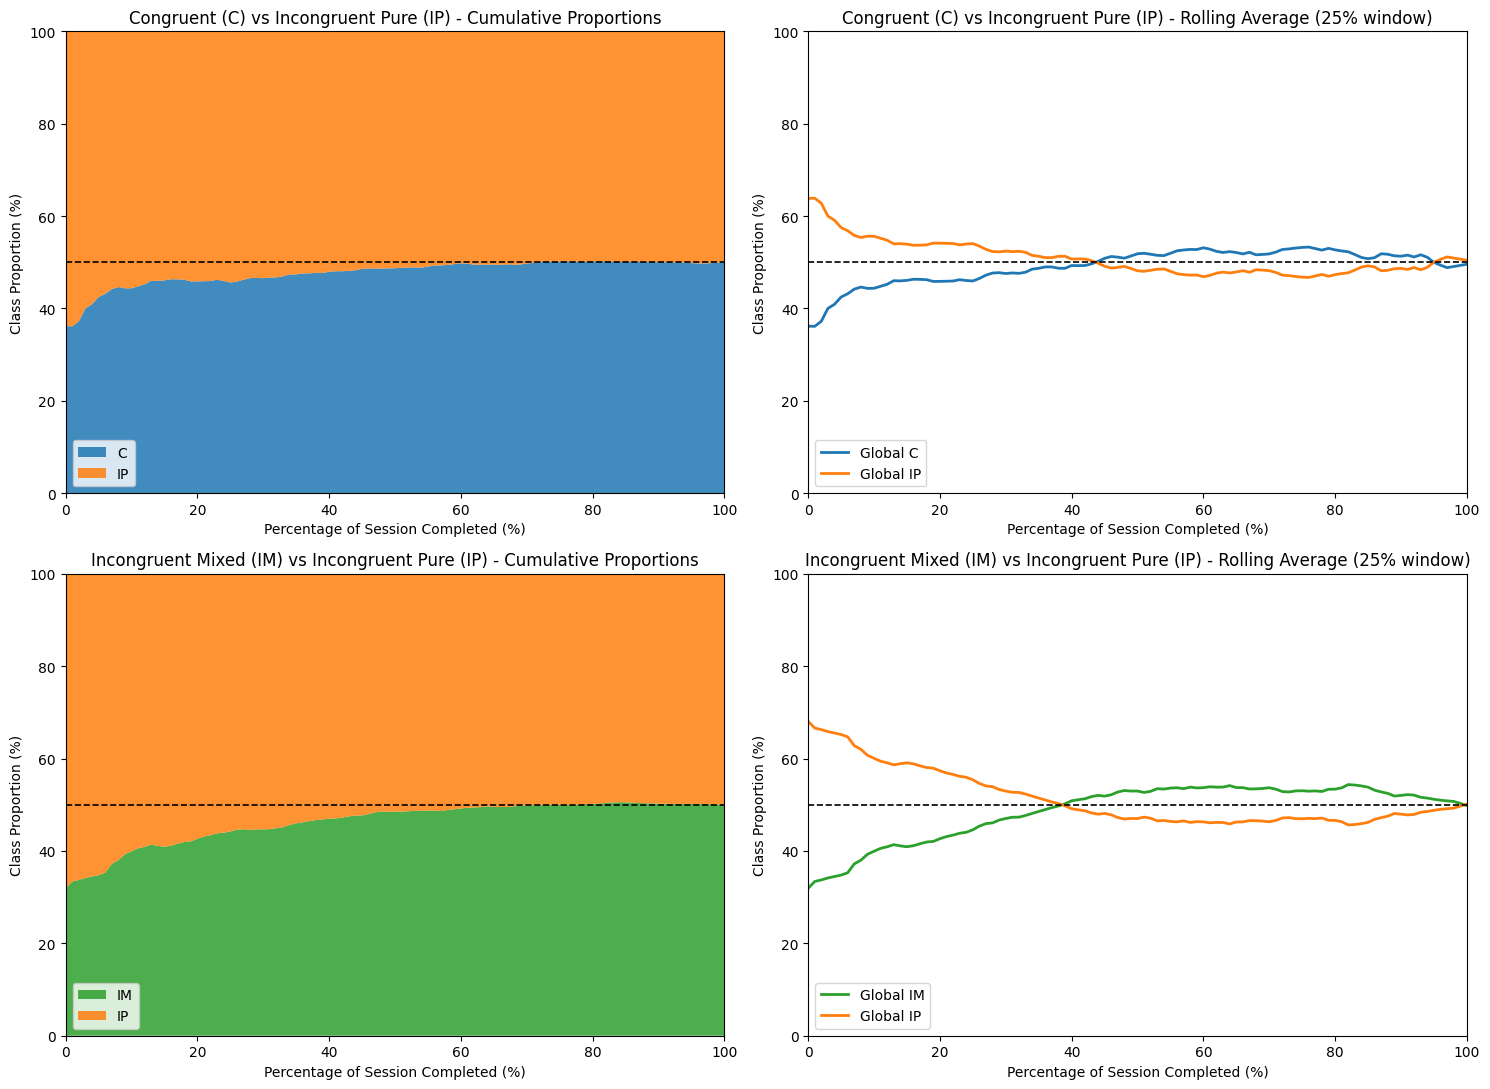

In [196]:
# 1.1 Class Proportions Over Time with Undersampling (C vs IP & IM vs IP)
# Here we plot how class proportions evolve chronologically after undersampling to balance total counts.

def undersample_proportions(y_in, random_state=42):
    classes, counts = np.unique(y_in, return_counts=True)
    if len(classes) < 2:
        return y_in
    n_min = counts.min()
    rng = np.random.default_rng(random_state)
    selected_idx = []
    for cls in classes:
        cls_idx = np.where(y_in == cls)[0]
        sampled = rng.choice(cls_idx, size=n_min, replace=False)
        selected_idx.extend(sampled.tolist())
    selected_idx = np.array(selected_idx)
    selected_idx.sort() # Keep relative chronological order!
    return y_in[selected_idx]

def get_cumulative_proportions(y_arr):
    n_epochs = len(y_arr)
    c0 = np.cumsum(y_arr == 0) / np.arange(1, n_epochs + 1)
    c1 = np.cumsum(y_arr == 1) / np.arange(1, n_epochs + 1)
    return c0, c1

def get_rolling_proportions(y_arr, window_percent=0.25):
    n_epochs = len(y_arr)
    W = max(1, int(window_percent * n_epochs))
    c0 = np.zeros(n_epochs)
    c1 = np.zeros(n_epochs)
    for t in range(n_epochs):
        start = max(0, t - W + 1)
        win = y_arr[start : t + 1]
        c0[t] = np.mean(win == 0)
        c1[t] = np.mean(win == 1)
    return c0, c1

CIPIM_COLORS = {"C": "#1f77b4", "IP": "#ff7f0e", "IM": "#2ca02c"}
grid_pct = np.linspace(0, 100, 101)

c_vs_ip_data = {}
im_vs_ip_data = {}

for fif_path in DATA_FILES:
    subj = fif_path.stem
    ep = mne.read_epochs(fif_path, preload=False, verbose=False)
    events = ep.events[:, 2]

    # 1. C vs IP
    c_mask = np.isin(events, COND_EVENTS_CODES["Congruent"])
    ip_mask = np.isin(events, COND_EVENTS_CODES["Incongruent_Pure"])
    if c_mask.any() and ip_mask.any():
        mask = c_mask | ip_mask
        y_raw = np.where(np.isin(events[mask], COND_EVENTS_CODES["Congruent"]), 0, 1).astype(np.int8)
        y_under = undersample_proportions(y_raw, random_state=42)
        c_vs_ip_data[subj] = y_under

    # 2. IM vs IP
    im_mask = np.isin(events, COND_EVENTS_CODES["Incongruent_Mixed"])
    if im_mask.any() and ip_mask.any():
        mask = im_mask | ip_mask
        y_raw = np.where(np.isin(events[mask], COND_EVENTS_CODES["Incongruent_Mixed"]), 0, 1).astype(np.int8)
        y_under = undersample_proportions(y_raw, random_state=42)
        im_vs_ip_data[subj] = y_under

def process_and_plot_task(axes, task_data, class0_name, class1_name, title_prefix):
    all_c0_c, all_c1_c = [], []
    all_c0_r, all_c1_r = [], []
    for y_arr in task_data.values():
        c0_c, c1_c = get_cumulative_proportions(y_arr)
        c0_r, c1_r = get_rolling_proportions(y_arr)
        n_subj = len(y_arr)
        pcts = np.linspace(0, 100, n_subj)
        all_c0_c.append(np.interp(grid_pct, pcts, c0_c))
        all_c1_c.append(np.interp(grid_pct, pcts, c1_c))
        all_c0_r.append(np.interp(grid_pct, pcts, c0_r))
        all_c1_r.append(np.interp(grid_pct, pcts, c1_r))
        
    mean_c0_c = np.mean(all_c0_c, axis=0)
    mean_c1_c = np.mean(all_c1_c, axis=0)
    mean_c0_r = np.mean(all_c0_r, axis=0)
    mean_c1_r = np.mean(all_c1_r, axis=0)
    
    # Left: Cumulative Stacked Area
    axes[0].stackplot(
        grid_pct,
        mean_c0_c * 100,
        mean_c1_c * 100,
        labels=[class0_name, class1_name],
        colors=[CIPIM_COLORS[class0_name], CIPIM_COLORS[class1_name]],
        alpha=0.85
    )
    axes[0].axhline(50, color="black", linestyle="--", linewidth=1.2)
    axes[0].set_xlim(0, 100)
    axes[0].set_ylim(0, 100)
    axes[0].set_xlabel("Percentage of Session Completed (%)")
    axes[0].set_ylabel("Class Proportion (%)")
    axes[0].set_title(f"{title_prefix} - Cumulative Proportions")
    axes[0].legend(loc="lower left")

    # Right: Rolling average lines
    axes[1].plot(grid_pct, mean_c0_r * 100, label=f"Global {class0_name}", color=CIPIM_COLORS[class0_name], linewidth=2)
    axes[1].plot(grid_pct, mean_c1_r * 100, label=f"Global {class1_name}", color=CIPIM_COLORS[class1_name], linewidth=2)
    axes[1].axhline(50, color="black", linestyle="--", linewidth=1.2)
    axes[1].set_xlim(0, 100)
    axes[1].set_ylim(0, 100)
    axes[1].set_xlabel("Percentage of Session Completed (%)")
    axes[1].set_ylabel("Class Proportion (%)")
    axes[1].set_title(f"{title_prefix} - Rolling Average (25% window)")
    axes[1].legend(loc="lower left")

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
# Row 1: C vs IP
process_and_plot_task(axes[0], c_vs_ip_data, "C", "IP", "Congruent (C) vs Incongruent Pure (IP)")
# Row 2: IM vs IP
process_and_plot_task(axes[1], im_vs_ip_data, "IM", "IP", "Incongruent Mixed (IM) vs Incongruent Pure (IP)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_proportion_dashboard.png", dpi=300)
plt.show()

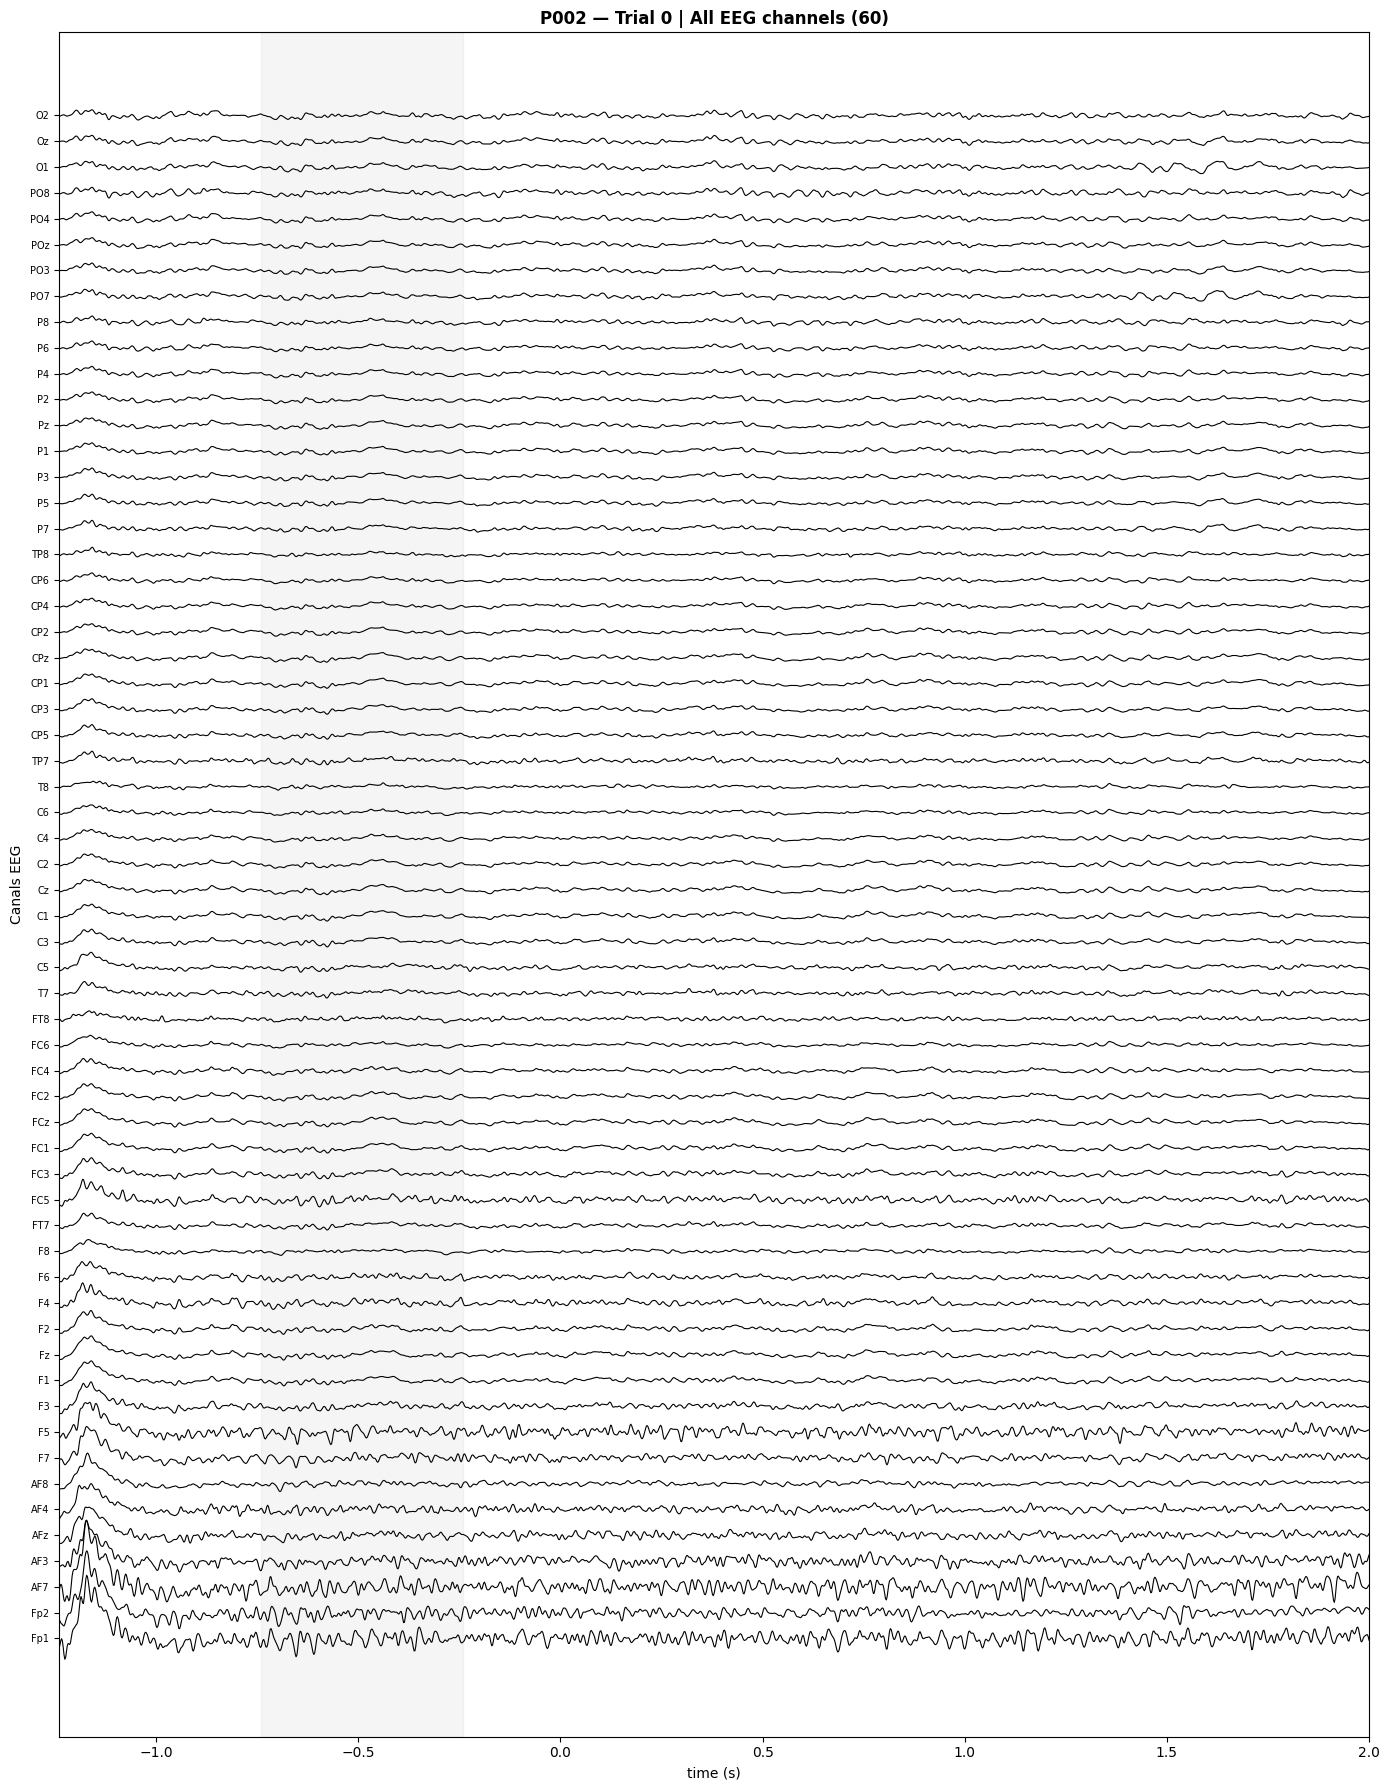

In [123]:
# List and plot all P002 EEG channels for a single trial
ep_eeg = epochs_all.copy().pick("eeg")

trial_idx = 0
data_uv = ep_eeg.get_data()[trial_idx] * 1e6  # (n_ch, n_times) en microvolts
times = ep_eeg.times
ch_names = ep_eeg.ch_names
n_ch = len(ch_names)

# Automatic vertical scaling so they don't overlap too much
ptp_per_ch = np.ptp(data_uv, axis=1)
step = np.median(ptp_per_ch) * 1.8
step = step if step > 0 else 10.0
offsets = np.arange(n_ch) * step

fig, ax = plt.subplots(figsize=(14, 18))
for i, ch in enumerate(ch_names):
    ax.plot(times, data_uv[i] + offsets[i], linewidth=0.8, color="black")

ax.set_yticks(offsets)
ax.set_yticklabels(ch_names, fontsize=7)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)

ax.set_xlim([times[0], times[-1]])
ax.set_xlabel("time (s)")
ax.set_ylabel("Canals EEG")
ax.set_title(f"{SUBJ} — Trial 0 | All EEG channels ({n_ch})", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "trial_0_tots_canals_eeg.png", dpi=300, bbox_inches="tight")
plt.show()

---

### Imbalance of classes
Visualization of the distribution of trials by class in the complete data set. This allows you to quickly see if there is an imbalance between Congruent, Pure Incongruent and Mixed Incongruent.

### Behavioral EDA (codes CRP/CGP/IPR/IPG/IM/...)

This section summarizes the behavioral codes (event_1..event_12) and analyzes ocular dominance in pure incongruent trials.

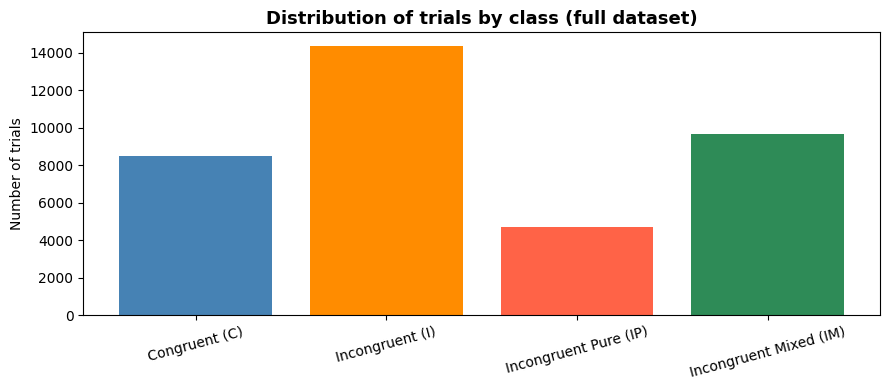

Saved table: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_subjectes.csv
Total count per class:
  Congruent (C) :  8471 trials ( 37.1%)
  Incongruent (I): 14367 trials ( 62.9%)
  Pure Incongruent (IP) :  4689 trials ( 20.5% of the total) |  32.6% of incongruities
  Incongruent Mixed (IM):  9678 trials ( 42.4% of the total) |  67.4% of incongruent)
  Errors                 :   189 trials (  0.8%)
  Total                  : 22838 trials


In [124]:
df_dominancia, comptes_classes, label_counts, globals_summary = build_behavior_dominance_summary(DATA_DIR)
im_global = label_counts["IM"]
ip_global = label_counts["IPR"] + label_counts["IPG"]
left_global = globals_summary["left_global"]
right_global = globals_summary["right_global"]
red_global = globals_summary["red_global"]
green_global = globals_summary["green_global"]

c_total = comptes_classes["Congruent"]
ip_total = comptes_classes["Incongruent_Pure"]
im_total = comptes_classes["Incongruent_Mixed"]
i_total = ip_total + im_total

display_labels = [
    "Congruent (C)",
    "Incongruent (I)",
    "Incongruent Pure (IP)",
    "Incongruent Mixed (IM)",
]
display_values = [c_total, i_total, ip_total, im_total]

plt.figure(figsize=(9, 4))
plt.bar(display_labels, display_values, color=["steelblue", "darkorange", "tomato", "seagreen"])
plt.title("Distribution of trials by class (full dataset)", fontsize=13, fontweight="bold")
plt.ylabel("Number of trials")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribucio_trials_per_classe_dataset_complet.png", dpi=300, bbox_inches="tight")
plt.show()

df_dominancia.to_csv(TABLES_DIR / "dominancia_subjectes.csv", index=False)
print(f"Saved table: {TABLES_DIR / 'dominancia_subjectes.csv'}")

total = c_total + i_total
print("Total count per class:")
print(f"  Congruent (C) : {c_total:5d} trials ({(100*c_total/total):5.1f}%)")
print(f"  Incongruent (I): {i_total:5d} trials ({(100*i_total/total):5.1f}%)")
print(
    f"  Pure Incongruent (IP) : {ip_total:5d} trials ({(100*ip_total/total):5.1f}% of the total) | {(100*ip_total/i_total):5.1f}% of incongruities"
)
print(
    f"  Incongruent Mixed (IM): {im_total:5d} trials ({(100*im_total/total):5.1f}% of the total) | {(100*im_total/i_total):5.1f}% of incongruent)"
)
print(
    f"  Errors                 : {comptes_classes['Errors']:5d} trials ({(100*comptes_classes['Errors']/total):5.1f}%)"
)
print(f"  Total                  : {total:5d} trials")

The Incongruent Pure class is the least represented, while Congruent and Incongruent Mixed have a similar amount of trials. This imbalance can affect analytics and predictive models, so it's important to be aware of it. Looking at the data, there are subjects that are more unbalanced than others. There are some that almost never have Incongruent Pure, but we do have a guaranteed 30 trials, as subjects with less than 30 trials per class were removed in preprocessing.

In [125]:
label_counts = {k: int(df_dominancia[k].sum()) for k in LABELS_ORDER}
im_global = int(df_dominancia["IM"].sum())
ip_global = int(df_dominancia["IPR"].sum() + df_dominancia["IPG"].sum())
left_global = int(df_dominancia["left_eye"].sum())
right_global = int(df_dominancia["right_eye"].sum())
red_global = int(df_dominancia["red_count"].sum())
green_global = int(df_dominancia["green_count"].sum())

print("Base dominance table prepared")
print(f"  Subjects: {len(df_dominancia)}")
print(f"  Global counts IM/IP: {im_global}/{ip_global}")
print(f"  Global eye counts (L/R): {left_global}/{right_global}")
print(f"  Global color counts (R/G): {red_global}/{green_global}")

Base dominance table prepared
  Subjects: 47
  Global counts IM/IP: 9678/4689
  Global eye counts (L/R): 2796/1893
  Global color counts (R/G): 7303/5896


In [126]:
cols_taula = [
    "subject",
    "CRP",
    "CRM",
    "CRG",
    "CGP",
    "CGM",
    "CGG",
    "IPR",
    "IPG",
    "IM",
    "left_eye",
    "right_eye",
    "dominance_index_im",
    "p_im_vs_ip",
    "dominance_index_eye",
    "p_eye",
    "red_count",
    "green_count",
    "dominance_index_color",
    "p_color",
]

df_taula = df_dominancia[cols_taula].copy()
df_taula = df_taula.rename(
    columns={
        "dominance_index_im": "Incongruent mixed dominance index",
        "dominance_index_eye": "Ocular dominance index",
        "dominance_index_color": "Color dominance index",
    }
)

df_taula["Incongruent mixed dominance index"] = df_taula["IM"] / (df_taula["IPR"] + df_taula["IPG"] + df_taula["IM"])
df_taula["Ocular dominance index"] = df_taula["Ocular dominance index"].round(3)
df_taula["Color dominance index"] = df_taula["Color dominance index"].round(3)
df_taula["p_im_vs_ip"] = df_taula.apply(
    lambda row: binomtest(row["IM"], n=row["IPR"] + row["IPG"] + row["IM"], p=0.5).pvalue, axis=1
)
df_taula["p_eye"] = df_taula["p_eye"].round(4)
df_taula["p_color"] = df_taula["p_color"].round(4)

df_taula.to_csv(TABLES_DIR / "dominancia_detall_subjectes.csv", index=False)
print(f"Saved table: {TABLES_DIR / 'dominancia_detall_subjectes.csv'}")

display(df_taula)
print(f"Table rows: {len(df_taula)}")

Saved table: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_detall_subjectes.csv


,subject,CRP,CRM,CRG,CGP,CGM,CGG,IPR,IPG,IM,left_eye,right_eye,Incongruent mixed dominance index,p_im_vs_ip,Ocular dominance index,p_eye,red_count,green_count,Color dominance index,p_color
0,P002,81,0,0,63,0,0,88,15,137,97,6,0.570833,3.294339e-02,0.883,0.0000,169,78,0.368,0.0000
1,P003,99,0,0,92,0,0,126,67,117,190,3,0.377419,1.870831e-05,0.969,0.0000,225,159,0.172,0.0009
2,P004,115,0,0,103,0,0,6,59,303,36,29,0.823370,7.541696e-38,0.108,0.4570,121,162,-0.145,0.0173
3,P005,84,3,0,82,2,1,72,49,169,68,53,0.582759,5.688236e-03,0.124,0.2029,157,131,0.090,0.1406
4,P008,51,2,2,39,2,0,40,18,100,36,22,0.632911,1.042566e-03,0.241,0.0869,91,59,0.213,0.0111
5,P009,115,1,2,109,0,1,90,31,236,81,40,0.661064,1.162603e-09,0.339,0.0002,206,142,0.184,0.0007
6,P010,125,0,0,122,0,0,133,24,219,74,83,0.582447,1.621028e-03,-0.057,0.5233,258,146,0.277,0.0000
7,P011,68,0,0,53,0,0,26,3,281,13,16,0.906452,5.553055e-53,-0.103,0.7111,94,56,0.253,0.0024
8,P013,118,0,0,107,0,0,13,146,193,90,69,0.548295,7.844524e-02,0.132,0.1124,131,253,-0.318,0.0000
9,P014,66,3,1,61,5,1,18,51,210,22,47,0.752688,1.007629e-17,-0.362,0.0035,85,113,-0.141,0.0547


Table rows: 47


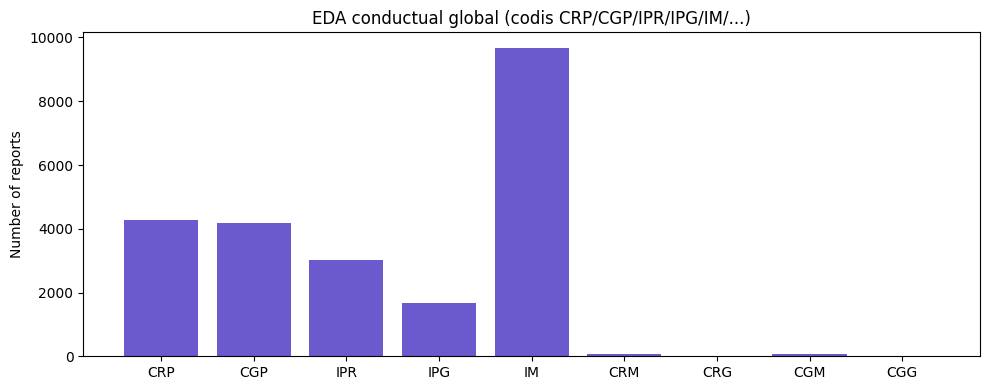

Global mean IM vs IP dominance index: 0.34
Global mean IM vs IP dominance index (absolute value): 0.47


C:\Users\nils\AppData\Local\Temp\ipykernel_19608\3565321644.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_dominancia["subject"], rotation=90)


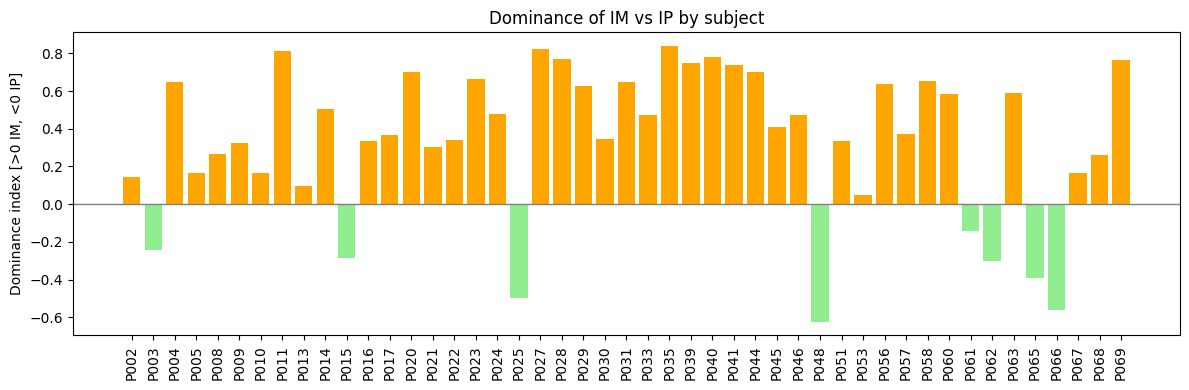

Global mean ocular dominance index: 0.16
Global mean ocular dominance index (absolute value): 0.35


C:\Users\nils\AppData\Local\Temp\ipykernel_19608\3565321644.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_dominancia["subject"], rotation=90)


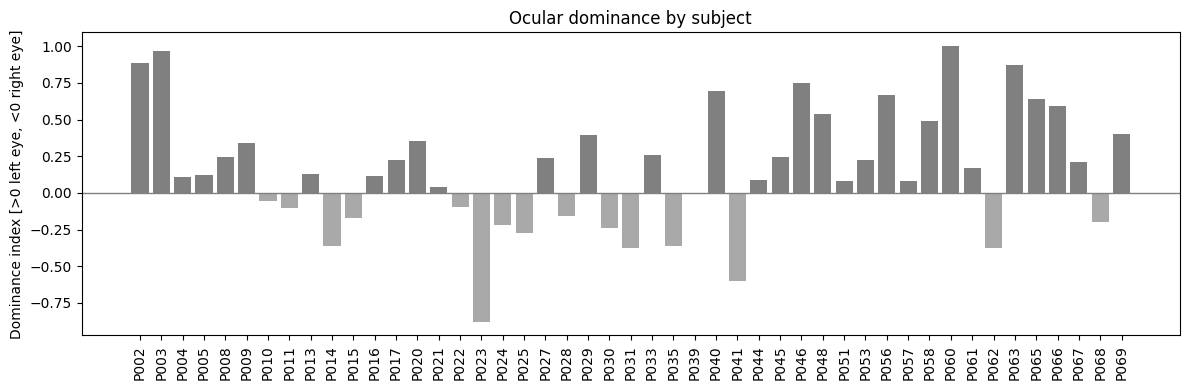

Global mean color dominance index: 0.11
Global mean color dominance index (absolute value): 0.17


C:\Users\nils\AppData\Local\Temp\ipykernel_19608\3565321644.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_dominancia["subject"], rotation=90)


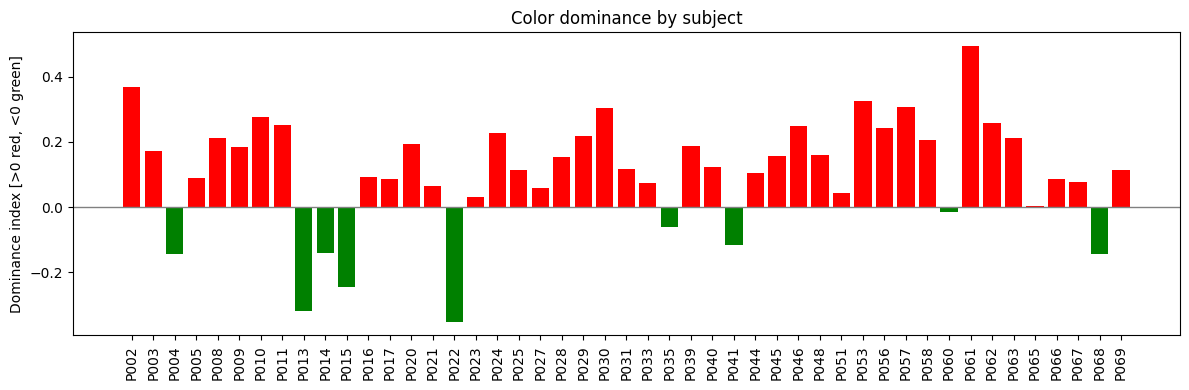

In [127]:
# Plot 1: global behavioral codes distribution
x = np.arange(len(LABELS_ORDER))
vals = [label_counts[k] for k in LABELS_ORDER]

plt.figure(figsize=(10, 4))
plt.bar(x, vals, color="slateblue")
plt.xticks(x, LABELS_ORDER)
plt.ylabel("Number of reports")
plt.title("EDA conductual global (codis CRP/CGP/IPR/IPG/IM/...)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_conductual_global_codis.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: Dominance index of IM vs IP by subject
df_dominancia["index_dominancia_IM_IP"] = (df_dominancia["IM"] - df_dominancia["IPR"] - df_dominancia["IPG"]) / (
    df_dominancia["IM"] + df_dominancia["IPR"] + df_dominancia["IPG"] + 1e-10
)
print(f"Global mean IM vs IP dominance index: {df_dominancia['index_dominancia_IM_IP'].mean():.2f}")
print(
    f"Global mean IM vs IP dominance index (absolute value): {df_dominancia['index_dominancia_IM_IP'].abs().mean():.2f}"
)
fig, ax = plt.subplots(figsize=(12, 4))
ax.axhline(0, color="gray", linewidth=1)
colors = ["orange" if x >= 0 else "lightgreen" for x in df_dominancia["index_dominancia_IM_IP"]]
ax.bar(df_dominancia["subject"], df_dominancia["index_dominancia_IM_IP"], color=colors)
ax.set_ylabel("Dominance index [>0 IM, <0 IP]")
ax.set_title("Dominance of IM vs IP by subject")
ax.set_xticklabels(df_dominancia["subject"], rotation=90)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "dominancia_IM_vs_IP_per_subjecte.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 3: ocular dominance index per subject
print(f"Global mean ocular dominance index: {df_dominancia['dominance_index_eye'].mean():.2f}")
print(f"Global mean ocular dominance index (absolute value): {df_dominancia['dominance_index_eye'].abs().mean():.2f}")
fig, ax = plt.subplots(figsize=(12, 4))
ax.axhline(0, color="gray", linewidth=1)
colors = ["grey" if x >= 0 else "darkgrey" for x in df_dominancia["dominance_index_eye"]]
ax.bar(df_dominancia["subject"], df_dominancia["dominance_index_eye"], color=colors)
ax.set_ylabel("Dominance index [>0 left eye, <0 right eye]")
ax.set_title("Ocular dominance by subject")
ax.set_xticklabels(df_dominancia["subject"], rotation=90)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "dominancia_ocular_per_subjecte_incongruent_pure.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 4: color dominance index by subject
print(f"Global mean color dominance index: {df_dominancia['dominance_index_color'].mean():.2f}")
print(f"Global mean color dominance index (absolute value): {df_dominancia['dominance_index_color'].abs().mean():.2f}")
fig, ax = plt.subplots(figsize=(12, 4))
ax.axhline(0, color="gray", linewidth=1)
colors = ["red" if x >= 0 else "green" for x in df_dominancia["dominance_index_color"]]
ax.bar(df_dominancia["subject"], df_dominancia["dominance_index_color"], color=colors)
ax.set_ylabel("Dominance index [>0 red, <0 green]")
ax.set_title("Color dominance by subject")
ax.set_xticklabels(df_dominancia["subject"], rotation=90)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "dominancia_color_per_subjecte_incongruent_pure.png", dpi=300, bbox_inches="tight")
plt.show()

In [128]:
im_vs_ip_test = binomtest(
    df_dominancia["IM"].sum(),
    n=df_dominancia["IM"].sum() + df_dominancia["IPR"].sum() + df_dominancia["IPG"].sum(),
    p=0.5,
    alternative="two-sided",
)
eye_test_global = binomtest(left_global, n=left_global + right_global, p=0.5, alternative="two-sided")
color_test_global = binomtest(red_global, n=red_global + green_global, p=0.5, alternative="two-sided")

im_vs_ip_ci = im_vs_ip_test.proportion_ci(confidence_level=0.95, method="exact")
eye_ci = eye_test_global.proportion_ci(confidence_level=0.95, method="exact")
color_ci = color_test_global.proportion_ci(confidence_level=0.95, method="exact")

p_im_vs_ip = im_global / (im_global + ip_total)
p_ull = left_global / (left_global + right_global)
p_color = red_global / (red_global + green_global)

idx_im_vs_ip_global = (im_global - ip_total) / (im_global + ip_total + 1e-10)
idx_ull_global = 2 * p_ull - 1
idx_color_global = 2 * p_color - 1

print("Global test of IM vs IP dominance")
print(f"  Incongruent Mixed (IM): {im_global}")
print(f"  Pure Incongruent (IP) : {ip_total}")
print(f"  IM ratio: {p_im_vs_ip:.3f} (IC95% [{im_vs_ip_ci.low:.3f}, {im_vs_ip_ci.high:.3f}])")
print(f"  Global index: {idx_im_vs_ip_global:.3f}")
print(f"  binomial p-value: {im_vs_ip_test.pvalue:.4e}")

print("\nGlobal test of ocular dominance (incongruent pure)")
print(f"  Left-eye coherent : {left_global}")
print(f"  Right-eye coherent: {right_global}")
print(f"  Left eye proportion: {p_ull:.3f} (IC95% [{eye_ci.low:.3f}, {eye_ci.high:.3f}])")
print(f"  Global index: {idx_ull_global:.3f}")
print(f"  binomial p-value : {eye_test_global.pvalue:.4e}")

print("\nGlobal test of color dominance")
print(f"  Red : {red_global}")
print(f"  Green : {green_global}")
print(f"  Red proportion: {p_color:.3f} (IC95% [{color_ci.low:.3f}, {color_ci.high:.3f}])")
print(f"  Global index: {idx_color_global:.3f}")
print(f"  binomial p-value : {color_test_global.pvalue:.4e}")

Global test of IM vs IP dominance
  Incongruent Mixed (IM): 9678
  Pure Incongruent (IP) : 4689
  IM ratio: 0.674 (IC95% [0.666, 0.681])
  Global index: 0.347
  binomial p-value: 0.0000e+00

Global test of ocular dominance (incongruent pure)
  Left-eye coherent : 2796
  Right-eye coherent: 1893
  Left eye proportion: 0.596 (IC95% [0.582, 0.610])
  Global index: 0.193
  binomial p-value : 7.3452e-40

Global test of color dominance
  Red : 7303
  Green : 5896
  Red proportion: 0.553 (IC95% [0.545, 0.562])
  Global index: 0.107
  binomial p-value : 1.6869e-34


In [129]:
# Explicit comparison: pooled/weighted vs macro-average
subj_im_ip = df_dominancia[df_dominancia["IM"] + df_dominancia["IPR"] + df_dominancia["IPG"] > 0].copy()
subj_ull = df_dominancia[df_dominancia["n_eye"] > 0].copy()
subj_color = df_dominancia[df_dominancia["n_color"] > 0].copy()

subj_im_ip["p_im_vs_ip_subj"] = subj_im_ip["IM"] / (subj_im_ip["IM"] + subj_im_ip["IPR"] + subj_im_ip["IPG"])
subj_ull["p_left_subj"] = subj_ull["left_eye"] / subj_ull["n_eye"]
subj_color["p_red_subj"] = subj_color["red_count"] / subj_color["n_color"]

# Pooled (equivalent to weighted by n)
p_im_vs_ip_pooled = im_global / (im_global + ip_total)
p_ull_pooled = left_global / (left_global + right_global)
p_color_pooled = red_global / (red_global + green_global)

# Macro-average (same weight per subject)
p_im_vs_ip_macro = subj_im_ip["p_im_vs_ip_subj"].mean()
p_ull_macro = subj_ull["p_left_subj"].mean()
p_color_macro = subj_color["p_red_subj"].mean()

# Explicit weighted-average (must match pooled)
p_im_vs_ip_weighted = np.average(
    subj_im_ip["p_im_vs_ip_subj"], weights=subj_im_ip["IM"] + subj_im_ip["IPR"] + subj_im_ip["IPG"]
)
p_ull_weighted = np.average(subj_ull["p_left_subj"], weights=subj_ull["n_eye"])
p_color_weighted = np.average(subj_color["p_red_subj"], weights=subj_color["n_color"])

print("Comparison of global measures")
print("\n  IM vs IP dominance (IM proportion):")
print(f"    Pooled / weighted by n : {p_im_vs_ip_pooled:.4f}")
print(f"    Weighted average        : {p_im_vs_ip_weighted:.4f}")
print(f"    Macro-average           : {p_im_vs_ip_macro:.4f}")
print(f"    Difference macro-pooled : {p_im_vs_ip_macro - p_im_vs_ip_pooled:+.4f}")

print("\n  Ocular dominance (left eye proportion):")
print(f"    Pooled / weighted by n : {p_ull_pooled:.4f}")
print(f"    Weighted average        : {p_ull_weighted:.4f}")
print(f"    Macro-average           : {p_ull_macro:.4f}")
print(f"    Difference macro-pooled : {p_ull_macro - p_ull_pooled:+.4f}")

print("\n  Color dominance (red proportion):")
print(f"    Pooled / weighted by n : {p_color_pooled:.4f}")
print(f"    Weighted average        : {p_color_weighted:.4f}")
print(f"    Macro-average           : {p_color_macro:.4f}")
print(f"    Difference macro-pooled : {p_color_macro - p_color_pooled:+.4f}")

Comparison of global measures

  IM vs IP dominance (IM proportion):
    Pooled / weighted by n : 0.6736
    Weighted average        : 0.6736
    Macro-average           : 0.6707
    Difference macro-pooled : -0.0029

  Ocular dominance (left eye proportion):
    Pooled / weighted by n : 0.5963
    Weighted average        : 0.5963
    Macro-average           : 0.5819
    Difference macro-pooled : -0.0143

  Color dominance (red proportion):
    Pooled / weighted by n : 0.5533
    Weighted average        : 0.5533
    Macro-average           : 0.5542
    Difference macro-pooled : +0.0009


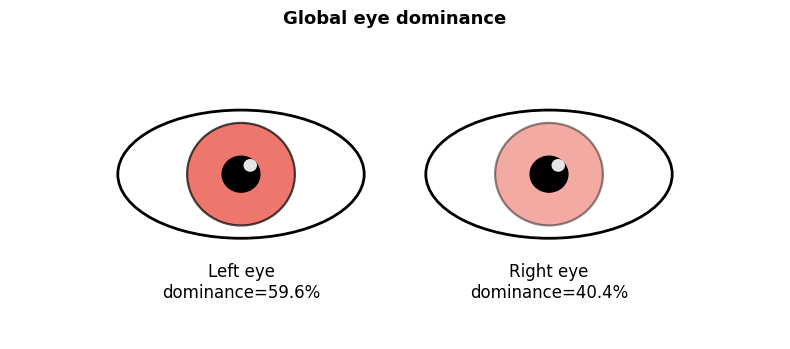

Summary used for the eye plot
  Left eye: trials=2796, share=0.596, red=0.643, opacity=0.706
  Right eye: trials=1893, share=0.404, red=0.640, opacity=0.444


In [130]:
# Global visual dominance (eyes + color), with independent rendering per eye
left_red = int(df_dominancia["left_red"].sum())
left_green = int(df_dominancia["left_green"].sum())
right_red = int(df_dominancia["right_red"].sum())
right_green = int(df_dominancia["right_green"].sum())

left_total = max(left_red + left_green, 1)
right_total = max(right_red + right_green, 1)
grand_total = max(left_total + right_total, 1)
left_red_ratio = left_red / left_total
right_red_ratio = right_red / right_total
left_share = left_total / grand_total
right_share = right_total / grand_total

dominance_boost = 1.6
left_strength = np.clip(0.5 + dominance_boost * (left_share - 0.5), 0, 1)
right_strength = np.clip(0.5 + dominance_boost * (right_share - 0.5), 0, 1)
left_iris_alpha = 0.15 + 0.85 * left_strength
right_iris_alpha = 0.15 + 0.85 * right_strength

# Both eyes stay red; the only strong visual difference is opacity
shared_red_rgb = np.array([0.87, 0.18, 0.16])
shared_warm_rgb = np.array([0.96, 0.36, 0.25])
left_tint = 0.35 + 0.08 * np.clip((left_red_ratio - 0.5) * 2, -1, 1)
right_tint = 0.35 + 0.08 * np.clip((right_red_ratio - 0.5) * 2, -1, 1)
left_iris_color = (1 - left_tint) * shared_red_rgb + left_tint * shared_warm_rgb
right_iris_color = (1 - right_tint) * shared_red_rgb + right_tint * shared_warm_rgb

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 4.2)
ax.axis("off")


def draw_eye(cx, cy, width, height, iris_color, iris_alpha):
    sclera = Ellipse((cx, cy), width, height, facecolor="white", edgecolor="black", linewidth=2, alpha=1.0)
    iris = Circle(
        (cx, cy), radius=height * 0.40, facecolor=iris_color, edgecolor="black", linewidth=1.6, alpha=iris_alpha
    )
    pupil = Circle((cx, cy), radius=height * 0.14, facecolor="black", edgecolor="black", linewidth=1)
    glare = Circle((cx + 0.12, cy + 0.12), radius=height * 0.05, facecolor="white", edgecolor="none", alpha=0.9)
    ax.add_patch(sclera)
    ax.add_patch(iris)
    ax.add_patch(pupil)
    ax.add_patch(glare)


draw_eye(3.0, 2.25, 3.2, 1.75, left_iris_color, left_iris_alpha)
draw_eye(7.0, 2.25, 3.2, 1.75, right_iris_color, right_iris_alpha)

ax.text(3.0, 1.05, f"Left eye\ndominance={left_share*100:.1f}%", ha="center", va="top", fontsize=12)
ax.text(7.0, 1.05, f"Right eye\ndominance={right_share*100:.1f}%", ha="center", va="top", fontsize=12)

ax.set_title("Global eye dominance", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "dominancia_global_ull_color_gradient.png", dpi=300, bbox_inches="tight")
plt.show()

print("Summary used for the eye plot")
print(
    f"  Left eye: trials={left_total}, share={left_share:.3f}, red={left_red_ratio:.3f}, opacity={left_iris_alpha:.3f}"
)
print(
    f"  Right eye: trials={right_total}, share={right_share:.3f}, red={right_red_ratio:.3f}, opacity={right_iris_alpha:.3f}"
)

#### Stylized display of global dominance (eyes)

This graph represents two eyes: the opacity of each eye encodes ocular dominance (left/right) and the iris color encodes color dominance (red/green), modulated by overall statistical evidence.

Subjects with significant bias (p < 0.05):
  IM vs IP: 45/47
  Eye   : 28/47
  Color : 29/47


Saved table: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\dominancia_significanca_subjectes.csv


,subject,left_eye,right_eye,dominance_index_im,ci95_im_vs_ip_low,ci95_im_vs_ip_high,p_im_vs_ip,predominant_im,sig_im_vs_ip,Ocular dominance index,...,predominant_eye,sig_eye,red_count,green_count,Color dominance index,95% CI color (low),95% CI color (high),p_color,predominant_color,sig_color
0,P002,97,6,0.141667,0.505581,0.634314,3.294339e-02,Incongruent Mixed,True,0.883495,...,Left,True,169,78,0.368421,0.622257,0.741677,6.990574e-09,Red,True
1,P003,190,3,-0.245161,0.323247,0.433958,1.870831e-05,Incongruous Pure,True,0.968912,...,Left,True,225,159,0.171875,0.534865,0.635675,8.864316e-04,Red,True
2,P004,36,29,0.646739,0.780489,0.860954,7.541696e-38,Incongruent Mixed,True,0.107692,...,Left,False,121,162,-0.144876,0.369183,0.487473,1.726415e-02,Green,True
3,P005,68,53,0.165517,0.523677,0.640131,5.688236e-03,Incongruent Mixed,True,0.123967,...,Left,False,157,131,0.090278,0.485681,0.603659,1.405792e-01,Red,False
4,P008,36,22,0.265823,0.552652,0.708083,1.042566e-03,Incongruent Mixed,True,0.241379,...,Left,False,91,59,0.213333,0.523685,0.685347,1.112159e-02,Red,True
5,P009,81,40,0.322129,0.609381,0.710050,1.162603e-09,Incongruent Mixed,True,0.338843,...,Left,True,206,142,0.183908,0.538279,0.644050,7.100480e-04,Red,True
6,P010,74,83,0.164894,0.530784,0.632801,1.621028e-03,Incongruent Mixed,True,-0.057325,...,Right,False,258,146,0.277228,0.589650,0.685530,2.744343e-08,Red,True
7,P011,13,16,0.812903,0.868415,0.936452,5.553055e-53,Incongruent Mixed,True,-0.103448,...,Right,False,94,56,0.253333,0.544036,0.704188,2.405516e-03,Red,True
8,P013,90,69,0.096591,0.494666,0.601106,7.844524e-02,Incongruent Mixed,False,0.132075,...,Left,False,131,253,-0.317708,0.293811,0.390952,4.773196e-10,Green,True
9,P014,22,47,0.505376,0.697740,0.802182,1.007629e-17,Incongruent Mixed,True,-0.362319,...,Right,True,85,113,-0.141414,0.359350,0.501385,5.473388e-02,Green,False


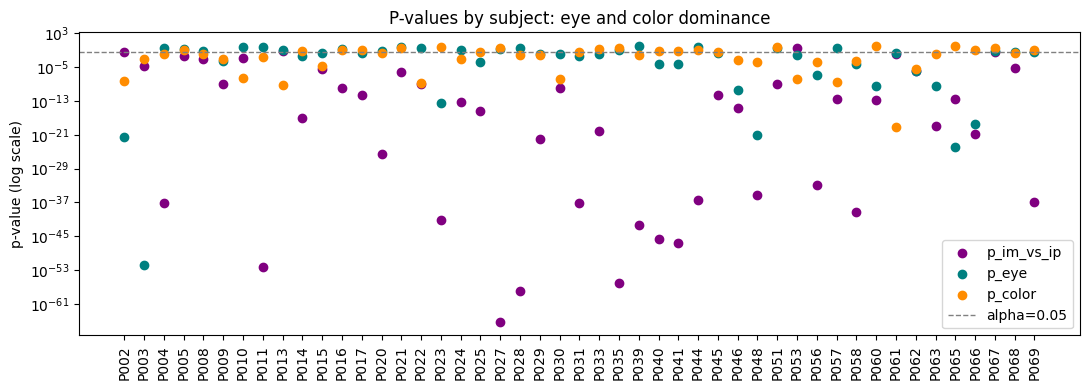

In [131]:
# Preference criteria (descriptive only)
df_stats = df_dominancia.copy()
df_stats["dominance_index_im"] = (df_stats["IM"] - df_stats["IPR"] - df_stats["IPG"]) / (
    df_stats["IM"] + df_stats["IPR"] + df_stats["IPG"] + 1e-10
)
df_stats["predominant_im"] = np.where(
    df_stats["dominance_index_im"] > 0,
    "Incongruent Mixed",
    np.where(df_stats["dominance_index_im"] < 0, "Incongruous Pure", "Balanced"),
)
df_stats["predominant_eye"] = np.where(
    df_stats["dominance_index_eye"] > 0,
    "Left",
    np.where(df_stats["dominance_index_eye"] < 0, "Right", "Balanced"),
)
df_stats["predominant_color"] = np.where(
    df_stats["dominance_index_color"] > 0,
    "Red",
    np.where(df_stats["dominance_index_color"] < 0, "Green", "Balanced"),
)

# Exact 95% CIs per subject (if not from main dataframe)
if "ci95_eye_low" not in df_stats.columns:
    df_stats[["ci95_im_vs_ip_low", "ci95_im_vs_ip_high"]] = df_stats.apply(
        lambda r: pd.Series(row_binom_ci(r["IM"], r["IM"] + r["IPR"] + r["IPG"])), axis=1
    )
    df_stats[["ci95_eye_low", "ci95_eye_high"]] = df_stats.apply(
        lambda r: pd.Series(row_binom_ci(r["left_eye"], r["n_eye"])), axis=1
    )
    df_stats[["ci95_color_low", "ci95_color_high"]] = df_stats.apply(
        lambda r: pd.Series(row_binom_ci(r["red_count"], r["n_color"])),
        axis=1,
    )

m_im_ip = int((df_stats["IM"] + df_stats["IPR"] + df_stats["IPG"] > 0).sum())
m_ull = int((df_stats["n_eye"] > 0).sum())
m_color = int((df_stats["n_color"] > 0).sum())
df_stats["sig_im_vs_ip"] = (df_stats["p_im_vs_ip"] < 0.05) & (df_stats["IM"] > 0)
df_stats["sig_eye"] = (df_stats["p_eye"] < 0.05) & (df_stats["n_eye"] > 0)
df_stats["sig_color"] = (df_stats["p_color"] < 0.05) & (df_stats["n_color"] > 0)

print("Subjects with significant bias (p < 0.05):")
print(f"  IM vs IP: {int(df_stats['sig_im_vs_ip'].sum())}/{m_im_ip}")
print(f"  Eye   : {int(df_stats['sig_eye'].sum())}/{m_ull}")
print(f"  Color : {int(df_stats['sig_color'].sum())}/{m_color}")

cols_stats = [
    "subject",
    "left_eye",
    "right_eye",
    "dominance_index_im",
    "ci95_im_vs_ip_low",
    "ci95_im_vs_ip_high",
    "p_im_vs_ip",
    "predominant_im",
    "sig_im_vs_ip",
    "dominance_index_eye",
    "ci95_eye_low",
    "ci95_eye_high",
    "p_eye",
    "predominant_eye",
    "sig_eye",
    "red_count",
    "green_count",
    "dominance_index_color",
    "ci95_color_low",
    "ci95_color_high",
    "p_color",
    "predominant_color",
    "sig_color",
]

df_stats_show = (
    df_stats[cols_stats]
    .rename(
        columns={
            "dominance_index_eye": "Ocular dominance index",
            "ci95_eye_low": "95% CI eye (low)",
            "ci95_eye_high": "95% CI eye (high)",
            "dominance_index_color": "Color dominance index",
            "ci95_color_low": "95% CI color (low)",
            "ci95_color_high": "95% CI color (high)",
        }
    )
    .sort_values("subject")
    .reset_index(drop=True)
)

df_stats_show.to_csv(TABLES_DIR / "dominancia_significanca_subjectes.csv", index=False)
print(f"Saved table: {TABLES_DIR / 'dominancia_significanca_subjectes.csv'}")

display(df_stats_show)

# Mini-view of p-values ​​for quick inspection
plt.figure(figsize=(11, 4))
plt.scatter(df_stats["subject"], df_stats["p_im_vs_ip"], label="p_im_vs_ip", color="purple")
plt.scatter(df_stats["subject"], df_stats["p_eye"], label="p_eye", color="teal")
plt.scatter(df_stats["subject"], df_stats["p_color"], label="p_color", color="darkorange")
plt.axhline(0.05, color="gray", linestyle="--", linewidth=1, label="alpha=0.05")
plt.yscale("log")
plt.ylabel("p-value (log scale)")
plt.title("P-values by subject: eye and color dominance")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p_valors_dominancia_ull_color_per_subjecte.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 2: Dominance and research questions (initial phase)

This blog extends dominance analysis with visualizations of confidence intervals by subject and pooled vs macro-average comparison.

In [132]:
# Q1-Q2: individual significance (simple criterion p<0.05)
df_infer = df_dominancia.copy()

m_im_ip = int((df_infer["IM"] + df_infer["IPR"] + df_infer["IPG"] > 0).sum())
m_ull = int((df_infer["n_eye"] > 0).sum())
m_color = int((df_infer["n_color"] > 0).sum())

print("Significance by subject")
print(f"  Eye          p<0.05 : {int((df_infer['p_eye'] < 0.05).sum())}/{m_ull}")
print(f"  Color        p<0.05 : {int((df_infer['p_color'] < 0.05).sum())}/{m_color}")
print(f"  IM sobre IP  p<0.05 : {int((df_infer['p_im_vs_ip'] < 0.05).sum())}/{m_im_ip}")

Significance by subject
  Eye          p<0.05 : 28/47
  Color        p<0.05 : 29/47
  IM sobre IP  p<0.05 : 45/47


### Forest plot by subject (proportion + CI95%)

Visual comparison of ocular dominance and color by subject, with exact confidence intervals.

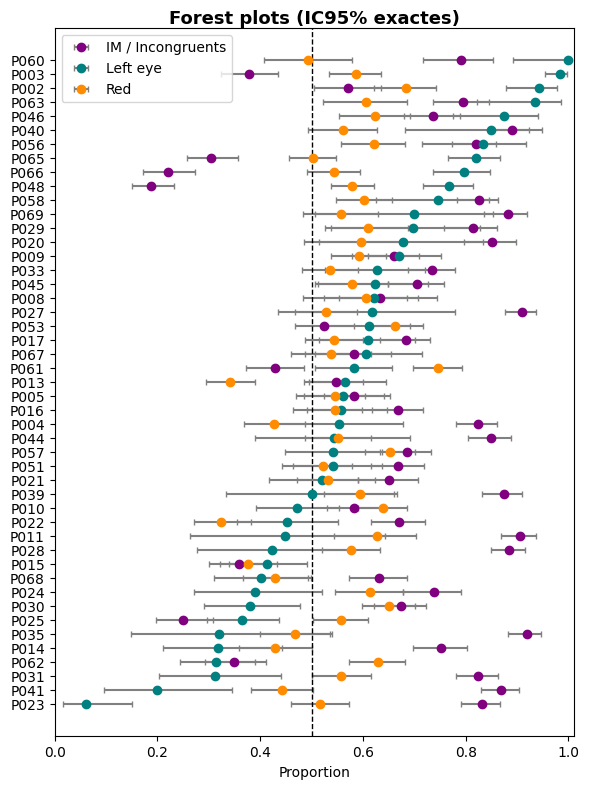

In [133]:
# Construction of forest plot data (eye and color) reusing already calculated IC95%
forest = df_dominancia.copy()
forest["p_im_vs_ip"] = forest["IM"] / (forest["IM"] + forest["IPR"] + forest["IPG"])
forest["p_left"] = forest["left_eye"] / forest["n_eye"]
forest["p_red"] = forest["red_count"] / forest["n_color"]

# Minimum guarantee for compatibility with old versions of the dataframe
if "ci95_eye_low" not in forest.columns:
    forest[["ci95_im_vs_ip_low", "ci95_im_vs_ip_high"]] = forest.apply(
        lambda r: pd.Series(row_binom_ci(r["IM"], r["IM"] + r["IPR"] + r["IPG"])), axis=1
    )
    forest[["ci95_eye_low", "ci95_eye_high"]] = forest.apply(
        lambda r: pd.Series(row_binom_ci(r["left_eye"], r["n_eye"])),
        axis=1,
    )
    forest[["ci95_color_low", "ci95_color_high"]] = forest.apply(
        lambda r: pd.Series(row_binom_ci(r["red_count"], r["n_color"])),
        axis=1,
    )

forest = forest.sort_values("p_left").reset_index(drop=True)
y = np.arange(len(forest))

fig, ax = plt.subplots(figsize=(6, 8))

# Forest plot of IM vs. IP dominance (IM ratio)
x_im_ip = forest["p_im_vs_ip"].values
xerr_im_ip = np.vstack([x_im_ip - forest["ci95_im_vs_ip_low"].values, forest["ci95_im_vs_ip_high"].values - x_im_ip])
ax.errorbar(x_im_ip, y, xerr=xerr_im_ip, fmt="o", color="purple", ecolor="gray", capsize=2, label="IM / Incongruents")

# Ocular dominance
x = forest["left_eye"] / forest["n_eye"]
xerr = np.vstack([x - forest["ci95_eye_low"].values, forest["ci95_eye_high"].values - x])
ax.errorbar(x, y, xerr=xerr, fmt="o", color="teal", ecolor="gray", capsize=2, label="Left eye")

# Predominance of color
x = forest["red_count"] / forest["n_color"]
xerrc = np.vstack([x - forest["ci95_color_low"].values, forest["ci95_color_high"].values - x])
ax.errorbar(x, y, xerr=xerrc, fmt="o", color="darkorange", ecolor="gray", capsize=2, label="Red")

ax.set_xlim(0, 1.01)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Proportion")
ax.set_yticks(y)
ax.set_yticklabels(forest["subject"])
ax.legend(loc="upper left")
ax.set_title("Forest plots (IC95% exactes)", y=0.995, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "forest_plots_ic95_exactes.png", dpi=300, bbox_inches="tight")
plt.show()

### Matrix of correlations between biases

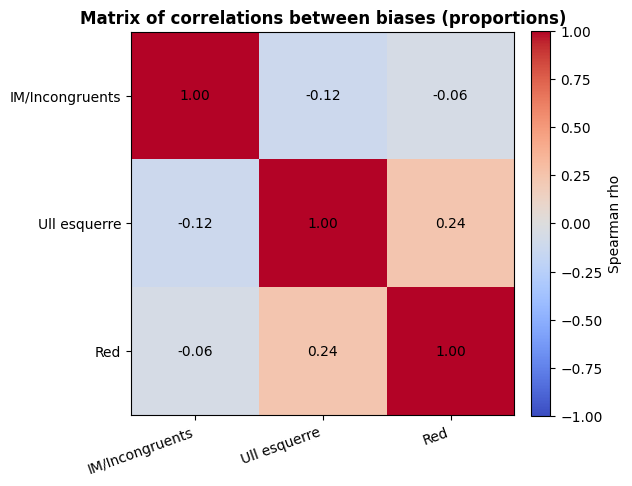

In [134]:
# Correlation between biases in proportion: IM/Incongruent, left eye and red
corr_prop = subj_ull.copy()

corr_prop["p_im_incongruents"] = corr_prop["IM"] / (corr_prop["IM"] + corr_prop["IPR"] + corr_prop["IPG"])
corr_prop["p_left_eye"] = corr_prop["left_eye"] / corr_prop["n_eye"]
corr_prop["p_red"] = corr_prop["red_count"] / corr_prop["n_color"]

corr_prop = (
    corr_prop[["subject", "p_im_incongruents", "p_left_eye", "p_red"]].replace([np.inf, -np.inf], np.nan).dropna()
)

rho_iu, p_iu = spearmanr(corr_prop["p_im_incongruents"], corr_prop["p_left_eye"])
rho_iv, p_iv = spearmanr(corr_prop["p_im_incongruents"], corr_prop["p_red"])
rho_uv, p_uv = spearmanr(corr_prop["p_left_eye"], corr_prop["p_red"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].scatter(corr_prop["p_im_incongruents"], corr_prop["p_left_eye"], color="mediumpurple", alpha=0.8)
axes[0].set_xlabel("Proportion IM / incongruent")
axes[0].set_ylabel("Left eye proportion")
axes[0].set_title(f"IM vs Left eye (rho={rho_iu:.2f}, p={p_iu:.3g})")
axes[0].grid(alpha=0.2)

axes[1].scatter(corr_prop["p_im_incongruents"], corr_prop["p_red"], color="darkorange", alpha=0.8)
axes[1].set_xlabel("Proportion IM / incongruent")
axes[1].set_ylabel("Network ratio")
axes[1].set_title(f"IM vs Red (rho={rho_iv:.2f}, p={p_iv:.3g})")
axes[1].grid(alpha=0.2)

axes[2].scatter(corr_prop["p_left_eye"], corr_prop["p_red"], color="teal", alpha=0.8)
axes[2].set_xlabel("Left eye proportion")
axes[2].set_ylabel("Network ratio")
axes[2].set_title(f"Left eye vs Red (rho={rho_uv:.2f}, p={p_uv:.3g})")
axes[2].grid(alpha=0.2)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

fig.suptitle("Correlation between biases (proportions)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.close(fig)  # hide scatter plots: we make matrix instead of plots

cols_corr = ["p_im_incongruents", "p_left_eye", "p_red"]
corr_matrix = corr_prop[cols_corr].corr(method="spearman")

# Matrix of p-values
p_matrix = pd.DataFrame(np.nan, index=cols_corr, columns=cols_corr)
for i, c1 in enumerate(cols_corr):
    for j, c2 in enumerate(cols_corr):
        if i == j:
            p_matrix.loc[c1, c2] = 0.0
        else:
            _, p = spearmanr(corr_prop[c1], corr_prop[c2])
            p_matrix.loc[c1, c2] = p

# Desa taules
corr_matrix.to_csv(TABLES_DIR / "matriu_correlacions_biaixos_proporcio_spearman.csv")
p_matrix.to_csv(TABLES_DIR / "matriu_pvalors_biaixos_proporcio_spearman.csv")

# Plot of the correlation matrix
labels = ["IM/Incongruents", "Ull esquerre", "Red"]
fig_mat, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr_matrix.values, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        r = corr_matrix.values[i, j]
        p = p_matrix.values[i, j]
        star = "*" if (i != j and p < 0.05) else ""
        ax.text(j, i, f"{r:.2f}{star}", ha="center", va="center", color="black", fontsize=10)

cbar = fig_mat.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Spearman rho")
ax.set_title("Matrix of correlations between biases (proportions)", fontweight="bold")
fig_mat.tight_layout()
plt.savefig(FIGURES_DIR / "matriu_correlacions_biaixos_proporcio_spearman.png", dpi=300, bbox_inches="tight")
plt.show()

### Matrix of correlations between intensity of biases

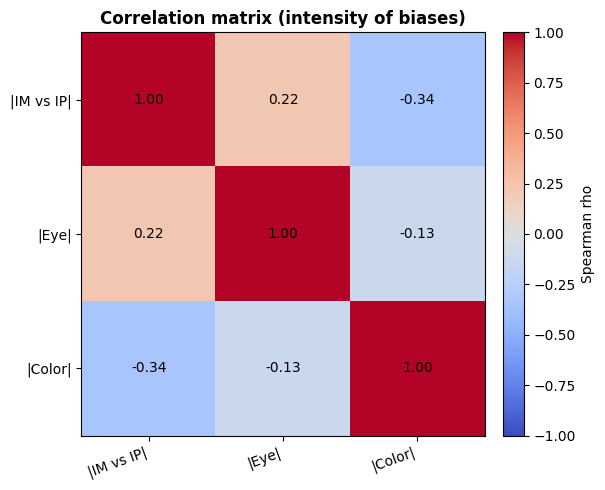

In [135]:
# Correlation matrix based on the intensity (absolute value) of the biases
df_intensitat = subj_ull.copy()

cols_src = ["dominance_index_im", "dominance_index_eye", "dominance_index_color"]

corr_int = (
    df_intensitat[cols_src]
    .abs()
    .rename(
        columns={
            "dominance_index_im": "int_IM_vs_IP",
            "dominance_index_eye": "int_ull",
            "dominance_index_color": "int_color",
        }
    )
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

corr_matrix = corr_int.corr(method="spearman")

# Guardar taules
corr_matrix.to_csv(TABLES_DIR / "matriu_correlacions_intensitat_biaixos_spearman.csv")

# Plot
labels = ["|IM vs IP|", "|Eye|", "|Color|"]
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr_matrix.values, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        r = corr_matrix.values[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", color="black", fontsize=10)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Spearman rho")
ax.set_title("Correlation matrix (intensity of biases)", fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "matriu_correlacions_intensitat_biaixos_spearman.png", dpi=300, bbox_inches="tight")
plt.show()

### Average per subject (macro-average)

We show a simple estimate with the **normal mean per subject** of the dominance ratio (eye and color), with 95% bootstrap CI.

Normal mean by subject (macro-average)
  IM vs IP (IM ratio) : 0.6707  IC95% [0.6142, 0.7238]
  Eye   (left proportion): 0.5819  IC95% [0.5246, 0.6405]
  Color (red ratio): 0.5542  IC95% [0.5296, 0.5782]


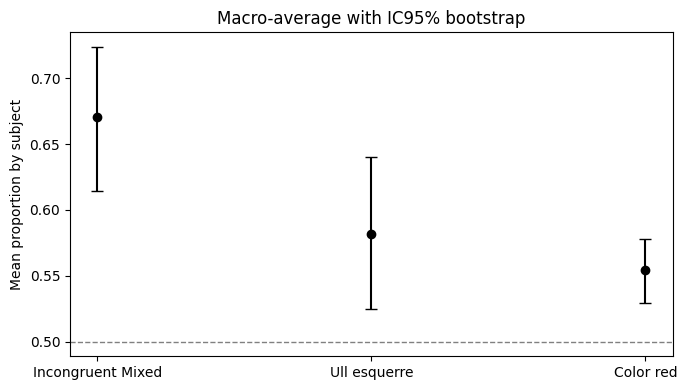

In [136]:
rng = np.random.default_rng(42)


def bootstrap_macro_ci(success_col, total_col, n_boot=5000):
    d = df_dominancia[[success_col, total_col]].dropna().copy()
    d = d[d[total_col] > 0].reset_index(drop=True)
    p_subj = d[success_col] / d[total_col]
    macro = p_subj.mean()

    boot = np.empty(n_boot)
    n = len(p_subj)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[i] = p_subj.iloc[idx].mean()

    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
    return macro, ci_low, ci_high


df_dominancia["IM_IP_total"] = df_dominancia["IM"] + df_dominancia["IPR"] + df_dominancia["IPG"]
macro_im_ip, im_ip_lo, im_ip_hi = bootstrap_macro_ci("IM", "IM_IP_total")
macro_ull, ull_lo, ull_hi = bootstrap_macro_ci("left_eye", "n_eye")
macro_color, col_lo, col_hi = bootstrap_macro_ci("red_count", "n_color")

print("Normal mean by subject (macro-average)")
print(f"  IM vs IP (IM ratio) : {macro_im_ip:.4f}  IC95% [{im_ip_lo:.4f}, {im_ip_hi:.4f}]")
print(f"  Eye   (left proportion): {macro_ull:.4f}  IC95% [{ull_lo:.4f}, {ull_hi:.4f}]")
print(f"  Color (red ratio): {macro_color:.4f}  IC95% [{col_lo:.4f}, {col_hi:.4f}]")

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Incongruent Mixed", "Ull esquerre", "Color red"]
means = [macro_im_ip, macro_ull, macro_color]
ci_low_err = [macro_im_ip - im_ip_lo, macro_ull - ull_lo, macro_color - col_lo]
ci_high_err = [im_ip_hi - macro_im_ip, ull_hi - macro_ull, col_hi - macro_color]
ax.errorbar(labels, means, yerr=[ci_low_err, ci_high_err], fmt="o", color="black", capsize=4)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("Mean proportion by subject")
ax.set_title("Macro-average with IC95% bootstrap")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "macro_average_ic95_bootstrap.png", dpi=300, bbox_inches="tight")
plt.show()

### Relationship between ocular and color dominance

Question: Do the most eye-dominant subjects also tend to be the most color-dominant?

Dominance correlations (Spearman)
  Eye vs Color   : rho = 0.240 | p = 0.104
  Eye vs IM_vs_IP: rho = -0.117 | p = 0.433
  Color vs IM_vs_IP: rho = -0.059 | p = 0.692


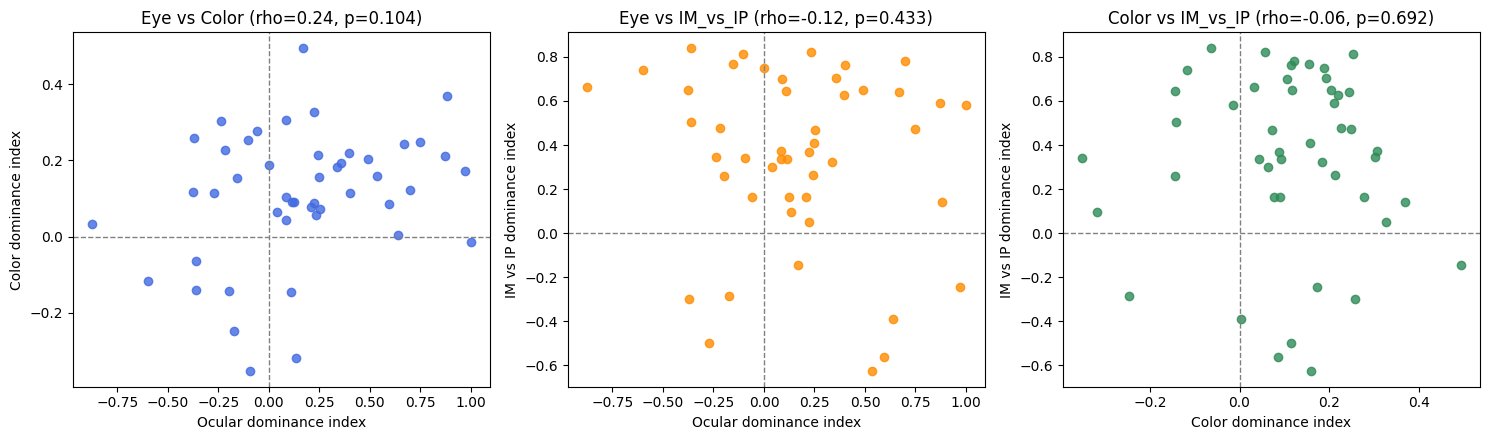

In [137]:
# We also add IM vs IP dominance
im_col = "dominance_index_im"

corr_df = df_dominancia[["subject", "dominance_index_eye", "dominance_index_color", im_col]].dropna()

rho_uc, p_uc = spearmanr(corr_df["dominance_index_eye"], corr_df["dominance_index_color"])
rho_ui, p_ui = spearmanr(corr_df["dominance_index_eye"], corr_df[im_col])
rho_ci, p_ci = spearmanr(corr_df["dominance_index_color"], corr_df[im_col])

print("Dominance correlations (Spearman)")
print(f"  Eye vs Color   : rho = {rho_uc:.3f} | p = {p_uc:.3f}")
print(f"  Eye vs IM_vs_IP: rho = {rho_ui:.3f} | p = {p_ui:.3f}")
print(f"  Color vs IM_vs_IP: rho = {rho_ci:.3f} | p = {p_ci:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].scatter(corr_df["dominance_index_eye"], corr_df["dominance_index_color"], color="royalblue", alpha=0.8)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("Ocular dominance index")
axes[0].set_ylabel("Color dominance index")
axes[0].set_title(f"Eye vs Color (rho={rho_uc:.2f}, p={p_uc:.3f})")

axes[1].scatter(corr_df["dominance_index_eye"], corr_df[im_col], color="darkorange", alpha=0.8)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("Ocular dominance index")
axes[1].set_ylabel("IM vs IP dominance index")
axes[1].set_title(f"Eye vs IM_vs_IP (rho={rho_ui:.2f}, p={p_ui:.3f})")

axes[2].scatter(corr_df["dominance_index_color"], corr_df[im_col], color="seagreen", alpha=0.8)
axes[2].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[2].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[2].set_xlabel("Color dominance index")
axes[2].set_ylabel("IM vs IP dominance index")
axes[2].set_title(f"Color vs IM_vs_IP (rho={rho_ci:.2f}, p={p_ci:.3f})")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlacions_dominancia_ull_color_im_vs_ip.png", dpi=300, bbox_inches="tight")
plt.show()

## Histograms of classes by subject

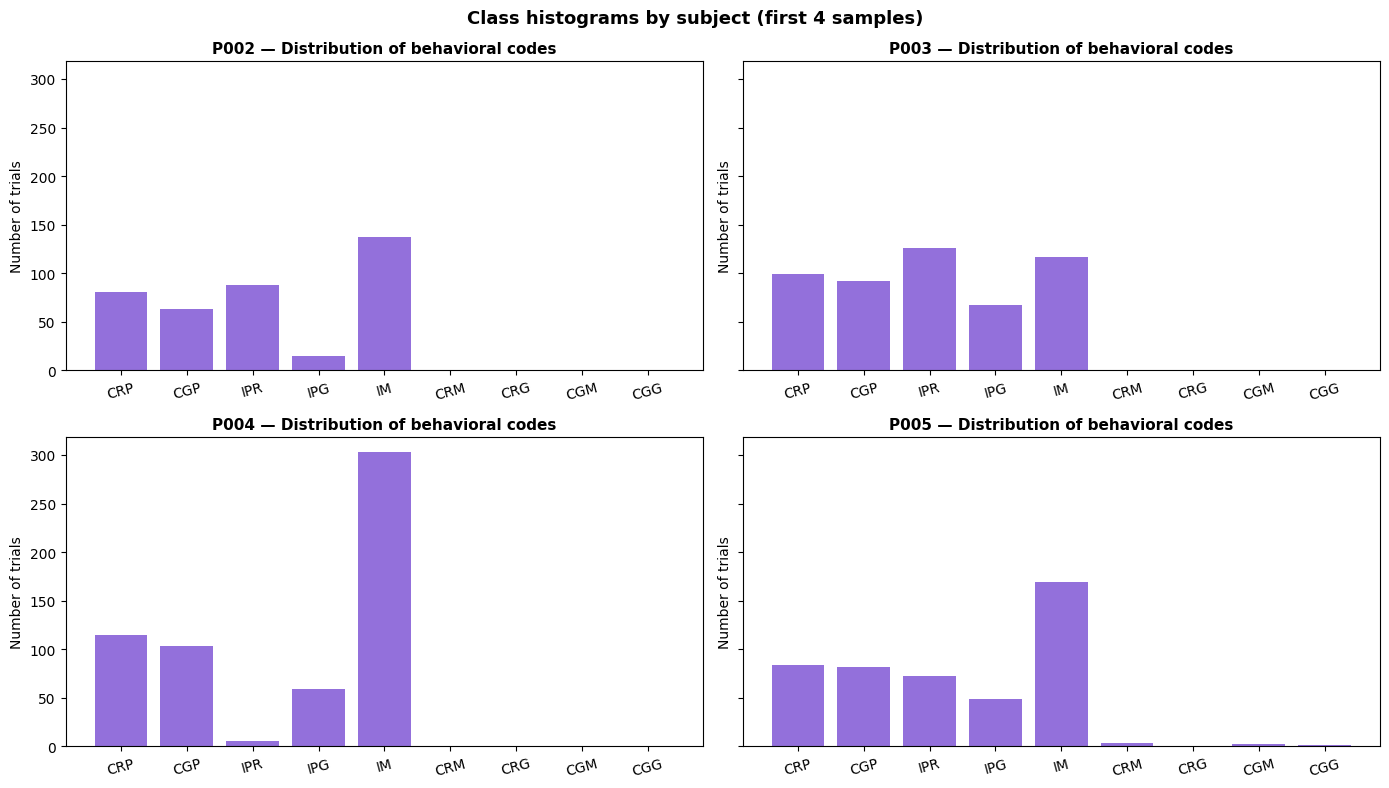

In [138]:
# Histograms of classes by subject in a single figure (2x2 grid)
subjects_plot = df_dominancia["subject"].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.flatten()

for ax, subj in zip(axes, subjects_plot):
    subj_data = df_dominancia[df_dominancia["subject"] == subj]
    counts = subj_data[LABELS_ORDER].values.flatten()
    ax.bar(LABELS_ORDER, counts, color="mediumpurple")
    ax.set_title(f"{subj} — Distribution of behavioral codes", fontsize=11, fontweight="bold")
    ax.set_ylabel("Number of trials")
    ax.tick_params(axis="x", rotation=15)

fig.suptitle("Class histograms by subject (first 4 samples)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "histogrames_classes_per_subjecte_grid_2x2.png", dpi=300, bbox_inches="tight")
plt.show()

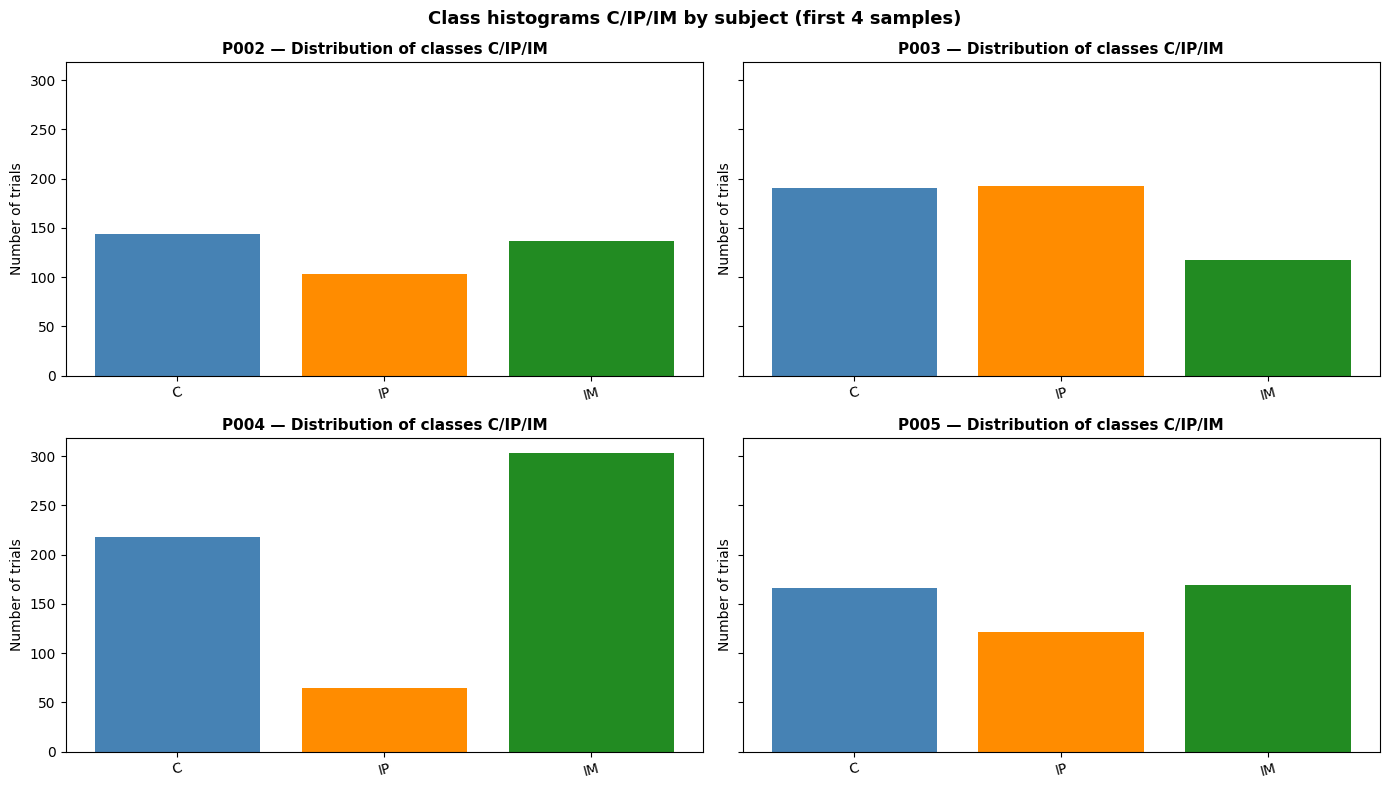

In [139]:
# Histograms of classes by subject (C, IP, IM) in a single figure (2x2 grid)
subjectes_plot = df_dominancia["subject"].head(4).tolist()
classes_plot = ["C", "IP", "IM"]

class_map = {
    "C": ["CRP", "CGP"],
    "IP": ["IPR", "IPG"],
    "IM": ["IM"],
}
class_colors = {
    "C": "steelblue",
    "IP": "darkorange",
    "IM": "forestgreen",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.flatten()
for ax, subj in zip(axes, subjects_plot):
    subj_data = df_dominancia[df_dominancia["subject"] == subj]
    counts = [float(subj_data[class_map[cls]].sum(axis=1).iloc[0]) for cls in classes_plot]

    ax.bar(classes_plot, counts, color=[class_colors[c] for c in classes_plot])
    ax.set_title(f"{subj} — Distribution of classes C/IP/IM", fontsize=11, fontweight="bold")
    ax.set_ylabel("Number of trials")
    ax.tick_params(axis="x", rotation=15)

# If there are less than 4 subjects, hide empty subplots
for ax in axes[len(subjectes_plot) :]:
    ax.axis("off")

fig.suptitle("Class histograms C/IP/IM by subject (first 4 samples)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "histogrames_classes_c_ip_im_per_subjecte_grid_2x2.png", dpi=300, bbox_inches="tight")
plt.show()

### Complementary analysis C/IP/IM (subject + global)

This blog adds plots to better see the relationship between C, IP and IM:
1. Pattern by subject in percentage (stacked) and heatmap.
2. Overall distribution between subjects (boxplot + mean with CI95%).
3. Trends sorted by subject.
4. Correlations between C/IP/IM ratios.

In [140]:
# Shared configuration C/IP/IM + summary table (linear execution)
CIPIM_CLASSES = ["C", "IP", "IM"]
CIPIM_CLASS_MAP = {
    "C": ["CRP", "CGP"],
    "IP": ["IPR", "IPG"],
    "IM": ["IM"],
}
CIPIM_COLORS = {
    "C": "steelblue",
    "IP": "darkorange",
    "IM": "forestgreen",
}

df_cipim = pd.DataFrame({"subject": df_dominancia["subject"]})
for cls in CIPIM_CLASSES:
    df_cipim[cls] = df_dominancia[CIPIM_CLASS_MAP[cls]].sum(axis=1)

df_cipim["total_cipim"] = df_cipim[CIPIM_CLASSES].sum(axis=1)
for cls in CIPIM_CLASSES:
    df_cipim[f"p_{cls}"] = df_cipim[cls] / df_cipim["total_cipim"]

df_cipim = df_cipim.sort_values("subject").reset_index(drop=True)

In [141]:
df_cipim.to_csv(TABLES_DIR / "c_ip_im_resum_subjectes.csv", index=False)
print(f"Saved table: {TABLES_DIR / 'c_ip_im_resum_subjectes.csv'}")
print(f"Included subjects: {len(df_cipim)}")

display(df_cipim.head())

Saved table: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\c_ip_im_resum_subjectes.csv
Included subjects: 47


,subject,C,IP,IM,total_cipim,p_C,p_IP,p_IM
0,P002,144,103,137,384,0.375000,0.268229,0.356771
1,P003,191,193,117,501,0.381238,0.385230,0.233533
2,P004,218,65,303,586,0.372014,0.110922,0.517065
3,P005,166,121,169,456,0.364035,0.265351,0.370614
4,P008,90,58,100,248,0.362903,0.233871,0.403226


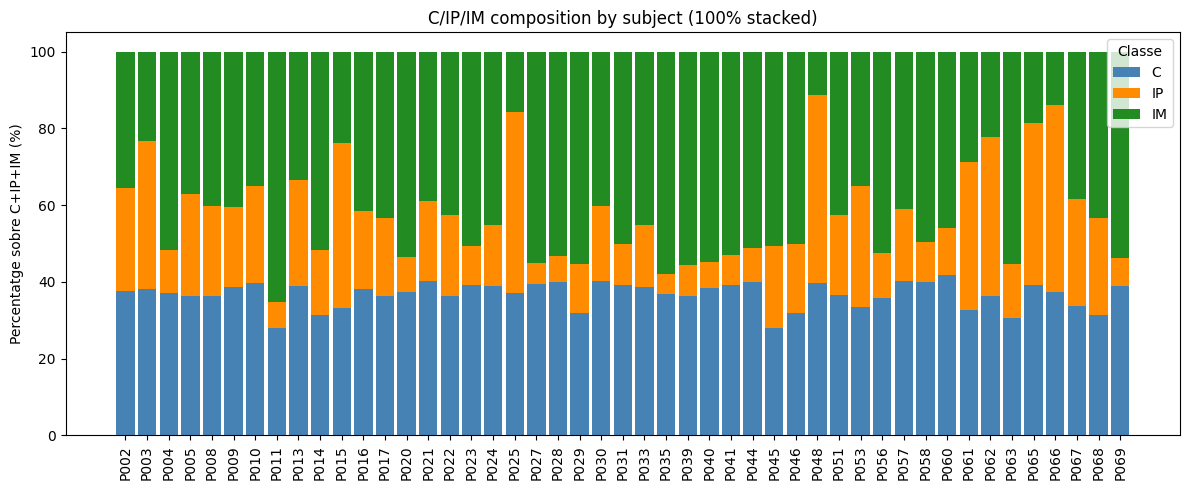

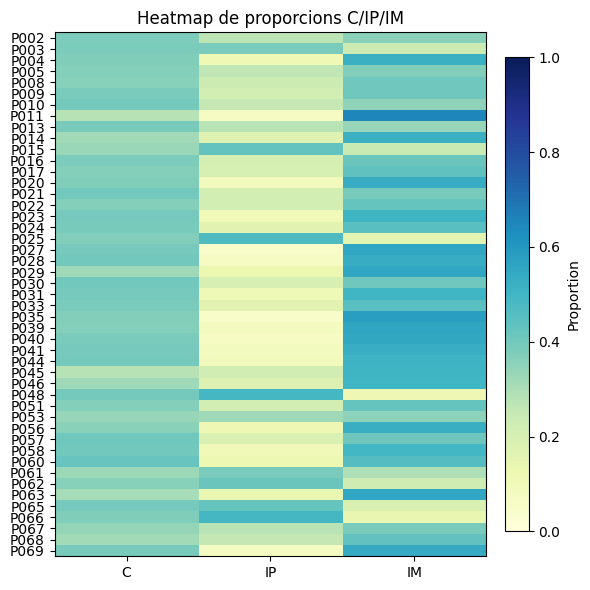

In [143]:
# Plot 1A: stacked bar in percentage by subject
subjectes = df_cipim["subject"].tolist()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(subjectes))
bottom = np.zeros(len(subjectes))

for cls in CIPIM_CLASSES:
    vals = df_cipim[f"p_{cls}"].values * 100
    ax.bar(x, vals, bottom=bottom, label=cls, color=CIPIM_COLORS[cls], width=0.85)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(subjectes, rotation=90)
ax.set_ylabel("Percentatge sobre C+IP+IM (%)")
ax.set_title("C/IP/IM composition by subject (100% stacked)")
ax.legend(title="Classe")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_subjecte_stacked_percentatge.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 1B: heatmap of proportions per subject
heat_data = df_cipim[["p_C", "p_IP", "p_IM"]].values

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(heat_data, aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(np.arange(len(CIPIM_CLASSES)))
ax.set_xticklabels(CIPIM_CLASSES)
ax.set_yticks(np.arange(len(subjectes)))
ax.set_yticklabels(subjectes)
ax.set_title("Heatmap de proporcions C/IP/IM")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.04, label="Proportion")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_subjecte_heatmap_proporcions.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\nils\AppData\Local\Temp\ipykernel_19608\1214867425.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(values, labels=labels_cls, patch_artist=True)


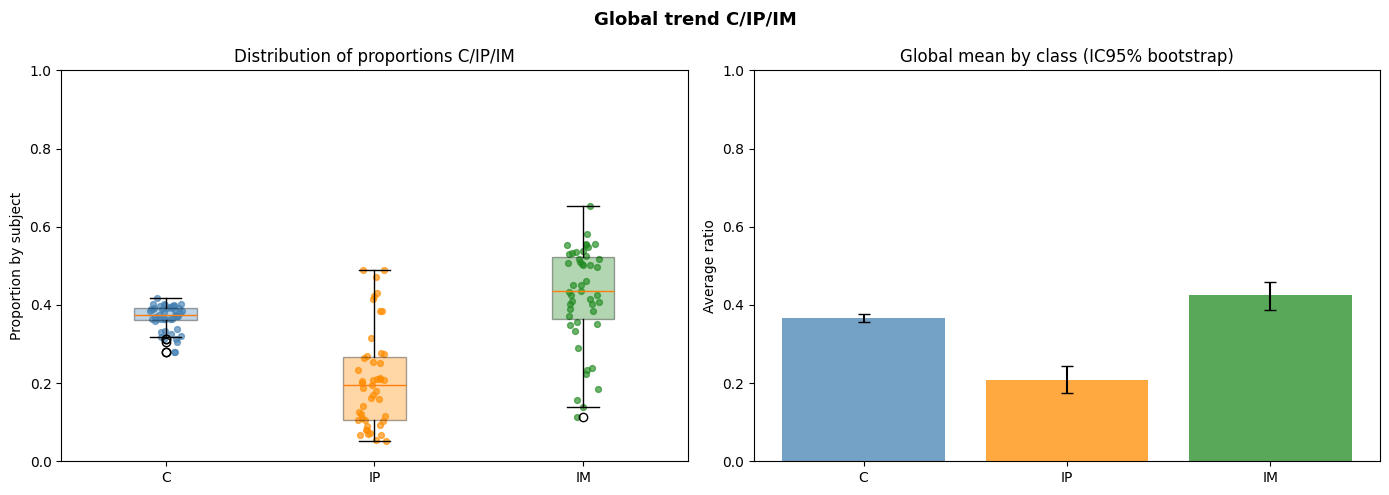

In [144]:
# Plot 2: global distribution between subjects (boxplot + mean with CI95%)
prop_cols = [f"p_{cls}" for cls in CIPIM_CLASSES]
labels_cls = CIPIM_CLASSES
values = [df_cipim[c].dropna().values for c in prop_cols]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (A) Boxplot + punts individuals
bp = axes[0].boxplot(values, labels=labels_cls, patch_artist=True)
for patch, cls in zip(bp["boxes"], labels_cls):
    patch.set_facecolor(CIPIM_COLORS[cls])
    patch.set_alpha(0.35)

rng_local = np.random.default_rng(42)
for i, (cls, vals) in enumerate(zip(labels_cls, values), start=1):
    jitter = rng_local.uniform(-0.08, 0.08, size=len(vals))
    axes[0].scatter(np.full(len(vals), i) + jitter, vals, color=CIPIM_COLORS[cls], alpha=0.65, s=18)

axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Proportion by subject")
axes[0].set_title("Distribution of proportions C/IP/IM")

# (B) Mitjana global + IC95% bootstrap
means = []
ci_low = []
ci_high = []
boot_n = 4000
for vals in values:
    vals = np.asarray(vals)
    means.append(vals.mean())
    boot = np.empty(boot_n)
    n = len(vals)
    for i in range(boot_n):
        idx = rng_local.integers(0, n, size=n)
        boot[i] = vals[idx].mean()
    lo, hi = np.percentile(boot, [2.5, 97.5])
    ci_low.append(means[-1] - lo)
    ci_high.append(hi - means[-1])

x = np.arange(len(labels_cls))
axes[1].bar(x, means, color=[CIPIM_COLORS[c] for c in labels_cls], alpha=0.75)
axes[1].errorbar(x, means, yerr=[ci_low, ci_high], fmt="none", ecolor="black", capsize=4)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels_cls)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Average ratio")
axes[1].set_title("Global mean by class (IC95% bootstrap)")

fig.suptitle("Global trend C/IP/IM", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_global_distribucio_i_ic95.png", dpi=300, bbox_inches="tight")
plt.show()

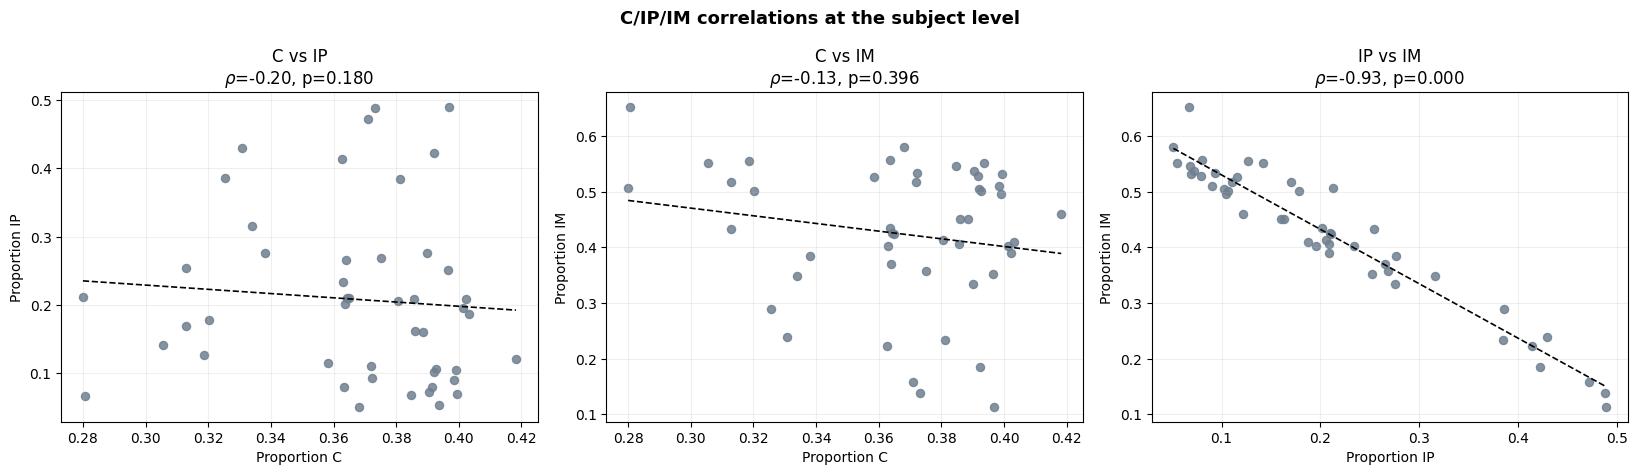

In [145]:
# Plot 3: subject-level correlations (scatter + Spearman)
corr_pairs = [
    ("p_C", "p_IP", "C", "IP"),
    ("p_C", "p_IM", "C", "IM"),
    ("p_IP", "p_IM", "IP", "IM"),
]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), sharex=False, sharey=False)

for ax, (x_col, y_col, x_lab, y_lab) in zip(axes, corr_pairs):
    x_vals = df_cipim[x_col].values
    y_vals = df_cipim[y_col].values

    rho, p_val = spearmanr(x_vals, y_vals)

    ax.scatter(x_vals, y_vals, color="slategray", alpha=0.85, s=34)

    # Linear trend line as a visual guide only.
    m, b = np.polyfit(x_vals, y_vals, 1)
    x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
    ax.plot(x_line, m * x_line + b, color="black", linewidth=1.2, linestyle="--")

    ax.set_xlabel(f"Proportion {x_lab}")
    ax.set_ylabel(f"Proportion {y_lab}")
    ax.set_title(f"{x_lab} vs {y_lab}\n$\\rho$={rho:.2f}, p={p_val:.3f}")
    ax.grid(alpha=0.2)

fig.suptitle("C/IP/IM correlations at the subject level", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_correlacions_nivell_subjecte_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

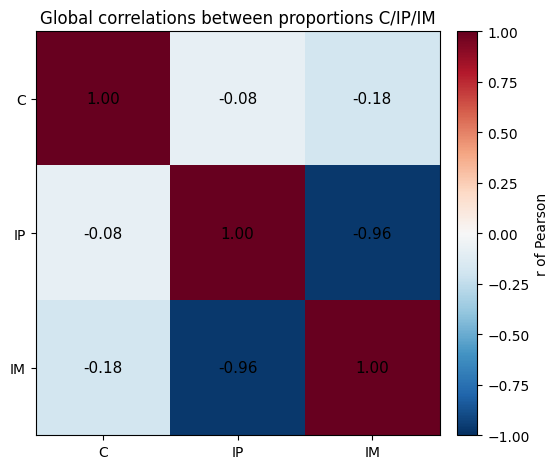

In [146]:
# Plot 4: matrix of correlations between C/IP/IM ratios
corr_mat = df_cipim[["p_C", "p_IP", "p_IM"]].corr().values
labels = CIPIM_CLASSES

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(corr_mat, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr_mat[i, j]:.2f}", ha="center", va="center", color="black", fontsize=11)

ax.set_title("Global correlations between proportions C/IP/IM")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.04, label="r of Pearson")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cipim_correlacions_proporcions.png", dpi=300, bbox_inches="tight")
plt.show()

### Harmonic average and class balance

Before Cohen's d, this blog shows how the **harmonic mean** captures the imbalance between C, IP and IM:
- goes down hard when a class is small,
- is close to the actual counts when the 3 classes are balanced.

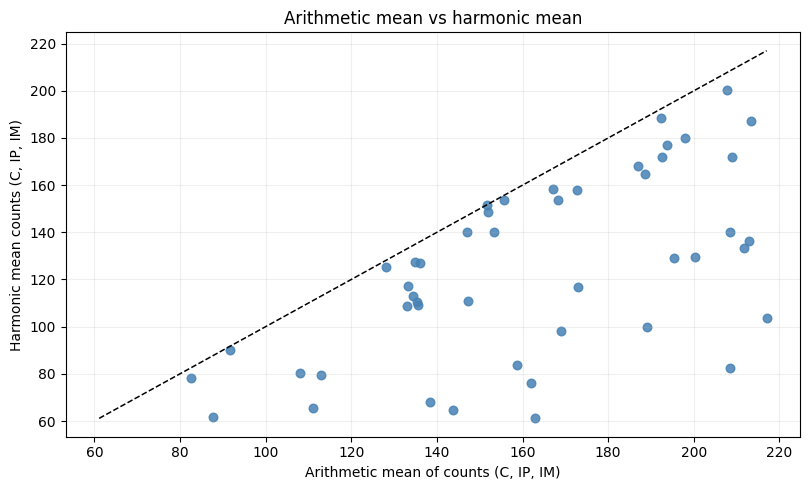

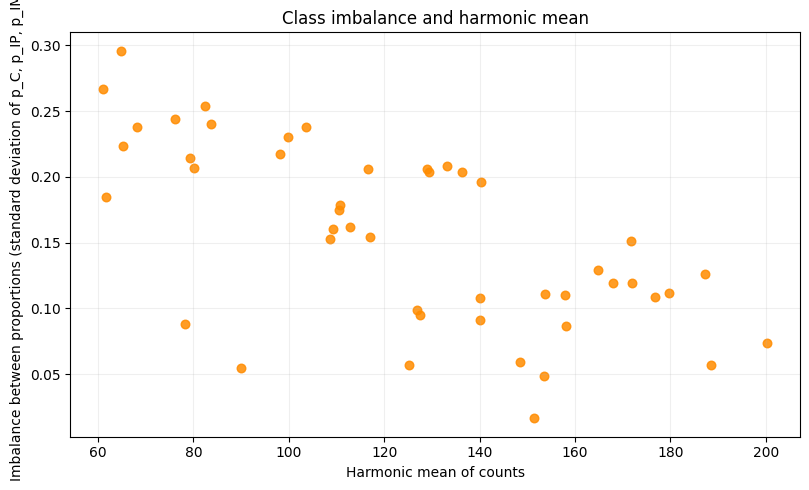

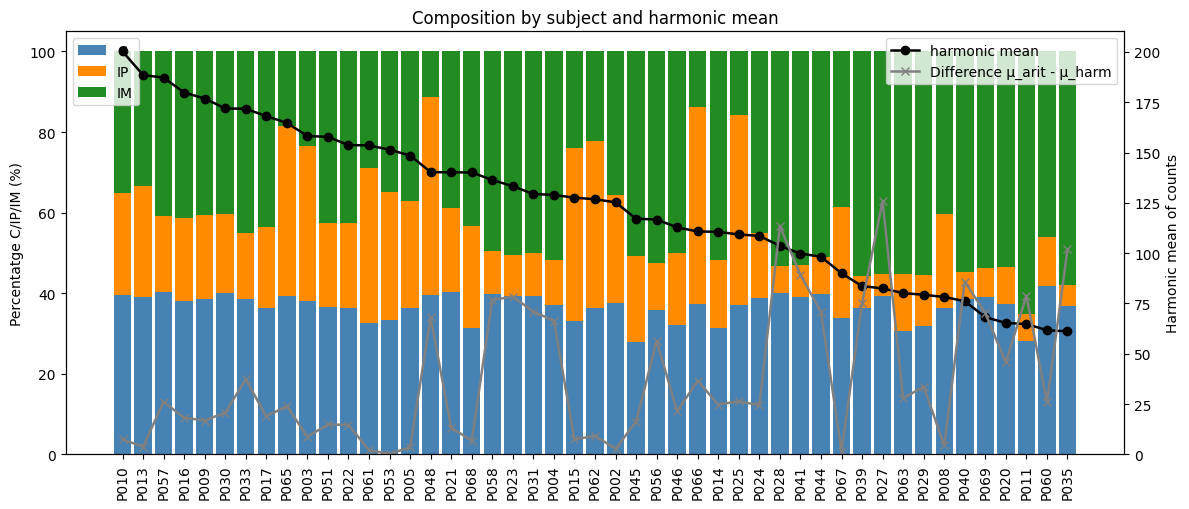

In [ ]:
# Three views of the harmonic mean concept on C/IP/IM
df_hm = df_cipim[["subject", "C", "IP", "IM", "p_C", "p_IP", "p_IM"]].copy()
df_hm["n_harm_3classes"] = 3.0 / ((1.0 / df_hm["C"]) + (1.0 / df_hm["IP"]) + (1.0 / df_hm["IM"]))
df_hm["n_arit_3classes"] = (df_hm["C"] + df_hm["IP"] + df_hm["IM"]) / 3.0
df_hm["balance_index"] = df_hm[["p_C", "p_IP", "p_IM"]].std(axis=1)

# Plot 1: Arithmetic vs harmonic mean per subject
fig, ax = plt.subplots(figsize=(8.2, 5))
ax.scatter(df_hm["n_arit_3classes"], df_hm["n_harm_3classes"], color="steelblue", s=38, alpha=0.85)
xy_min = min(df_hm["n_arit_3classes"].min(), df_hm["n_harm_3classes"].min())
xy_max = max(df_hm["n_arit_3classes"].max(), df_hm["n_harm_3classes"].max())
ax.plot([xy_min, xy_max], [xy_min, xy_max], linestyle="--", linewidth=1.1, color="black")
ax.set_xlabel("Arithmetic mean of counts (C, IP, IM)")
ax.set_ylabel("Harmonic mean counts (C, IP, IM)")
ax.set_title("Arithmetic mean vs harmonic mean")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mitjana_aritmetica_vs_harmonica_c_ip_im.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: ratio imbalance vs harmonic mean
fig, ax = plt.subplots(figsize=(8.2, 5))
ax.scatter(df_hm["n_harm_3classes"], df_hm["balance_index"], color="darkorange", s=38, alpha=0.85)
ax.set_xlabel("Harmonic mean of counts")
ax.set_ylabel("Imbalance between proportions (standard deviation of p_C, p_IP, p_IM)")
ax.set_title("Class imbalance and harmonic mean")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "desbalanc_proporcions_vs_mitjana_harmonica.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 3: stacked proportions, ordered by harmonic mean
plot_df = df_hm.sort_values("n_harm_3classes", ascending=False).reset_index(drop=True)
subjectes_hm = plot_df["subject"].tolist()
x = np.arange(len(plot_df))
bottom = np.zeros(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 5.2))
for cls in ["C", "IP", "IM"]:
    vals = plot_df[f"p_{cls}"].values * 100
    ax.bar(x, vals, bottom=bottom, label=cls, color=CIPIM_COLORS[cls], width=0.85)
    bottom += vals

ax2 = ax.twinx()
ax2.plot(x, plot_df["n_harm_3classes"].values, color="black", linewidth=1.8, marker="o", label="harmonic mean")
ax2.plot(
    x,
    plot_df["n_arit_3classes"].values - plot_df["n_harm_3classes"].values,
    color="white",
    linewidth=1.8,
    marker="x",
    label="Difference μ_arit - μ_harm",
)
ax2.set_ylabel("Harmonic mean of counts")
ax2.set_ylim(0, ax2.get_ylim()[1])
ax.set_xticks(x)
ax.set_xticklabels(subjectes_hm, rotation=90)
ax.set_ylabel("Percentatge C/IP/IM (%)")
ax.set_title("Composition by subject and harmonic mean")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "composicio_i_mitjana_harmonica_per_subjecte.png", dpi=300, bbox_inches="tight")
plt.show()

### Effect per subject: Cohen's d real (theta FCz and alpha Oz)

Here we calculate **Real Cohen's d** per subject on a continuous variable, in the **Pure Incongruent (IP) vs Congruent (C)** contrast:
$$
d = \frac{\bar{x}_{IP} - \bar{x}_C}{s_{pooled}}
$$

Definitions of this blog:
- **Theta**: 5–7 Hz band power at **FCz**.
- **Alpha**: 8–12 Hz band power at **Oz**.
- Trial-by-trial summary in the time window $[0.5, 1.0]$ s.

About undersampling for Cohen's d:
- recommended as main analysis: **no** (keep all data),
- recommended as sensitivity: **yes** (compare with balanced version).

In [148]:
COHENS_TABLE_PATH = TABLES_DIR / "cohens_d_real_per_subjecte.csv"

try:
    df_cohens = pd.read_csv(COHENS_TABLE_PATH)
    print(f"Table loaded: {COHENS_TABLE_PATH}")
except Exception:
    print("Computing Cohen's d by subject...")

    def trial_bandpower_mean(epochs_obj, channel, band, time_window):
        if channel not in epochs_obj.ch_names:
            return None
        data = epochs_obj.get_data(picks=[channel]).squeeze(axis=1)  # (n_trials, n_times)
        sfreq = epochs_obj.info["sfreq"]

        # Fast band power: temporal filter + quadratic power.
        filtered = mne.filter.filter_data(
            data,
            sfreq=sfreq,
            l_freq=band[0],
            h_freq=band[1],
            method="fir",
            verbose=False,
        )
        power = filtered**2
        tmask = (epochs_obj.times >= time_window[0]) & (epochs_obj.times <= time_window[1])
        return power[:, tmask].mean(axis=1)

    def cohens_d_independent(x_ip, x_c):
        """Calculate Cohen's d for independent samples with pooled standard deviation.
        Returns np.nan if it cannot be calculated due to missing data or zero deviation."""

        n_ip = len(x_ip)
        n_c = len(x_c)
        if n_ip < 2 or n_c < 2:
            return np.nan

        s_ip = float(np.std(x_ip, ddof=1))
        s_c = float(np.std(x_c, ddof=1))
        pooled = np.sqrt(((n_ip - 1) * (s_ip**2) + (n_c - 1) * (s_c**2)) / (n_ip + n_c - 2))
        if not np.isfinite(pooled) or pooled == 0:
            return np.nan

        return (float(np.mean(x_ip)) - float(np.mean(x_c))) / pooled

    def get_undersampled_indices(n_ip, n_c, rng):
        n_min = min(n_ip, n_c)
        if n_min < 2:
            return None, None
        idx_ip = rng.choice(n_ip, size=n_min, replace=False)
        idx_c = rng.choice(n_c, size=n_min, replace=False)
        return idx_ip, idx_c

    rows_d = []

    for fif_path in sorted(DATA_DIR.glob("*.fif")):
        subj = fif_path.stem

        ep, ep_cond = load_subject(fif_path)

        ip_names = [name for name in ep_cond if name == "Incongruent_Pure"]
        c_names = [name for name in ep_cond if name == "Congruent"]
        im_names = [name for name in ep_cond if name == "Incongruent_Mixed"]

        if not c_names or not ip_names:
            print(f"subject {subj}: required event codes for C/IP not found. Needs manual review.")
            continue

        ep_c = ep_cond["Congruent"]
        ep_ip = ep_cond["Incongruent_Pure"]

        n_im = len(ep_cond["Incongruent_Mixed"]) if im_names else 0

        theta_c = trial_bandpower_mean(ep_c, channel="FCz", band=(5, 7), time_window=ERP_WINDOW)
        theta_ip = trial_bandpower_mean(ep_ip, channel="FCz", band=(5, 7), time_window=ERP_WINDOW)
        alpha_c = trial_bandpower_mean(ep_c, channel="Oz", band=(8, 12), time_window=ERP_WINDOW)
        alpha_ip = trial_bandpower_mean(ep_ip, channel="Oz", band=(8, 12), time_window=ERP_WINDOW)

        if theta_c is None or theta_ip is None or alpha_c is None or alpha_ip is None:
            print(f"subject {subj}: band powers could not be computed due to missing channels. Needs manual review.")
            continue

        d_theta_raw = cohens_d_independent(theta_ip, theta_c)
        d_alpha_raw = cohens_d_independent(alpha_ip, alpha_c)

        rng_us = np.random.default_rng(42 + hash(subj) % 10000)
        idx_ip, idx_c = get_undersampled_indices(len(theta_ip), len(theta_c), rng_us)

        if idx_ip is not None and idx_c is not None:
            d_theta_us = cohens_d_independent(theta_ip[idx_ip], theta_c[idx_c])
            d_alpha_us = cohens_d_independent(alpha_ip[idx_ip], alpha_c[idx_c])
        else:
            d_theta_us = np.nan
            d_alpha_us = np.nan
            print(
                f"subject {subj}: Cohen's d with undersampling could not be computed due to insufficient trials in some class."
            )

        n_c = len(theta_c)
        n_ip = len(theta_ip)

        if min(n_c, n_ip, n_im) < 2:
            print(
                f"subject {subj}: harmonic means could not be computed due to insufficient trials in some class (C={n_c}, IP={n_ip}, IM={n_im})."
            )
            n_harm = np.nan
        else:
            n_harm = 3.0 / ((1.0 / n_c) + (1.0 / n_ip) + (1.0 / n_im))

        n_balanced = 2.0 * min(n_c, n_ip)

        row_ci = df_cipim[df_cipim["subject"] == subj]

        rows_d.append(
            {
                "subject": subj,
                "cohens_d_theta_fcz": d_theta_raw,
                "cohens_d_alpha_oz": d_alpha_raw,
                "cohens_d_theta_fcz_us": d_theta_us,
                "cohens_d_alpha_oz_us": d_alpha_us,
                "C": n_c,
                "IP": n_ip,
                "IM": n_im,
                "n_harm_3classes": n_harm,
                "n_balanced_ci": n_balanced,
            }
        )

        del ep, ep_cond, theta_c, theta_ip, alpha_c, alpha_ip
        gc.collect()

    df_cohens = pd.DataFrame(rows_d)
    if df_cohens.empty:
        raise RuntimeError("No Cohen's d could be computed by subject.")

    df_cohens.to_csv(COHENS_TABLE_PATH, index=False)
    print(f"Saved table: {COHENS_TABLE_PATH}")

# Sorted Tables (Largest -> Smallest)
df_theta_sorted = df_cohens.sort_values("cohens_d_theta_fcz", ascending=False).reset_index(drop=True)
df_alpha_sorted = df_cohens.sort_values("cohens_d_alpha_oz", ascending=False).reset_index(drop=True)

print("Cohen's d theta (FCz) ordered from largest to smallest:")
display(df_theta_sorted[["subject", "cohens_d_theta_fcz", "cohens_d_theta_fcz_us", "C", "IP"]])

print("Cohen's d alpha (Oz) ordered from largest to smallest:")
display(df_alpha_sorted[["subject", "cohens_d_alpha_oz", "cohens_d_alpha_oz_us", "C", "IP"]])

print("Theta extremes (maximum and minimum):")
display(pd.concat([df_theta_sorted.head(1), df_theta_sorted.tail(1)], ignore_index=True))

print("Alpha extremes (maximum and minimum):")
display(pd.concat([df_alpha_sorted.head(1), df_alpha_sorted.tail(1)], ignore_index=True))

Table loaded: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\cohens_d_real_per_subjecte.csv
Computing Cohen's d by subject...
Saved table: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\cohens_d_real_per_subjecte.csv
Cohen's d theta (FCz) ordered from largest to smallest:


,subject,cohens_d_theta_fcz,cohens_d_theta_fcz_us,C,IP
0,P040,0.462300,0.415910,187,33
1,P045,0.348442,0.332618,112,85
2,P056,0.340618,0.236649,186,60
3,P023,0.323009,0.304060,249,65
4,P014,0.257505,0.280296,127,69
5,P002,0.216033,0.238969,144,103
6,P024,0.194757,0.264203,155,64
7,P027,0.174563,0.001524,246,34
8,P067,0.157750,0.107838,93,76
9,P033,0.138825,0.195044,242,102


Cohen's d alpha (Oz) ordered from largest to smallest:


,subject,cohens_d_alpha_oz,cohens_d_alpha_oz_us,C,IP
0,P024,0.327909,0.304464,155,64
1,P004,0.315582,0.143032,218,65
2,P046,0.199650,0.227936,129,72
3,P013,0.160384,0.136197,225,159
4,P053,0.137332,0.122630,152,144
5,P008,0.112074,0.157949,90,58
6,P045,0.097975,0.077027,112,85
7,P010,0.063343,0.084427,247,157
8,P020,0.020275,-0.041934,124,31
9,P056,0.000086,0.033624,186,60


Theta extremes (maximum and minimum):


,subject,cohens_d_theta_fcz,cohens_d_alpha_oz,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,C,IP,IM,n_harm_3classes,n_balanced_ci
0,P040,0.462300,-0.197679,0.41591,-0.309296,187,33,266,76.122768,66.0
1,P057,-0.416631,-0.633250,-0.41921,-0.639018,258,120,262,187.194683,240.0


Alpha extremes (maximum and minimum):


,subject,cohens_d_theta_fcz,cohens_d_alpha_oz,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,C,IP,IM,n_harm_3classes,n_balanced_ci
0,P024,0.194757,0.327909,0.264203,0.304464,155,64,180,108.569112,128.0
1,P057,-0.416631,-0.633250,-0.419210,-0.639018,258,120,262,187.194683,240.0


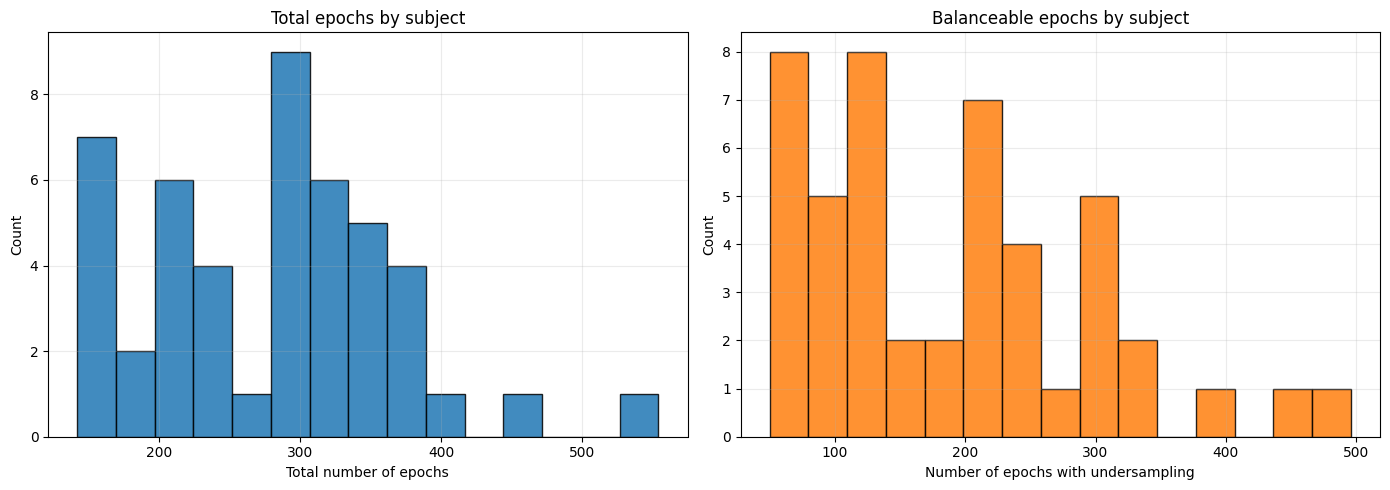

Quick summary:
- Total epochs by subject: min=142, max=554, mitjana=280.0
- 2×min(C, IP): min=50, max=496, mitjana=188.6


,subject,cohens_d_theta_fcz,cohens_d_alpha_oz,C,IP,n_harm_3classes,n_balanced_ci
0,P002,0.216033,-0.343979,144,103,125.248135,206.0
1,P003,-0.203969,-0.504878,191,193,158.194826,382.0
2,P004,-0.019846,0.315582,218,65,128.909717,130.0
3,P005,-0.202974,-0.199584,166,121,148.472816,242.0
4,P008,-0.005703,0.112074,90,58,78.221778,116.0
5,P009,-0.096554,-0.225065,224,121,176.823855,242.0
6,P010,-0.030113,0.063343,247,157,200.210624,314.0
7,P011,-0.208068,-0.210972,121,29,64.786504,58.0
8,P013,0.004541,0.160384,225,159,188.500232,318.0
9,P014,0.257505,-0.020979,127,69,110.584100,138.0


In [149]:
# Histograms of epoch availability by subject
# 1) Total number of epochs per subject
#    Here we count all available samples per subject (C + IP).
df_epochs_subjecte = df_cohens.copy()
df_epochs_subjecte["n_total_epochs"] = df_epochs_subjecte["C"] + df_epochs_subjecte["IP"]

# 2) Number of swingable epochs per subject: 2 * min(C, IP)
#    It is the maximum that could be used if you want to balance the classes perfectly.
df_balanceig = df_epochs_subjecte.copy()
df_balanceig["n_balancejable"] = 2 * np.minimum(df_balanceig["C"], df_balanceig["IP"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram 1: total epochs per subject
axes[0].hist(df_epochs_subjecte["n_total_epochs"], bins=15, color="tab:blue", edgecolor="black", alpha=0.85)
axes[0].set_title("Total epochs by subject")
axes[0].set_xlabel("Total number of epochs")
axes[0].set_ylabel("Count")
axes[0].grid(alpha=0.25)

# Histograma 2: 2 * min(C, IP)
axes[1].hist(df_balanceig["n_balancejable"], bins=15, color="tab:orange", edgecolor="black", alpha=0.85)
axes[1].set_title("Balanceable epochs by subject")
axes[1].set_xlabel("Number of epochs with undersampling")
axes[1].set_ylabel("Count")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Quick summary:")
print(
    f"- Total epochs by subject: min={df_epochs_subjecte['n_total_epochs'].min():.0f}, max={df_epochs_subjecte['n_total_epochs'].max():.0f}, mitjana={df_epochs_subjecte['n_total_epochs'].mean():.1f}"
)
print(
    f"- 2×min(C, IP): min={df_balanceig['n_balancejable'].min():.0f}, max={df_balanceig['n_balancejable'].max():.0f}, mitjana={df_balanceig['n_balancejable'].mean():.1f}"
)

# Display of data by subject
display(
    df_cohens[["subject", "cohens_d_theta_fcz", "cohens_d_alpha_oz", "C", "IP", "n_harm_3classes", "n_balanced_ci"]]
)

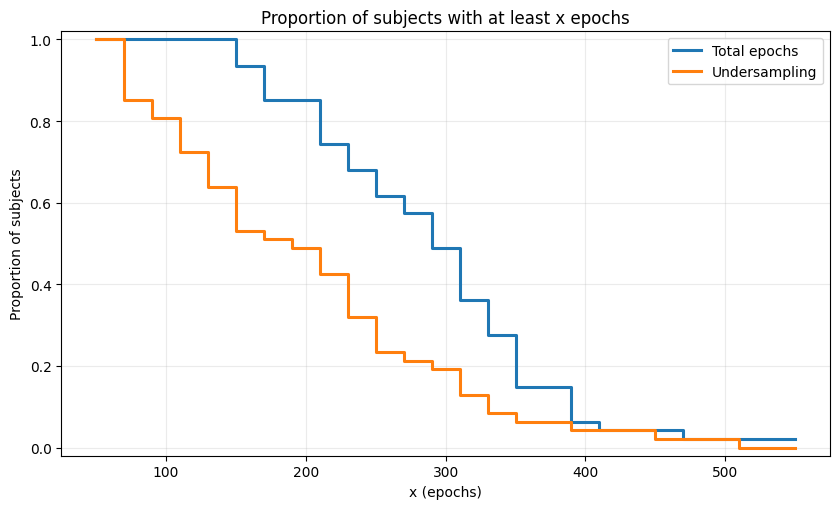

>=  50 epochs -> total: 100.0% | undersampling: 100.0%
>= 100 epochs -> total: 100.0% | undersampling: 72.3%
>= 150 epochs -> total: 93.6% | undersampling: 53.2%
>= 200 epochs -> total: 78.7% | undersampling: 46.8%
>= 250 epochs -> total: 61.7% | undersampling: 23.4%
>= 300 epochs -> total: 42.6% | undersampling: 17.0%
>= 350 epochs -> total: 14.9% | undersampling: 6.4%
>= 400 epochs -> total: 6.4% | undersampling: 4.3%
>= 450 epochs -> total: 4.3% | undersampling: 2.1%
>= 500 epochs -> total: 2.1% | undersampling: 0.0%


In [150]:
# Sister plot: proportion of subjects with >= x epochs
vals_total = df_epochs_subjecte["n_total_epochs"].to_numpy(dtype=float)
vals_us = df_balanceig["n_balancejable"].to_numpy(dtype=float)

x_min = int(min(vals_total.min(), vals_us.min()))
x_max = int(max(vals_total.max(), vals_us.max()))
# Step of 10 epochs to keep the graph clean and interpretable
x_grid = np.arange(x_min, x_max + 1, 20)

prop_total = np.array([(vals_total >= x).mean() for x in x_grid], dtype=float)
prop_us = np.array([(vals_us >= x).mean() for x in x_grid], dtype=float)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.step(x_grid, prop_total, where="post", color="tab:blue", linewidth=2.2, label="Total epochs")
ax.step(x_grid, prop_us, where="post", color="tab:orange", linewidth=2.2, label="Undersampling")

ax.set_title("Proportion of subjects with at least x epochs")
ax.set_xlabel("x (epochs)")
ax.set_ylabel("Proportion of subjects")
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Small numerical summary on some key thresholds
for x in range(50, 501, 50):
    p_total = (vals_total >= x).mean()
    p_us = (vals_us >= x).mean()
    print(f">= {x:3d} epochs -> total: {p_total:.1%} | undersampling: {p_us:.1%}")

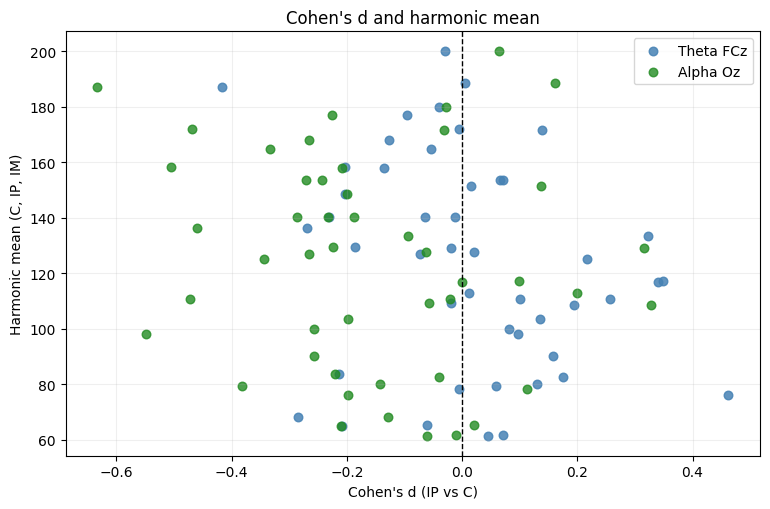

In [151]:
# x = Cohen's d, y = harmonic mean
df_plot = df_theta_sorted.copy()
fig, ax = plt.subplots(figsize=(7.8, 5.2))
ax.scatter(
    df_plot["cohens_d_theta_fcz"], df_plot["n_harm_3classes"], color="steelblue", alpha=0.85, s=38, label="Theta FCz"
)
ax.scatter(
    df_plot["cohens_d_alpha_oz"], df_plot["n_harm_3classes"], color="forestgreen", alpha=0.8, s=38, label="Alpha Oz"
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Cohen's d (IP vs C)")
ax.set_ylabel("Harmonic mean (C, IP, IM)")
ax.set_title("Cohen's d and harmonic mean")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mitjana_harmonica.png", dpi=300, bbox_inches="tight")
plt.show()

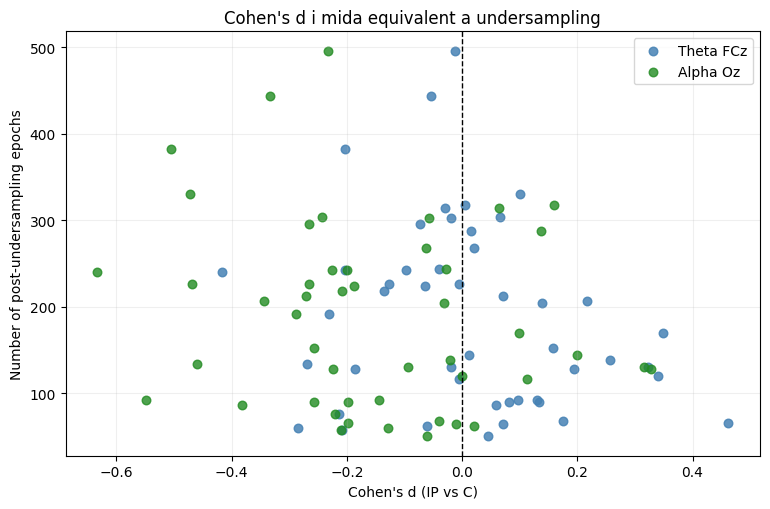

In [152]:
# x = Cohen's d, y = mida equivalent a undersampling
df_plot = df_theta_sorted.copy()
fig, ax = plt.subplots(figsize=(7.8, 5.2))
ax.scatter(
    df_plot["cohens_d_theta_fcz"], df_plot["n_balanced_ci"], color="steelblue", alpha=0.85, s=38, label="Theta FCz"
)
ax.scatter(
    df_plot["cohens_d_alpha_oz"], df_plot["n_balanced_ci"], color="forestgreen", alpha=0.8, s=38, label="Alpha Oz"
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Cohen's d (IP vs C)")
ax.set_ylabel("Number of post-undersampling epochs")
ax.set_title("Cohen's d i mida equivalent a undersampling")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mida_undersampling.png", dpi=300, bbox_inches="tight")
plt.show()

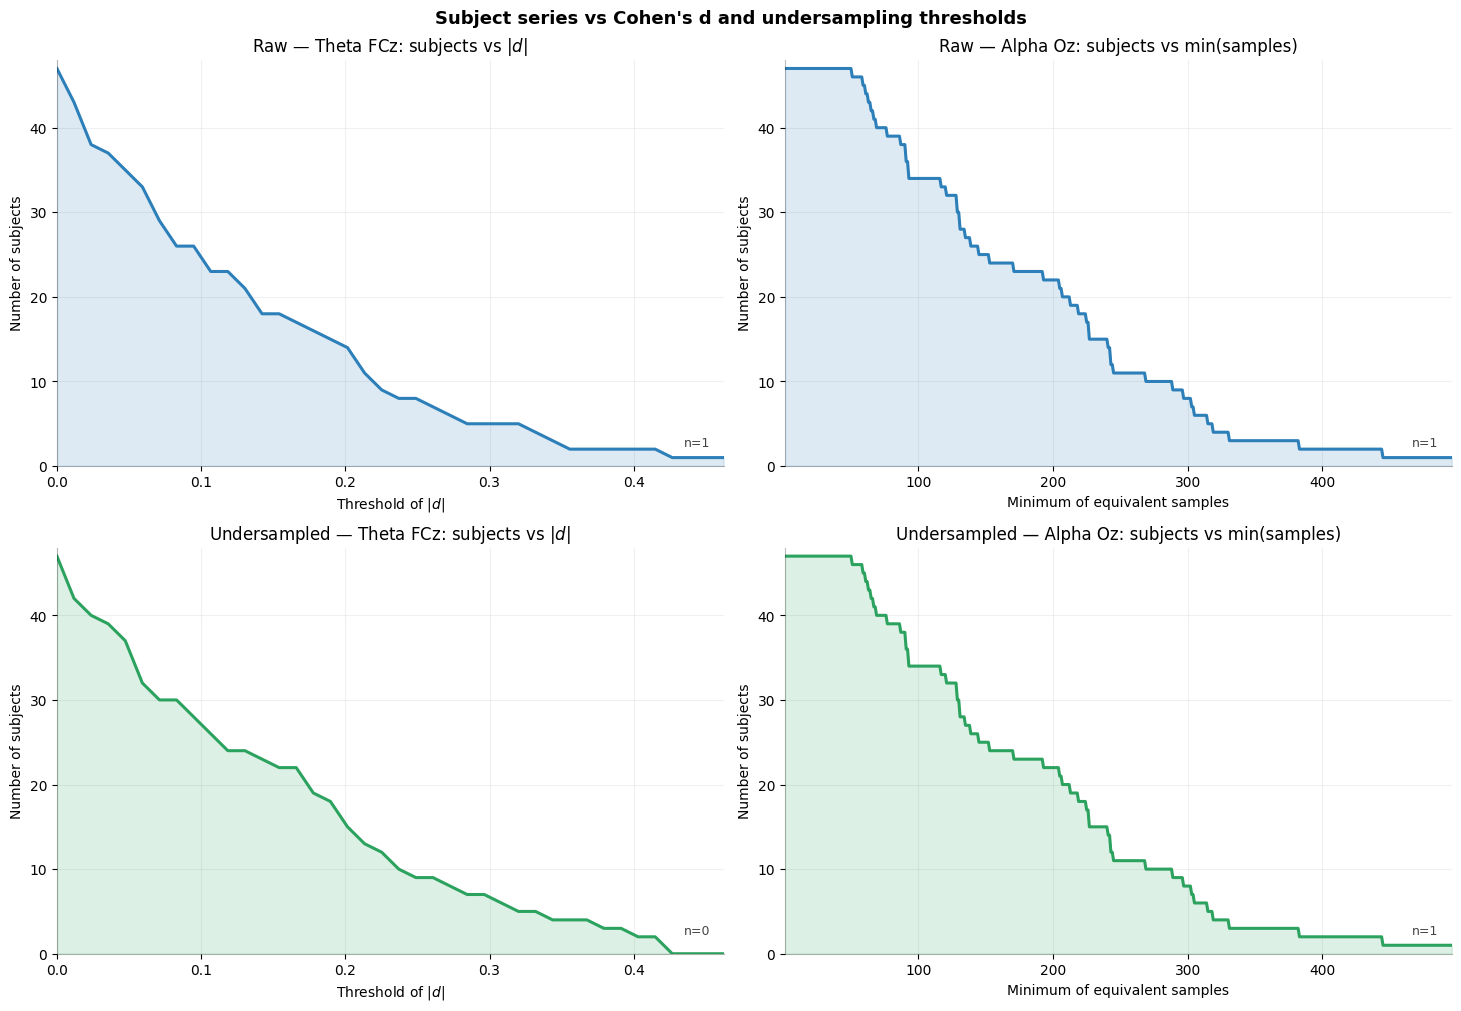

In [153]:
# Series of plots: number of subjects as a function of Cohen's d threshold and minimum samples
# We will make a 2x2 grid with a nested loop: rows = raw/undersampled, columns = |d| and min(samples)

series_specs = [
    (
        "raw",
        {
            "theta": df_cohens["cohens_d_theta_fcz"].abs().to_numpy(),
            "alpha": df_cohens["cohens_d_alpha_oz"].abs().to_numpy(),
        },
    ),
    (
        "undersampled",
        {
            "theta": df_cohens["cohens_d_theta_fcz_us"].abs().to_numpy(),
            "alpha": df_cohens["cohens_d_alpha_oz_us"].abs().to_numpy(),
        },
    ),
]

sample_counts = df_cohens["n_balanced_ci"].to_numpy()
d_limits = {
    "theta": float(np.nanmax(df_cohens[["cohens_d_theta_fcz", "cohens_d_theta_fcz_us"]].abs().to_numpy())),
    "alpha": float(np.nanmax(df_cohens[["cohens_d_alpha_oz", "cohens_d_alpha_oz_us"]].abs().to_numpy())),
}
d_thresholds = {key: np.linspace(0.0, max(value, 1e-6), 40) for key, value in d_limits.items()}
sample_thresholds = np.arange(1, int(np.nanmax(sample_counts)) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14.5, 10), constrained_layout=True)
panel_info = [("theta", "Theta FCz"), ("alpha", "Alpha Oz")]
row_colors = {"raw": "#2C7FB8", "undersampled": "#2CA25F"}
row_titles = {"raw": "Raw", "undersampled": "Undersampled"}

for row_idx, (row_key, values_by_band) in enumerate(series_specs):
    for col_idx, (band_key, band_label) in enumerate(panel_info):
        ax = axes[row_idx, col_idx]
        values = values_by_band[band_key]
        color = row_colors[row_key]

        if col_idx == 0:
            thresholds = d_thresholds[band_key]
            counts = np.array([(values >= thr).sum() for thr in thresholds])
            ax.plot(thresholds, counts, color=color, linewidth=2.2)
            ax.fill_between(thresholds, counts, alpha=0.16, color=color)
            ax.set_xlabel(r"Threshold of $|d|$")
            ax.set_ylabel("Number of subjects")
            ax.set_title(f"{row_titles[row_key]} — {band_label}: subjects vs $|d|$")
            ax.set_xlim(thresholds.min(), thresholds.max())
            ax.set_ylim(0, len(df_cohens) + 1)
        else:
            thresholds = sample_thresholds
            counts = np.array([(sample_counts >= thr).sum() for thr in thresholds])
            ax.plot(thresholds, counts, color=color, linewidth=2.2)
            ax.fill_between(thresholds, counts, alpha=0.16, color=color)
            ax.set_xlabel("Minimum of equivalent samples")
            ax.set_ylabel("Number of subjects")
            ax.set_title(f"{row_titles[row_key]} — {band_label}: subjects vs min(samples)")
            ax.set_xlim(thresholds.min(), thresholds.max())
            ax.set_ylim(0, len(df_cohens) + 1)

        ax.grid(alpha=0.18, linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.spines["left"].set_alpha(0.25)
        ax.spines["bottom"].set_alpha(0.25)
        ax.text(
            0.98,
            0.04,
            f"n={counts[-1]:d}",
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=9,
            color="#444444",
        )

fig.suptitle("Subject series vs Cohen's d and undersampling thresholds", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_subjectes_vs_llindars_nested_grid.png", dpi=300, bbox_inches="tight")
plt.show()

It seems that both 100 and 200 are good thresholds and are at relatively stable points on the curve. With a minimum threshold of 100 trials per class, most subjects are retained and the risk of overfitting subjects with very little data is reduced. With 200 trials, the risk is further reduced but more subjects are lost. In this case, 100 seems to be a good compromise between keeping subjects and ensuring a robust estimate of Cohen's d.

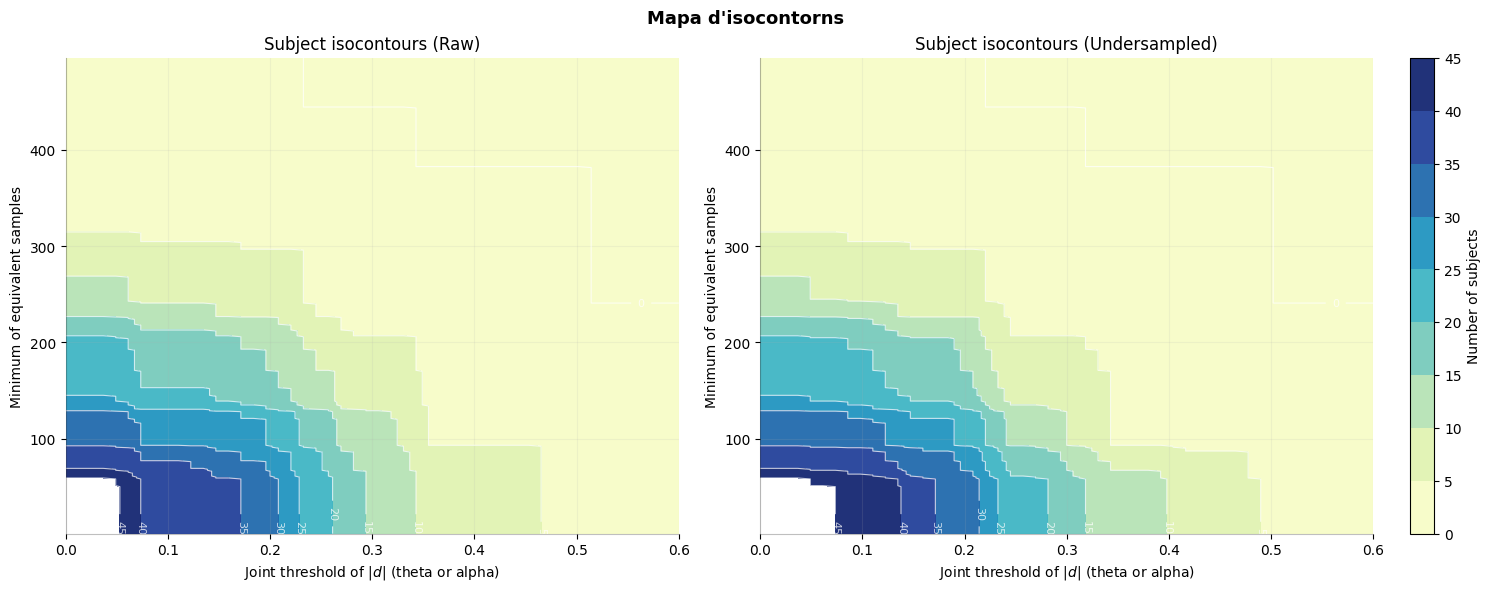

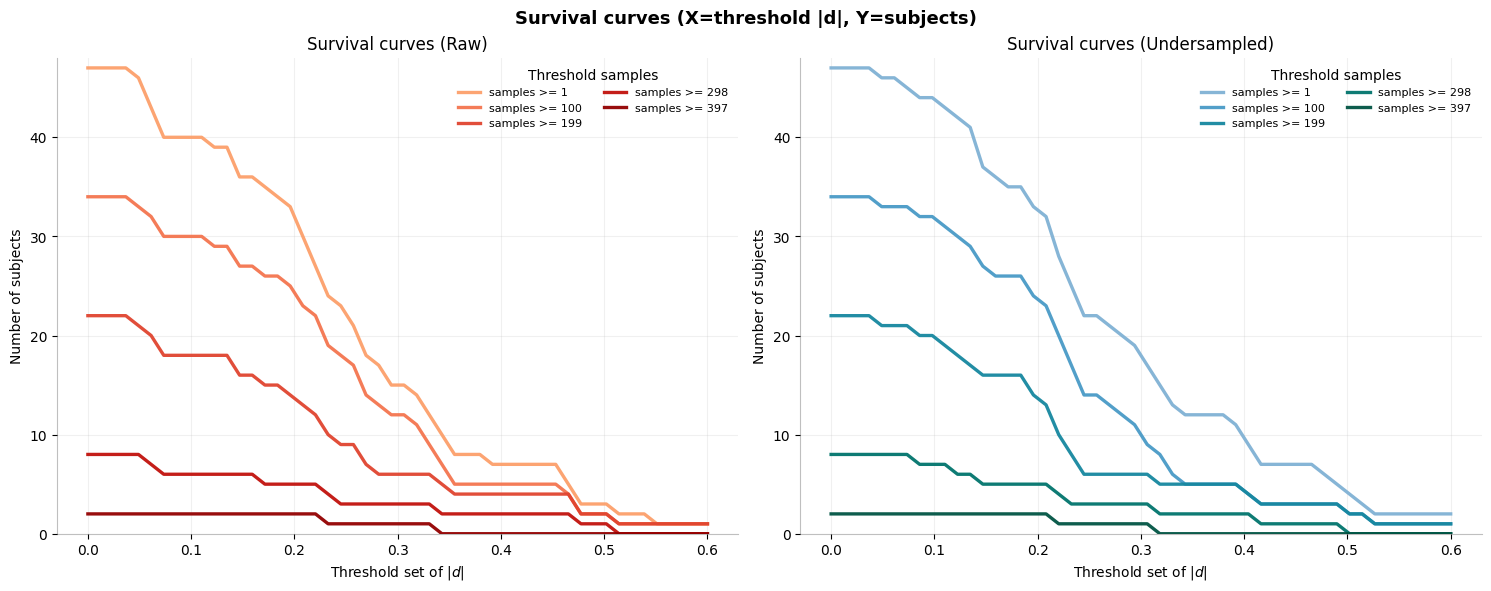

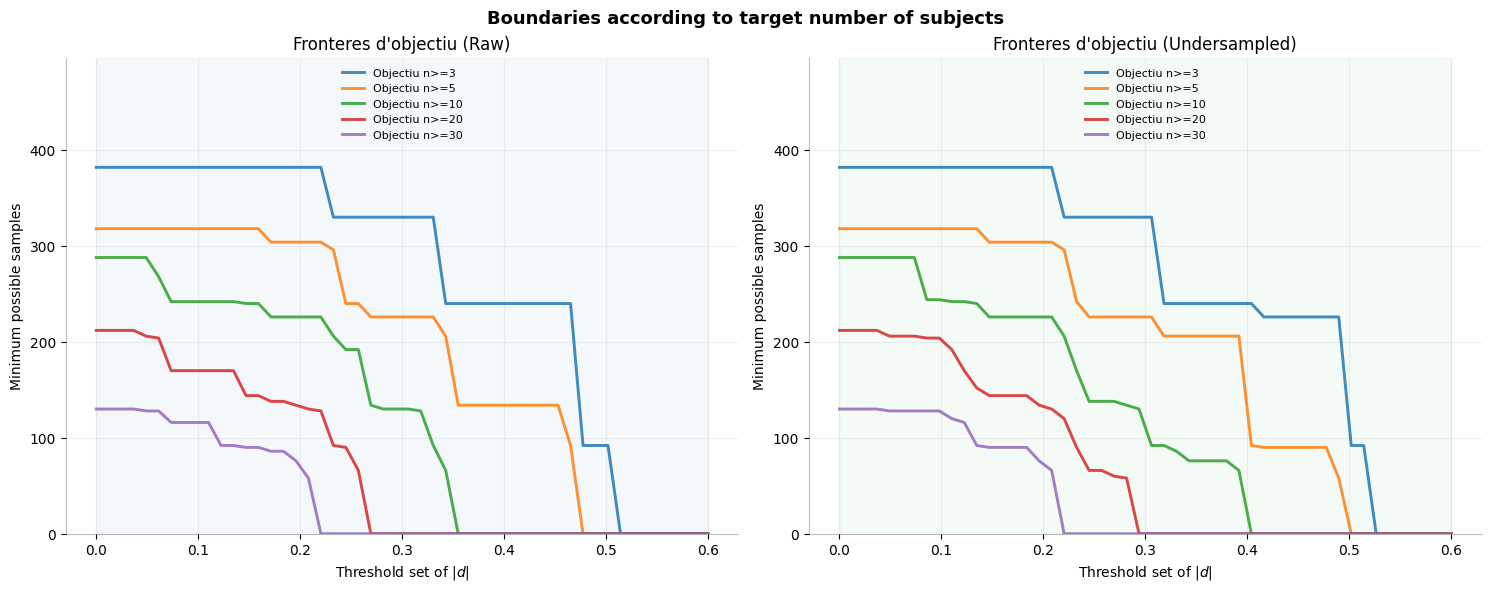

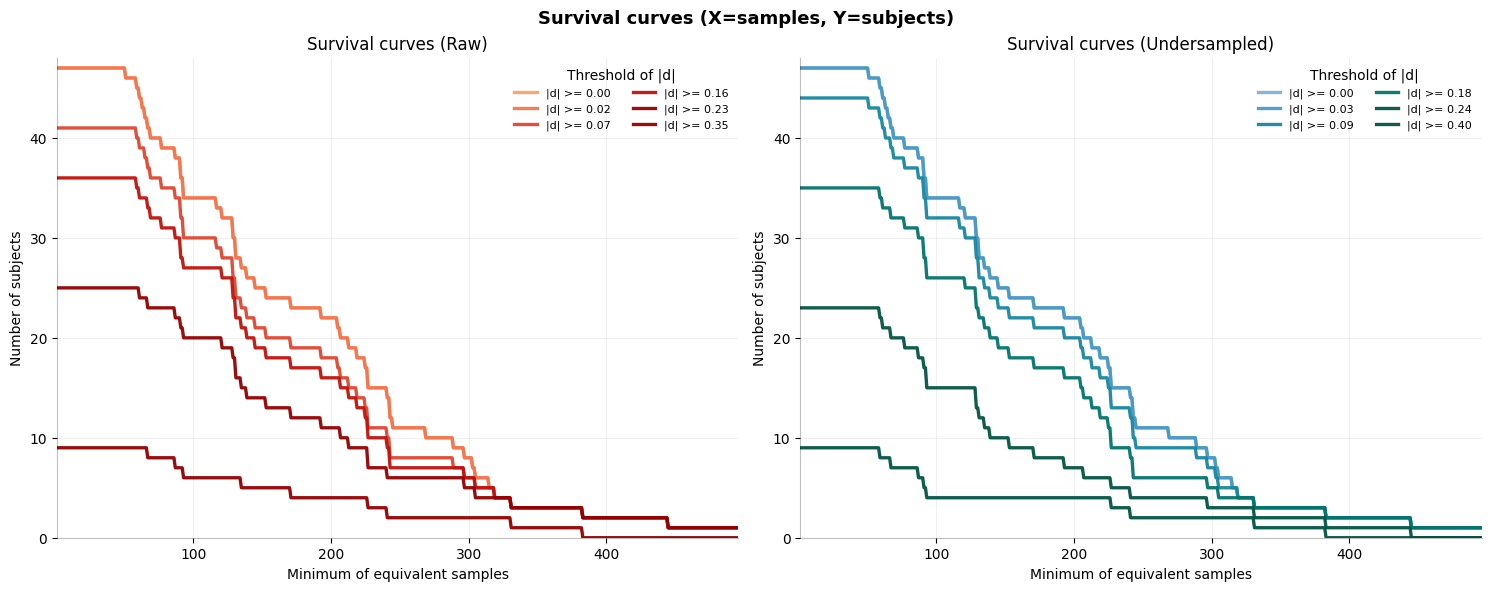

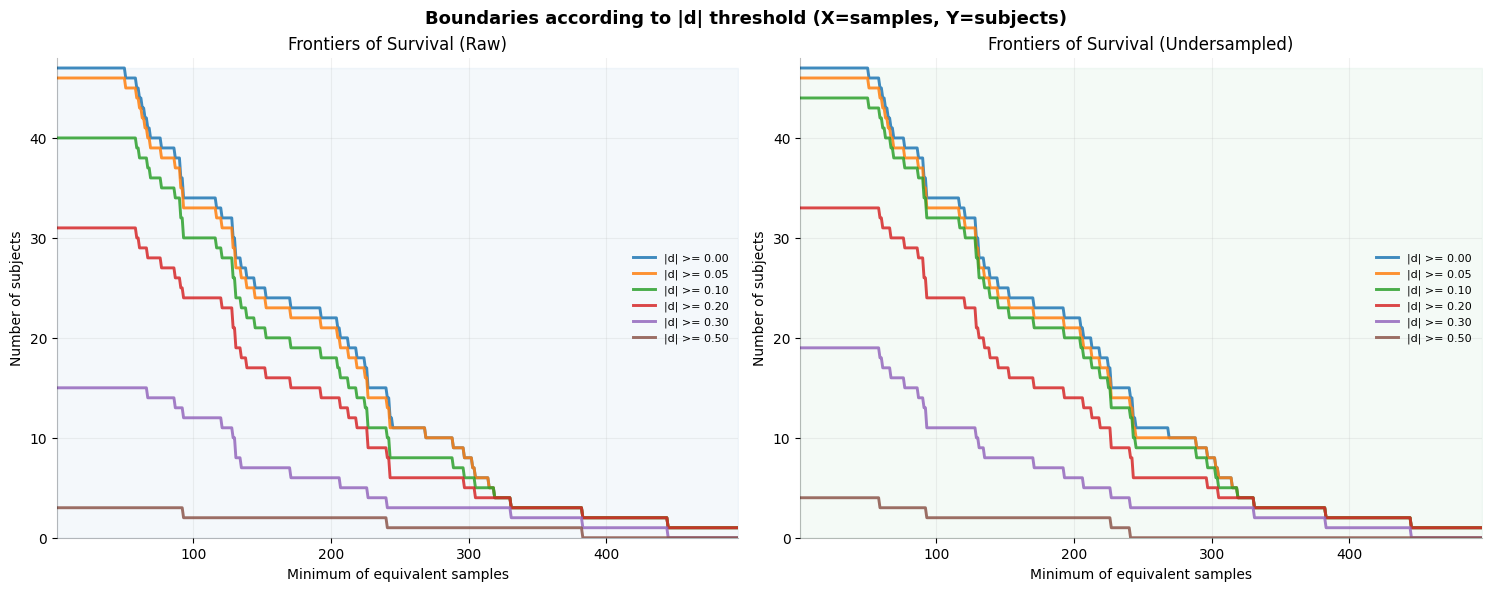

In [154]:
sample_counts = df_cohens["n_balanced_ci"].to_numpy()
d_thr_max = float(
    np.nanmax(
        df_cohens[
            [
                "cohens_d_theta_fcz",
                "cohens_d_alpha_oz",
                "cohens_d_theta_fcz_us",
                "cohens_d_alpha_oz_us",
            ]
        ]
        .abs()
        .to_numpy()
    )
)

d_thresholds = np.linspace(0.0, 0.6, 50)
sample_thresholds = np.arange(1, int(np.nanmax(sample_counts)) + 1)

specs = {
    "Raw": {
        "theta": df_cohens["cohens_d_theta_fcz"].abs().to_numpy(),
        "alpha": df_cohens["cohens_d_alpha_oz"].abs().to_numpy(),
        "color": "#2C7FB8",
    },
    "Undersampled": {
        "theta": df_cohens["cohens_d_theta_fcz_us"].abs().to_numpy(),
        "alpha": df_cohens["cohens_d_alpha_oz_us"].abs().to_numpy(),
        "color": "#2CA25F",
    },
}


def build_grid(theta_vals, alpha_vals, d_thresholds):
    grid = np.zeros((len(sample_thresholds), len(d_thresholds)), dtype=int)
    for i, n_thr in enumerate(sample_thresholds):
        for j, d_thr in enumerate(d_thresholds):
            keep = ((theta_vals >= d_thr) | (alpha_vals >= d_thr)) & (sample_counts >= n_thr)
            grid[i, j] = int(keep.sum())
    return grid


grid_by_name = {name: build_grid(vals["theta"], vals["alpha"], d_thresholds) for name, vals in specs.items()}

# --- Plot A: Isocontorns suaus (raw vs undersampled) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)
for ax, (name, vals) in zip(axes, specs.items()):
    grid = grid_by_name[name]
    levels = np.arange(0, len(df_cohens) + 1, max(1, len(df_cohens) // 8))

    cf = ax.contourf(
        d_thresholds,
        sample_thresholds,
        grid,
        levels=levels,
        cmap="YlGnBu",
        alpha=0.95,
    )
    c = ax.contour(
        d_thresholds,
        sample_thresholds,
        grid,
        levels=levels,
        colors="white",
        linewidths=0.8,
        alpha=0.75,
    )
    ax.clabel(c, fmt="%d", fontsize=8)

    ax.set_title(f"Subject isocontours ({name})")
    ax.set_xlabel(r"Joint threshold of $|d|$ (theta or alpha)")
    ax.set_ylabel("Minimum of equivalent samples")
    ax.grid(alpha=0.14)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02)
cbar.set_label("Number of subjects")
fig.suptitle("Mapa d'isocontorns", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_isocontorns.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot B: Classic survival curves (X=threshold |d|, Y=subjects) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

palette_by_name = {
    "Raw": plt.cm.OrRd(np.linspace(0.45, 0.95, 5)),
    "Undersampled": plt.cm.PuBuGn(np.linspace(0.45, 0.95, 5)),
}

for ax, (name, vals) in zip(axes, specs.items()):
    # Include 0 percentile (minimum samples) to see the loosest scenario.
    q_levels = np.quantile(sample_thresholds, [0.0, 0.2, 0.4, 0.6, 0.8]).astype(int)
    q_levels = np.unique(np.clip(q_levels, sample_thresholds.min(), sample_thresholds.max()))
    palette = palette_by_name[name]

    for k, n_thr in enumerate(q_levels):
        counts = []
        for d_thr in d_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            d_thresholds,
            counts,
            color=palette[min(k, len(palette) - 1)],
            linewidth=2.4,
            alpha=0.95,
            label=f"samples >= {n_thr}",
        )

    ax.set_title(f"Survival curves ({name})")
    ax.set_xlabel(r"Threshold set of $|d|$")
    ax.set_ylabel("Number of subjects")
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8, ncol=2, title="Threshold samples")

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Survival curves (X=threshold |d|, Y=subjects)", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_corbes_supervivencia_x_d.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot C: Classical borders (X=threshold |d|, Y=samples) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

n_targets = [3, 5, 10, 20, 30]
n_targets = [n for n in n_targets if n <= len(df_cohens)]
if len(n_targets) == 0:
    n_targets = [max(1, len(df_cohens) // 2)]

for ax, (name, vals) in zip(axes, specs.items()):
    grid = grid_by_name[name]
    color = vals["color"]

    for target_n in n_targets:
        frontier = []
        for j in range(len(d_thresholds)):
            col = grid[:, j]
            rows_ok = np.where(col >= target_n)[0]
            if len(rows_ok) == 0:
                frontier.append(0)
            else:
                frontier.append(sample_thresholds[rows_ok.max()])

        ax.plot(
            d_thresholds,
            frontier,
            linewidth=2.1,
            alpha=0.85,
            label=f"Objectiu n>={target_n}",
        )

    ax.fill_between(d_thresholds, 0, np.nanmax(sample_thresholds), color=color, alpha=0.05)
    ax.set_title(f"Fronteres d'objectiu ({name})")
    ax.set_xlabel(r"Threshold set of $|d|$")
    ax.set_ylabel("Minimum possible samples")
    ax.set_ylim(0, sample_thresholds.max())
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Boundaries according to target number of subjects", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_fronteres_objectiu_x_d.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot D: New survival curves (X=samples, Y=subjects) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

# Separate vanes to improve visibility between curves and between panels.
palette_by_name = {
    "Raw": plt.cm.OrRd(np.linspace(0.45, 0.95, 5)),
    "Undersampled": plt.cm.PuBuGn(np.linspace(0.45, 0.95, 5)),
}

for ax, (name, vals) in zip(axes, specs.items()):
    # Curves for threshold quantiles of |d|; each point is n_subjects with samples >= x.
    d_pool = np.concatenate([vals["theta"], vals["alpha"]])
    d_levels = np.quantile(d_pool, [0.0, 0.1, 0.3, 0.5, 0.7, 0.9])
    d_levels = np.unique(np.clip(d_levels, d_thresholds.min(), d_thresholds.max()))
    palette = palette_by_name[name]

    for k, d_thr in enumerate(d_levels):
        counts = []
        for n_thr in sample_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            sample_thresholds,
            counts,
            color=palette[min(k, len(palette) - 1)],
            linewidth=2.4,
            alpha=0.95,
            label=f"|d| >= {d_thr:.2f}",
        )

    ax.set_title(f"Survival curves ({name})")
    ax.set_xlabel("Minimum of equivalent samples")
    ax.set_ylabel("Number of subjects")
    ax.set_xlim(sample_thresholds.min(), sample_thresholds.max())
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8, ncol=2, title="Threshold of |d|")

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Survival curves (X=samples, Y=subjects)", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_corbes_supervivencia_x_samples.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot E: New bounds for fixed thresholds of |d| (X=samples, Y=subjects) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

d_targets = [0.00, 0.05, 0.10, 0.20, 0.30, 0.50]
d_targets = [d for d in d_targets if d <= d_thresholds.max()]
if len(d_targets) == 0:
    d_targets = [float(d_thresholds.max())]

for ax, (name, vals) in zip(axes, specs.items()):
    color = vals["color"]

    for d_thr in d_targets:
        counts = []
        for n_thr in sample_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            sample_thresholds,
            counts,
            linewidth=2.1,
            alpha=0.85,
            label=f"|d| >= {d_thr:.2f}",
        )

    ax.fill_between(sample_thresholds, 0, len(df_cohens), color=color, alpha=0.05)
    ax.set_title(f"Frontiers of Survival ({name})")
    ax.set_xlabel("Minimum of equivalent samples")
    ax.set_ylabel("Number of subjects")
    ax.set_xlim(sample_thresholds.min(), sample_thresholds.max())
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Boundaries according to |d| threshold (X=samples, Y=subjects)", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_fronteres_objectiu_x_samples.png", dpi=300, bbox_inches="tight")
plt.show()

In [155]:
# Minimum number of 130 swingable trials (C + IP) to guarantee a solid minimum base.
MIN_BALANCED_TRIALS = 130
eligible_subjects = df_cohens[df_cohens["n_balanced_ci"] >= MIN_BALANCED_TRIALS]
print(f"Eligible subjects with >= {MIN_BALANCED_TRIALS} trials balancejables: {len(eligible_subjects)}")
display(
    eligible_subjects[["subject", "cohens_d_theta_fcz_us", "cohens_d_alpha_oz_us", "n_balanced_ci"]]
    .head(10)
    .style.hide(axis="index")
    .format({"n_balanced_ci": "{:.1f}", "score_seleccio": "{:.3f}"})
)

Eligible subjects with >= 130 trials balancejables: 30


subject,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,n_balanced_ci
P002,0.238969,-0.395174,206.0
P003,-0.202502,-0.498525,382.0
P004,-0.055759,0.143032,130.0
P005,-0.185327,-0.237469,242.0
P009,-0.057766,-0.212136,242.0
P010,-0.026351,0.084427,314.0
P013,0.015961,0.136197,318.0
P014,0.280296,-0.068809,138.0
P015,-0.007551,-0.036976,268.0
P016,-0.103776,0.054141,244.0


In [156]:
# Final ranking of subjects (undersampled): combine |d| theta, |d| alpha and sample size
def minmax_01(s: pd.Series) -> pd.Series:
    s = s.astype(float)
    lo, hi = float(np.nanmin(s)), float(np.nanmax(s))
    if np.isclose(hi - lo, 0.0):
        return pd.Series(np.zeros(len(s), dtype=float), index=s.index)
    return (s - lo) / (hi - lo)


# These weights can be adjusted if we want to prioritize the effect (Cohen's d) or the sample size more.
W_EFFECT = 0.75
W_SIZE = 0.25

rank_df = eligible_subjects[["subject", "cohens_d_theta_fcz_us", "cohens_d_alpha_oz_us", "n_balanced_ci"]].copy()
rank_df["d_theta_us_abs"] = rank_df["cohens_d_theta_fcz_us"].abs()
rank_df["d_alpha_us_abs"] = rank_df["cohens_d_alpha_oz_us"].abs()

# Combined effect: mean Cohen's d of both bands
rank_df["d_combo_us"] = (rank_df["d_theta_us_abs"] + rank_df["d_alpha_us_abs"]) / 2
rank_df["d_combo_us_norm"] = minmax_01(rank_df["d_combo_us"])
rank_df["n_balanced_norm"] = minmax_01(rank_df["n_balanced_ci"])

rank_df["score_seleccio"] = W_EFFECT * rank_df["d_combo_us_norm"] + W_SIZE * rank_df["n_balanced_norm"]

rank_df = rank_df.sort_values("score_seleccio", ascending=False).reset_index(drop=True)

cols_show = [
    "subject",
    "d_theta_us_abs",
    "d_alpha_us_abs",
    "d_combo_us",
    "n_balanced_ci",
    "score_seleccio",
]

print("Top 10 subjects")
display(
    rank_df.head(10)[cols_show]
    .style.hide(axis="index")
    .format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "d_combo_us": "{:.3f}",
            "n_balanced_ci": "{:.1f}",
            "score_seleccio": "{:.3f}",
        }
    )
)

print("Worst 5 subjects")
display(
    rank_df.tail(5)[cols_show]
    .style.hide(axis="index")
    .format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "d_combo_us": "{:.3f}",
            "n_balanced_ci": "{:.1f}",
            "score_seleccio": "{:.3f}",
        }
    )
)

Top 10 subjects


subject,d_theta_us_abs,d_alpha_us_abs,d_combo_us,n_balanced_ci,score_seleccio
P057,0.419,0.639,0.529,240.0,0.825
P003,0.203,0.499,0.351,382.0,0.658
P066,0.194,0.407,0.300,330.0,0.548
P002,0.239,0.395,0.317,206.0,0.488
P065,0.068,0.313,0.191,444.0,0.464
P021,0.235,0.321,0.278,192.0,0.421
P030,0.005,0.516,0.261,226.0,0.418
P048,0.013,0.219,0.116,496.0,0.389
P058,0.209,0.327,0.268,134.0,0.366
P005,0.185,0.237,0.211,242.0,0.356


Worst 5 subjects


subject,d_theta_us_abs,d_alpha_us_abs,d_combo_us,n_balanced_ci,score_seleccio
P053,0.038,0.123,0.081,288.0,0.194
P010,0.026,0.084,0.055,314.0,0.175
P016,0.104,0.054,0.079,244.0,0.162
P004,0.056,0.143,0.099,130.0,0.114
P015,0.008,0.037,0.022,268.0,0.094


In [157]:
# Automatic selection: 5 inflection points of the survival curve
# It identifies real transitions where the subject's fall rate changes significantly
# WITH SEPARATION: points distant from each other

score_thresholds = np.linspace(0.0, 1.0, 101)

# Calculate utility for each threshold
utility_rows = []
for t in score_thresholds:
    sel = rank_df[rank_df["score_seleccio"] >= t]
    n_sel = int(len(sel))
    if n_sel == 0:
        mean_score = np.nan
        utility = np.nan
    else:
        mean_score = float(sel["score_seleccio"].mean())
        utility = float(np.sqrt(n_sel / len(rank_df)) * mean_score)
    utility_rows.append(
        {
            "llindar": float(t),
            "n_subjectes": n_sel,
            "frac_subjectes": n_sel / len(rank_df),
            "score_mitja": mean_score,
            "utility": utility,
        }
    )

df_utility = pd.DataFrame(utility_rows).dropna().sort_values("llindar").reset_index(drop=True)

# For each threshold t, show how many subjects have score >= t.
survival_counts = np.array([(rank_df["score_seleccio"] >= t).sum() for t in score_thresholds], dtype=int)

# Calculate numerical derivative (change of N per threshold step)
diffs = np.diff(survival_counts)
abs_diffs = np.abs(diffs)

# Calculate "acceleration" (change in derivative - where the velocity of fall changes)
accel = np.diff(abs_diffs)

# Identify points where there are acceleration peaks (transitions)
threshold_accel = np.percentile(accel, 80)  # Top 30% changes
inflection_indices = np.where(accel > threshold_accel)[0]

# Group close indexes (avoid duplicates)
if len(inflection_indices) > 0:
    inflection_points = []
    current_group = [inflection_indices[0]]
    for i in range(1, len(inflection_indices)):
        if inflection_indices[i] - inflection_indices[i - 1] <= 2:
            current_group.append(inflection_indices[i])
        else:
            inflection_points.append(int(np.mean(current_group)))
            current_group = [inflection_indices[i]]
    inflection_points.append(int(np.mean(current_group)))
else:
    inflection_points = []

# Convert to df_utility indexes
inflection_thresholds = []
for idx in inflection_points:
    if idx < len(score_thresholds):
        thr = score_thresholds[idx]
        # Find the closest threshold in df_utility
        closest_idx = int((df_utility["llindar"] - thr).abs().idxmin())
        if closest_idx not in [x[0] for x in inflection_thresholds]:
            n_subj = int(df_utility.loc[closest_idx, "n_subjectes"])
            score_mean = float(df_utility.loc[closest_idx, "score_mitja"])
            utility_val = float(df_utility.loc[closest_idx, "utility"])
            inflection_thresholds.append((closest_idx, thr, n_subj, score_mean, utility_val))

# Sort by descending utility
inflection_thresholds_sorted = sorted(inflection_thresholds, key=lambda x: x[4], reverse=True)

# Select 5 points with minimum separability (minimum distance between thresholds: 0.05)
MIN_THRESHOLD_GAP = 0.05
selected_points = []
for idx, thr, n_subj, score_mean, util in inflection_thresholds_sorted:
    # Check if this point is far enough from those already selected
    if len(selected_points) == 0:
        selected_points.append((idx, thr, n_subj, score_mean, util))
    else:
        min_gap_to_existing = min(abs(thr - sp[1]) for sp in selected_points)
        if min_gap_to_existing >= MIN_THRESHOLD_GAP:
            selected_points.append((idx, thr, n_subj, score_mean, util))
    if len(selected_points) == 5:
        break

# Convertir a DataFrame final
selected_indices = [sp[0] for sp in selected_points]
df_key = (
    df_utility.loc[selected_indices, ["llindar", "n_subjectes", "score_mitja", "utility"]]
    .sort_values("llindar")  # Sort by increasing threshold for best display
    .reset_index(drop=True)
)

display(
    df_key.style.hide(axis="index").format(
        {
            "llindar": "{:.3f}",
            "n_subjectes": "{:d}",
            "score_mitja": "{:.3f}",
            "utility": "{:.3f}",
        }
    )
)

# Show top-10 and automatic selection by reference
top_pairs = [
    (row["subject"], f"{row['score_seleccio']:.2f}")
    for _, row in rank_df.head(10)[["subject", "score_seleccio"]].iterrows()
]

auto_threshold = float(df_key.loc[0, "llindar"])  # Best proposition for utility
auto_df = rank_df[rank_df["score_seleccio"] >= auto_threshold][["subject", "score_seleccio"]]
auto_pairs = [(row["subject"], f"{row['score_seleccio']:.2f}") for _, row in auto_df.iterrows()]

print(f"Top-10 (Subj, score):")
print(top_pairs)
print(f"\nAutomatic selection (Proposition 1, Subj, score) [{len(auto_pairs)}]:")
print(auto_pairs)

llindar,n_subjectes,score_mitja,utility
0.090,30,0.317,0.317
0.180,26,0.345,0.321
0.280,13,0.455,0.299
0.340,11,0.480,0.291
0.400,7,0.546,0.264


Top-10 (Subj, score):
[('P057', '0.83'), ('P003', '0.66'), ('P066', '0.55'), ('P002', '0.49'), ('P065', '0.46'), ('P021', '0.42'), ('P030', '0.42'), ('P048', '0.39'), ('P058', '0.37'), ('P005', '0.36')]

Automatic selection (Proposition 1, Subj, score) [30]:
[('P057', '0.83'), ('P003', '0.66'), ('P066', '0.55'), ('P002', '0.49'), ('P065', '0.46'), ('P021', '0.42'), ('P030', '0.42'), ('P048', '0.39'), ('P058', '0.37'), ('P005', '0.36'), ('P017', '0.35'), ('P062', '0.33'), ('P045', '0.30'), ('P067', '0.27'), ('P023', '0.27'), ('P061', '0.26'), ('P046', '0.25'), ('P068', '0.25'), ('P051', '0.25'), ('P009', '0.24'), ('P014', '0.23'), ('P033', '0.23'), ('P022', '0.22'), ('P013', '0.21'), ('P025', '0.19'), ('P053', '0.19'), ('P010', '0.17'), ('P016', '0.16'), ('P004', '0.11'), ('P015', '0.09')]


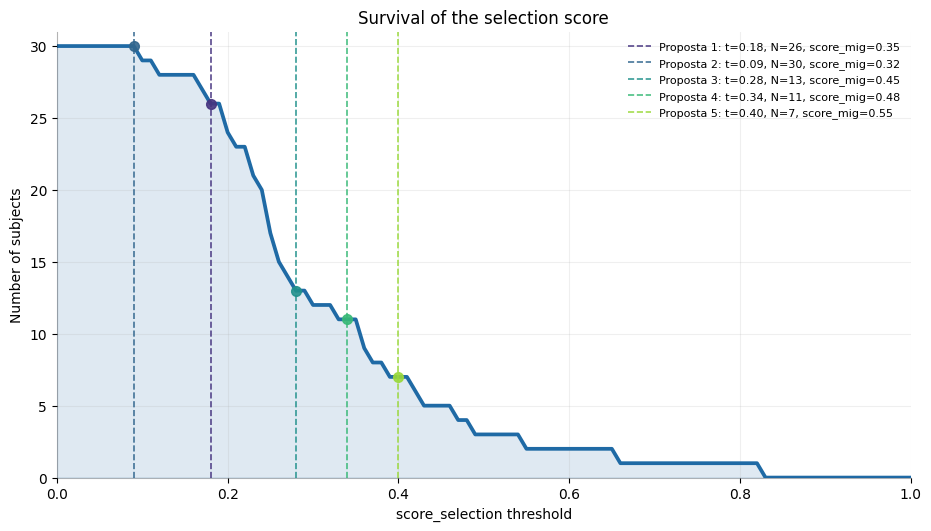

In [158]:
# Selection score survival plot with proposed thresholds
# We order proposals by balance (utility): Proposal 1 = best, ..., Proposal 5 = fifth best.
proposed_df = (
    df_key.sort_values("utility", ascending=False)
    .dropna(subset=["llindar"])
    .drop_duplicates(subset=["llindar"], keep="first")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
ax.plot(
    score_thresholds,
    survival_counts,
    color="#1f6aa5",
    linewidth=2.7,
)
ax.fill_between(score_thresholds, survival_counts, color="#1f6aa5", alpha=0.14)

th_colors = plt.cm.viridis(np.linspace(0.15, 0.85, max(1, len(proposed_df))))
proposal_handles = []
proposal_labels = []
for i, (_, row) in enumerate(proposed_df.iterrows()):
    thr = float(row["llindar"])
    n_subj = int(row["n_subjectes"])
    score_mean = float(row["score_mitja"])

    # Vertical line on the threshold
    line = ax.axvline(
        thr,
        color=th_colors[i],
        linestyle="--",
        linewidth=1.2,
        alpha=0.9,
    )

    # Marker (point) at the intersection with the curve
    ax.plot(thr, n_subj, "o", color=th_colors[i], markersize=7, alpha=0.9, zorder=5)

    proposal_handles.append(line)
    proposal_labels.append(f"Proposta {i + 1}: t={thr:.2f}, N={n_subj}, score_mig={score_mean:.2f}")

ax.set_title("Survival of the selection score")
ax.set_xlabel("score_selection threshold")
ax.set_ylabel("Number of subjects")
ax.set_xlim(0, 1)
ax.set_ylim(0, len(rank_df) + 1)
ax.grid(alpha=0.2)

# Legend only with proposals, to maximize interpretability.
ax.legend(proposal_handles, proposal_labels, frameon=False, loc="upper right", fontsize=8)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

plt.savefig(FIGURES_DIR / "cohens_d_score_seleccio_survival.png", dpi=300, bbox_inches="tight")
plt.show()

### Subjectes seleccionats C vs IP

In [161]:
# All subjects selected by the automatic criterion, ordered by score
subjects_selected_df = rank_df[rank_df["score_seleccio"] >= auto_threshold][
    ["subject", "d_theta_us_abs", "d_alpha_us_abs", "n_balanced_ci", "score_seleccio"]
]

subjects_selected_df = subjects_selected_df.rename(columns={"n_balanced_ci": "n_mostres"})
subjects_selected_df["n_mostres"] = subjects_selected_df["n_mostres"].astype("Int64")

subjects_selected_df = subjects_selected_df.sort_values("score_seleccio", ascending=False).reset_index(drop=True)

# Single selection dataset: The classification notebook will now be able to decide how many to take
subjects_selected_df.to_csv(TABLES_DIR / "subjectes_seleccionats.csv", index=False)

print(f"Selected subjects saved: {len(subjects_selected_df)}")
display(
    subjects_selected_df.style.hide(axis="index").format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "score_seleccio": "{:.3f}",
            "n_mostres": "{:d}",
        }
    )
)

Selected subjects saved: 30


subject,d_theta_us_abs,d_alpha_us_abs,n_mostres,score_seleccio
P057,0.419,0.639,240,0.825
P003,0.203,0.499,382,0.658
P066,0.194,0.407,330,0.548
P002,0.239,0.395,206,0.488
P065,0.068,0.313,444,0.464
P021,0.235,0.321,192,0.421
P030,0.005,0.516,226,0.418
P048,0.013,0.219,496,0.389
P058,0.209,0.327,134,0.366
P005,0.185,0.237,242,0.356


## Subject selection by IM vs IP
In this section, subjects are selected for classification between Incongruent Mixed (IM) and Incongruent Pure (IP). The epochs are loaded, filtered by the corresponding conditions and it is checked that there is a minimum number of trials per class. Subjects who do not meet the requirements are recorded as "skipped" with the specific reason.

In [163]:
COHENS_TABLE_PATH = TABLES_DIR / "cohens_d_real_im_ip_per_subjecte.csv"

try:
    df_cohens = pd.read_csv(COHENS_TABLE_PATH)
    print(f"Table loaded: {COHENS_TABLE_PATH}")
except Exception:
    print("Computing Cohen's d by subject...")

    def trial_bandpower_mean(epochs_obj, channel, band, time_window):
        if channel not in epochs_obj.ch_names:
            return None
        data = epochs_obj.get_data(picks=[channel]).squeeze(axis=1)  # (n_trials, n_times)
        sfreq = epochs_obj.info["sfreq"]

        # Fast band power: temporal filter + quadratic power.
        filtered = mne.filter.filter_data(
            data,
            sfreq=sfreq,
            l_freq=band[0],
            h_freq=band[1],
            method="fir",
            verbose=False,
        )
        power = filtered**2
        tmask = (epochs_obj.times >= time_window[0]) & (epochs_obj.times <= time_window[1])
        return power[:, tmask].mean(axis=1)

    def cohens_d_independent(x_ip, x_im):
        """Calculate Cohen's d for independent samples with pooled standard deviation.
        Returns np.nan if it cannot be calculated due to missing data or zero deviation."""

        n_ip = len(x_ip)
        n_im = len(x_im)
        if n_ip < 2 or n_im < 2:
            return np.nan

        s_ip = float(np.std(x_ip, ddof=1))
        s_im = float(np.std(x_im, ddof=1))
        pooled = np.sqrt(((n_ip - 1) * (s_ip**2) + (n_im - 1) * (s_im**2)) / (n_ip + n_im - 2))
        if not np.isfinite(pooled) or pooled == 0:
            return np.nan

        return (float(np.mean(x_ip)) - float(np.mean(x_im))) / pooled

    def get_undersampled_indices(n_ip, n_im, rng):
        n_min = min(n_ip, n_im)
        if n_min < 2:
            return None, None
        idx_ip = rng.choice(n_ip, size=n_min, replace=False)
        idx_im = rng.choice(n_im, size=n_min, replace=False)
        return idx_ip, idx_im

    rows_d = []

    for fif_path in sorted(DATA_DIR.glob("*.fif")):
        subj = fif_path.stem
        ep, ep_cond = load_subject(fif_path)

        ip_names = [name for name in ep_cond if name == "Incongruent_Pure"]
        im_names = [name for name in ep_cond if name == "Incongruent_Mixed"]

        if not im_names or not ip_names:
            print(f"subject {subj}: required event codes for IM/IP not found. Needs manual review.")
            continue

        ep_im = ep_cond["Incongruent_Mixed"]
        ep_ip = ep_cond["Incongruent_Pure"]

        theta_ip = trial_bandpower_mean(ep_ip, channel="FCz", band=(5, 7), time_window=ERP_WINDOW)
        theta_im = trial_bandpower_mean(ep_im, channel="FCz", band=(5, 7), time_window=ERP_WINDOW)
        alpha_im = trial_bandpower_mean(ep_im, channel="Oz", band=(8, 12), time_window=ERP_WINDOW)
        alpha_ip = trial_bandpower_mean(ep_ip, channel="Oz", band=(8, 12), time_window=ERP_WINDOW)

        if theta_im is None or theta_ip is None or alpha_im is None or alpha_ip is None:
            print(f"subject {subj}: band powers could not be computed due to missing channels. Needs manual review.")
            continue

        d_theta_raw = cohens_d_independent(theta_ip, theta_im)
        d_alpha_raw = cohens_d_independent(alpha_ip, alpha_im)

        rng_us = np.random.default_rng(42 + hash(subj) % 10000)
        idx_ip, idx_im = get_undersampled_indices(len(theta_ip), len(theta_im), rng_us)

        if idx_ip is not None and idx_im is not None:
            d_theta_us = cohens_d_independent(theta_ip[idx_ip], theta_im[idx_im])
            d_alpha_us = cohens_d_independent(alpha_ip[idx_ip], alpha_im[idx_im])
        else:
            d_theta_us = np.nan
            d_alpha_us = np.nan
            print(
                f"subject {subj}: Cohen's d with undersampling could not be computed due to insufficient trials in some class."
            )

        n_c = len(ep_cond["Congruent"]) if "Congruent" in ep_cond else 0
        n_ip = len(theta_ip)
        n_im = len(theta_im)
        n_balanced = 2 * min(n_ip, n_im)

        row_ci = df_cipim[df_cipim["subject"] == subj]

        rows_d.append(
            {
                "subject": subj,
                "cohens_d_theta_fcz": d_theta_raw,
                "cohens_d_alpha_oz": d_alpha_raw,
                "cohens_d_theta_fcz_us": d_theta_us,
                "cohens_d_alpha_oz_us": d_alpha_us,
                "C": n_c,
                "IP": n_ip,
                "IM": n_im,
                "n_balanced_ci": n_balanced,
            }
        )

        del ep, ep_cond, ep_im, ep_ip, theta_im, theta_ip, alpha_im, alpha_ip
        gc.collect()

    df_cohens = pd.DataFrame(rows_d)
    if df_cohens.empty:
        raise RuntimeError("No Cohen's d could be computed by subject.")

    df_cohens.to_csv(COHENS_TABLE_PATH, index=False)
    print(f"Saved table: {COHENS_TABLE_PATH}")

# Sorted Tables (Largest -> Smallest)
df_theta_sorted = df_cohens.sort_values("cohens_d_theta_fcz", ascending=False).reset_index(drop=True)
df_alpha_sorted = df_cohens.sort_values("cohens_d_alpha_oz", ascending=False).reset_index(drop=True)

print("Cohen's d theta (FCz) ordered from largest to smallest:")
display(df_theta_sorted[["subject", "cohens_d_theta_fcz", "cohens_d_theta_fcz_us", "C", "IP"]])

print("Cohen's d alpha (Oz) ordered from largest to smallest:")
display(df_alpha_sorted[["subject", "cohens_d_alpha_oz", "cohens_d_alpha_oz_us", "C", "IP"]])

print("Theta extremes (maximum and minimum):")
display(pd.concat([df_theta_sorted.head(1), df_theta_sorted.tail(1)], ignore_index=True))

print("Alpha extremes (maximum and minimum):")
display(pd.concat([df_alpha_sorted.head(1), df_alpha_sorted.tail(1)], ignore_index=True))

Table loaded: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\cohens_d_real_im_ip_per_subjecte.csv
Computing Cohen's d by subject...


Saved table: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\cohens_d_real_im_ip_per_subjecte.csv
Cohen's d theta (FCz) ordered from largest to smallest:


,subject,cohens_d_theta_fcz,cohens_d_theta_fcz_us,C,IP
0,P040,0.441220,0.496811,187,33
1,P044,0.356212,0.302606,202,46
2,P002,0.350567,0.300925,144,103
3,P015,0.225502,0.264984,134,174
4,P067,0.216259,0.279824,93,76
5,P045,0.214362,0.153936,112,85
6,P066,0.187345,0.096707,165,216
7,P027,0.184728,0.177125,246,34
8,P056,0.163855,0.392018,186,60
9,P023,0.155242,0.099373,249,65


Cohen's d alpha (Oz) ordered from largest to smallest:


,subject,cohens_d_alpha_oz,cohens_d_alpha_oz_us,C,IP
0,P014,0.356181,0.366406,127,69
1,P004,0.266077,0.202311,218,65
2,P024,0.261998,0.318054,155,64
3,P028,0.245664,-0.001845,260,45
4,P013,0.238915,0.193189,225,159
5,P015,0.179818,0.125224,134,174
6,P045,0.176770,0.102963,112,85
7,P029,0.162301,0.089035,108,43
8,P011,0.161775,0.303314,121,29
9,P020,0.155710,0.420687,124,31


Theta extremes (maximum and minimum):


,subject,cohens_d_theta_fcz,cohens_d_alpha_oz,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,C,IP,IM,n_balanced_ci
0,P040,0.441220,0.113779,0.496811,0.401952,187,33,266,66
1,P062,-0.345811,-0.069363,-0.356099,-0.033676,148,169,91,182


Alpha extremes (maximum and minimum):


,subject,cohens_d_theta_fcz,cohens_d_alpha_oz,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,C,IP,IM,n_balanced_ci
0,P014,0.142132,0.356181,0.145959,0.366406,127,69,210,138
1,P057,-0.335261,-0.458528,-0.337949,-0.500926,258,120,262,240


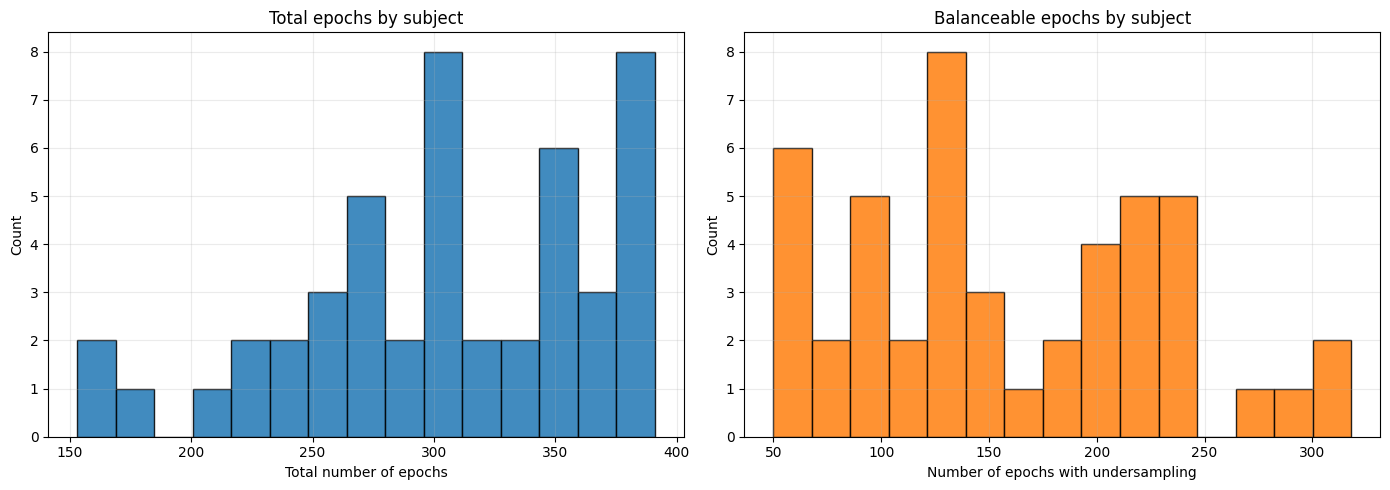

Quick summary:
- Total epochs by subject: min=153, max=391, mitjana=305.7
- 2×min(IM, IP): min=50, max=318, mitjana=160.0


,subject,cohens_d_theta_fcz,cohens_d_alpha_oz,IM,IP,n_balanced_ci
0,P002,0.350567,0.073702,137,103,206
1,P003,0.088348,0.059548,117,193,234
2,P004,0.032875,0.266077,303,65,130
3,P005,-0.190689,-0.130860,169,121,242
4,P008,-0.184958,-0.045135,100,58,116
5,P009,0.023076,-0.118768,236,121,242
6,P010,-0.163259,-0.100670,219,157,314
7,P011,-0.154051,0.161775,281,29,58
8,P013,0.028965,0.238915,193,159,318
9,P014,0.142132,0.356181,210,69,138


In [164]:
# Histograms of epoch availability by subject
# 1) Total number of epochs per subject
#    Here we count all available samples per subject (IM + IP).
df_epochs_subjecte = df_cohens.copy()
df_epochs_subjecte["n_total_epochs"] = df_epochs_subjecte["IM"] + df_epochs_subjecte["IP"]

# 2) Number of swingable epochs per subject: 2 * min(IM, IP)
#    It is the maximum that could be used if you want to balance the classes perfectly.
df_balanceig = df_epochs_subjecte.copy()
df_balanceig["n_balancejable"] = 2 * np.minimum(df_balanceig["IM"], df_balanceig["IP"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram 1: total epochs per subject
axes[0].hist(df_epochs_subjecte["n_total_epochs"], bins=15, color="tab:blue", edgecolor="black", alpha=0.85)
axes[0].set_title("Total epochs by subject")
axes[0].set_xlabel("Total number of epochs")
axes[0].set_ylabel("Count")
axes[0].grid(alpha=0.25)

# Histograma 2: 2 * min(IM, IP)
axes[1].hist(df_balanceig["n_balancejable"], bins=15, color="tab:orange", edgecolor="black", alpha=0.85)
axes[1].set_title("Balanceable epochs by subject")
axes[1].set_xlabel("Number of epochs with undersampling")
axes[1].set_ylabel("Count")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Quick summary:")
print(
    f"- Total epochs by subject: min={df_epochs_subjecte['n_total_epochs'].min():.0f}, max={df_epochs_subjecte['n_total_epochs'].max():.0f}, mitjana={df_epochs_subjecte['n_total_epochs'].mean():.1f}"
)
print(
    f"- 2×min(IM, IP): min={df_balanceig['n_balancejable'].min():.0f}, max={df_balanceig['n_balancejable'].max():.0f}, mitjana={df_balanceig['n_balancejable'].mean():.1f}"
)

# Display of data by subject
display(df_cohens[["subject", "cohens_d_theta_fcz", "cohens_d_alpha_oz", "IM", "IP", "n_balanced_ci"]])

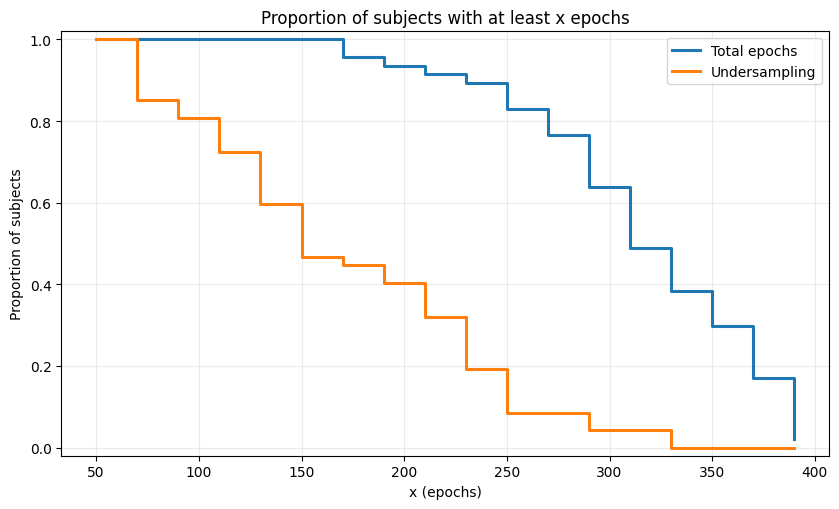

>=  50 epochs -> total: 100.0% | undersampling: 100.0%
>= 100 epochs -> total: 100.0% | undersampling: 72.3%
>= 150 epochs -> total: 100.0% | undersampling: 46.8%
>= 200 epochs -> total: 93.6% | undersampling: 36.2%
>= 250 epochs -> total: 83.0% | undersampling: 8.5%
>= 300 epochs -> total: 59.6% | undersampling: 4.3%
>= 350 epochs -> total: 29.8% | undersampling: 0.0%


In [167]:
# Sister plot: proportion of subjects with >= x epochs
vals_total = df_epochs_subjecte["n_total_epochs"].to_numpy(dtype=float)
vals_us = df_balanceig["n_balancejable"].to_numpy(dtype=float)

x_min = int(min(vals_total.min(), vals_us.min()))
x_max = int(max(vals_total.max(), vals_us.max()))
# Step of 10 epochs to keep the graph clean and interpretable
x_grid = np.arange(x_min, x_max + 1, 20)

prop_total = np.array([(vals_total >= x).mean() for x in x_grid], dtype=float)
prop_us = np.array([(vals_us >= x).mean() for x in x_grid], dtype=float)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.step(x_grid, prop_total, where="post", color="tab:blue", linewidth=2.2, label="Total epochs")
ax.step(x_grid, prop_us, where="post", color="tab:orange", linewidth=2.2, label="Undersampling")

ax.set_title("Proportion of subjects with at least x epochs")
ax.set_xlabel("x (epochs)")
ax.set_ylabel("Proportion of subjects")
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Small numerical summary on some key thresholds
for x in range(50, 351, 50):
    p_total = (vals_total >= x).mean()
    p_us = (vals_us >= x).mean()
    print(f">= {x:3d} epochs -> total: {p_total:.1%} | undersampling: {p_us:.1%}")

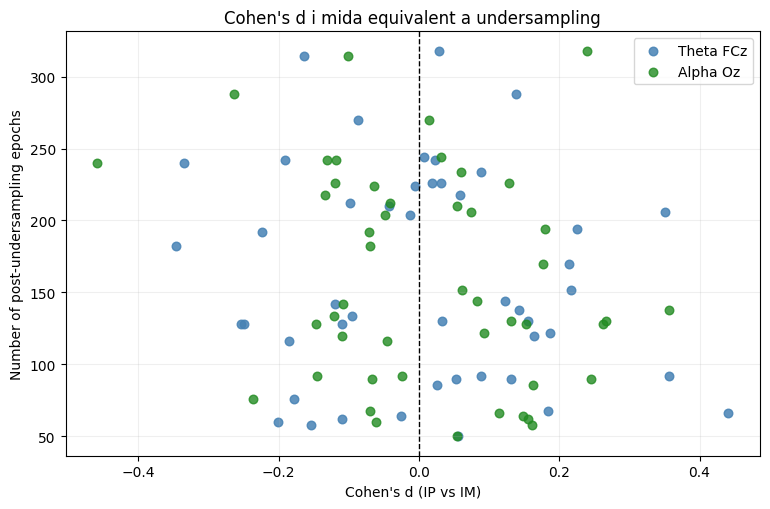

In [168]:
# x = Cohen's d, y = mida equivalent a undersampling
df_plot = df_theta_sorted.copy()
fig, ax = plt.subplots(figsize=(7.8, 5.2))
ax.scatter(
    df_plot["cohens_d_theta_fcz"], df_plot["n_balanced_ci"], color="steelblue", alpha=0.85, s=38, label="Theta FCz"
)
ax.scatter(
    df_plot["cohens_d_alpha_oz"], df_plot["n_balanced_ci"], color="forestgreen", alpha=0.8, s=38, label="Alpha Oz"
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Cohen's d (IP vs IM)")
ax.set_ylabel("Number of post-undersampling epochs")
ax.set_title("Cohen's d i mida equivalent a undersampling")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cohens_d_vs_mida_undersampling_im_vs_ip.png", dpi=300, bbox_inches="tight")
plt.show()

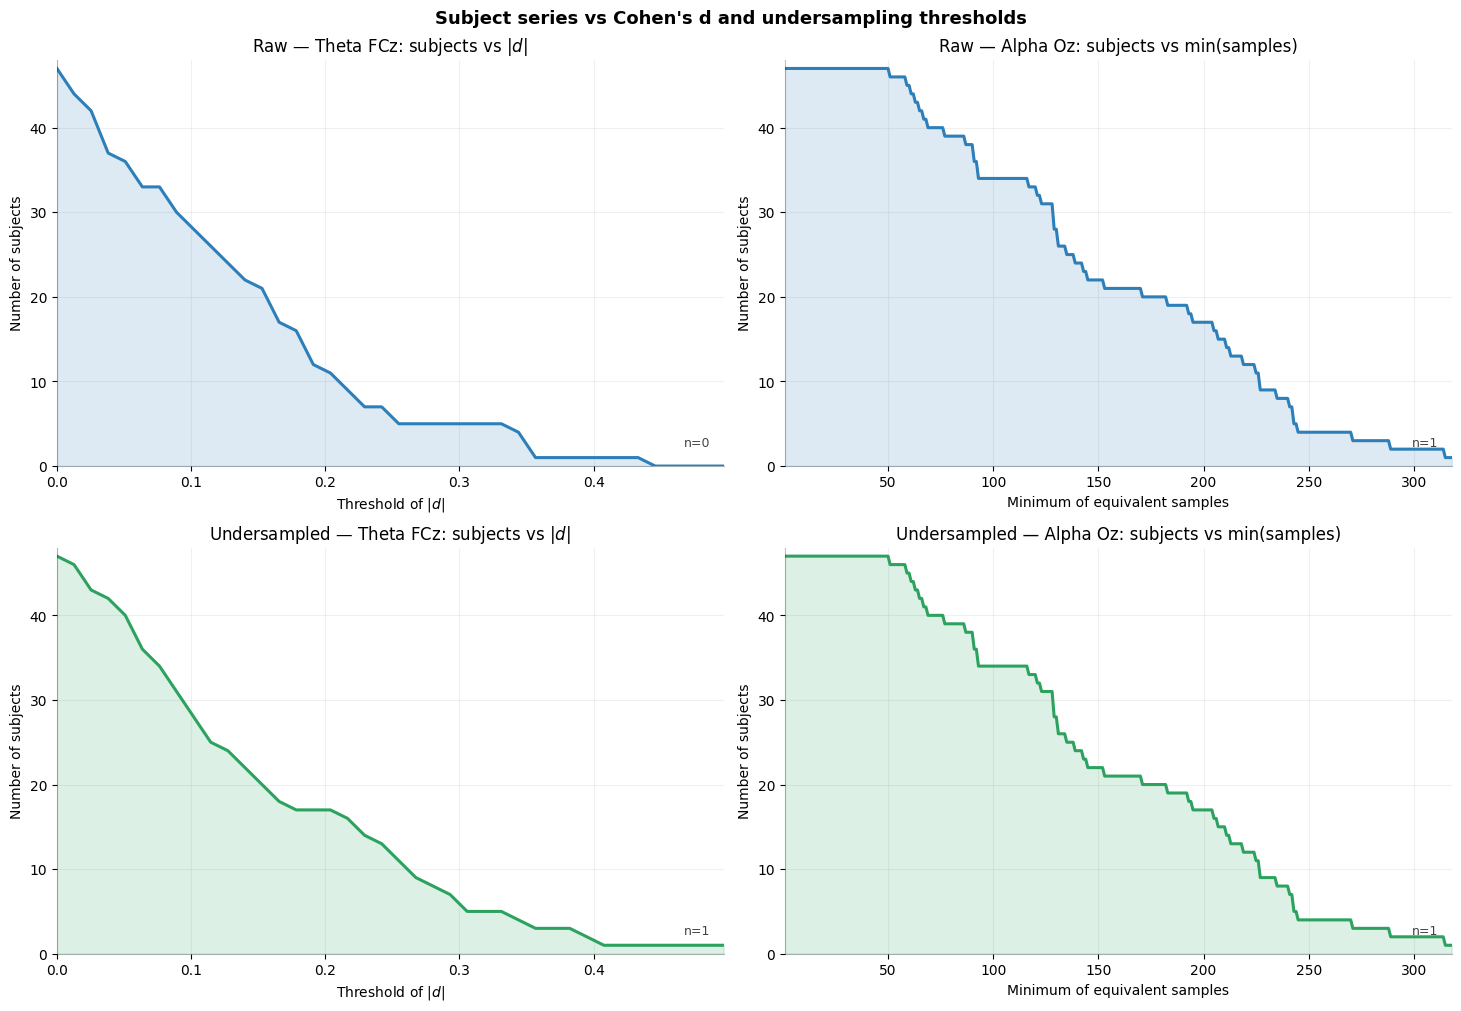

In [169]:
# Series of plots: number of subjects as a function of Cohen's d threshold and minimum samples
# We will make a 2x2 grid with a nested loop: rows = raw/undersampled, columns = |d| and min(samples)

series_specs = [
    (
        "raw",
        {
            "theta": df_cohens["cohens_d_theta_fcz"].abs().to_numpy(),
            "alpha": df_cohens["cohens_d_alpha_oz"].abs().to_numpy(),
        },
    ),
    (
        "undersampled",
        {
            "theta": df_cohens["cohens_d_theta_fcz_us"].abs().to_numpy(),
            "alpha": df_cohens["cohens_d_alpha_oz_us"].abs().to_numpy(),
        },
    ),
]

sample_counts = df_cohens["n_balanced_ci"].to_numpy()
d_limits = {
    "theta": float(np.nanmax(df_cohens[["cohens_d_theta_fcz", "cohens_d_theta_fcz_us"]].abs().to_numpy())),
    "alpha": float(np.nanmax(df_cohens[["cohens_d_alpha_oz", "cohens_d_alpha_oz_us"]].abs().to_numpy())),
}
d_thresholds = {key: np.linspace(0.0, max(value, 1e-6), 40) for key, value in d_limits.items()}
sample_thresholds = np.arange(1, int(np.nanmax(sample_counts)) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14.5, 10), constrained_layout=True)
panel_info = [("theta", "Theta FCz"), ("alpha", "Alpha Oz")]
row_colors = {"raw": "#2C7FB8", "undersampled": "#2CA25F"}
row_titles = {"raw": "Raw", "undersampled": "Undersampled"}

for row_idx, (row_key, values_by_band) in enumerate(series_specs):
    for col_idx, (band_key, band_label) in enumerate(panel_info):
        ax = axes[row_idx, col_idx]
        values = values_by_band[band_key]
        color = row_colors[row_key]

        if col_idx == 0:
            thresholds = d_thresholds[band_key]
            counts = np.array([(values >= thr).sum() for thr in thresholds])
            ax.plot(thresholds, counts, color=color, linewidth=2.2)
            ax.fill_between(thresholds, counts, alpha=0.16, color=color)
            ax.set_xlabel(r"Threshold of $|d|$")
            ax.set_ylabel("Number of subjects")
            ax.set_title(f"{row_titles[row_key]} — {band_label}: subjects vs $|d|$")
            ax.set_xlim(thresholds.min(), thresholds.max())
            ax.set_ylim(0, len(df_cohens) + 1)
        else:
            thresholds = sample_thresholds
            counts = np.array([(sample_counts >= thr).sum() for thr in thresholds])
            ax.plot(thresholds, counts, color=color, linewidth=2.2)
            ax.fill_between(thresholds, counts, alpha=0.16, color=color)
            ax.set_xlabel("Minimum of equivalent samples")
            ax.set_ylabel("Number of subjects")
            ax.set_title(f"{row_titles[row_key]} — {band_label}: subjects vs min(samples)")
            ax.set_xlim(thresholds.min(), thresholds.max())
            ax.set_ylim(0, len(df_cohens) + 1)

        ax.grid(alpha=0.18, linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.spines["left"].set_alpha(0.25)
        ax.spines["bottom"].set_alpha(0.25)
        ax.text(
            0.98,
            0.04,
            f"n={counts[-1]:d}",
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=9,
            color="#444444",
        )

fig.suptitle("Subject series vs Cohen's d and undersampling thresholds", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_subjectes_vs_llindars_nested_grid_im_vs_ip.png", dpi=300, bbox_inches="tight")
plt.show()

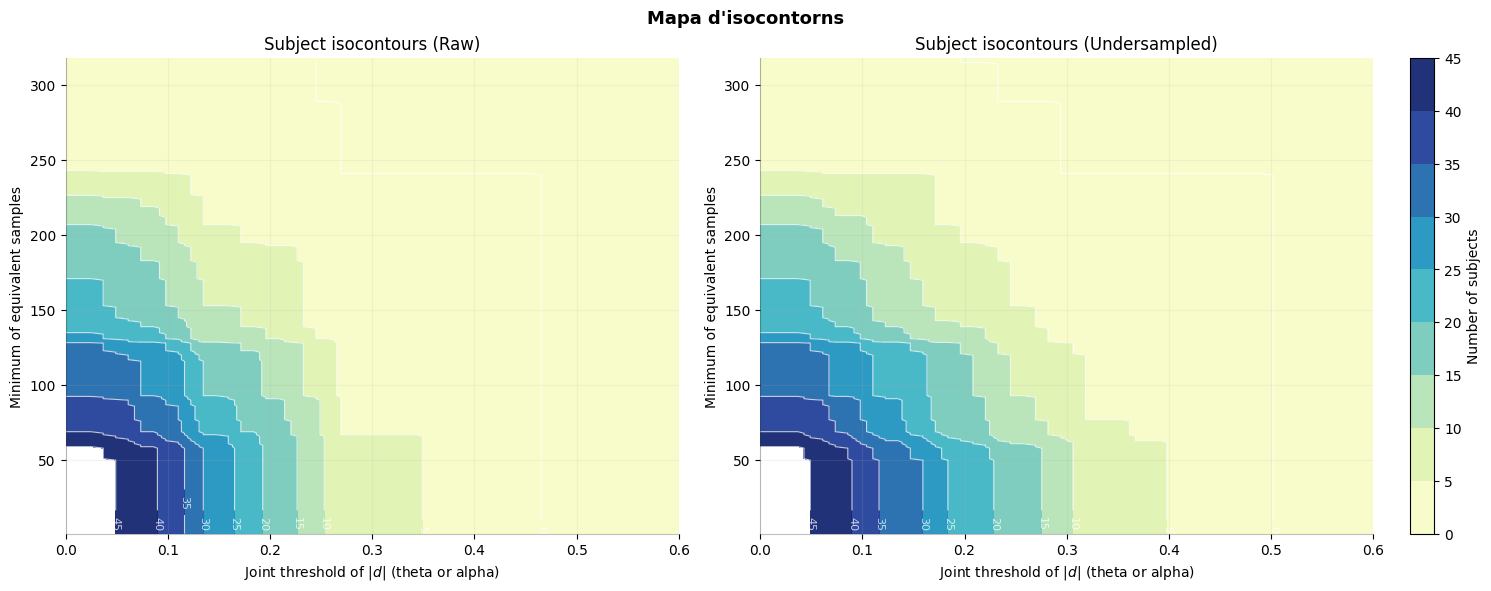

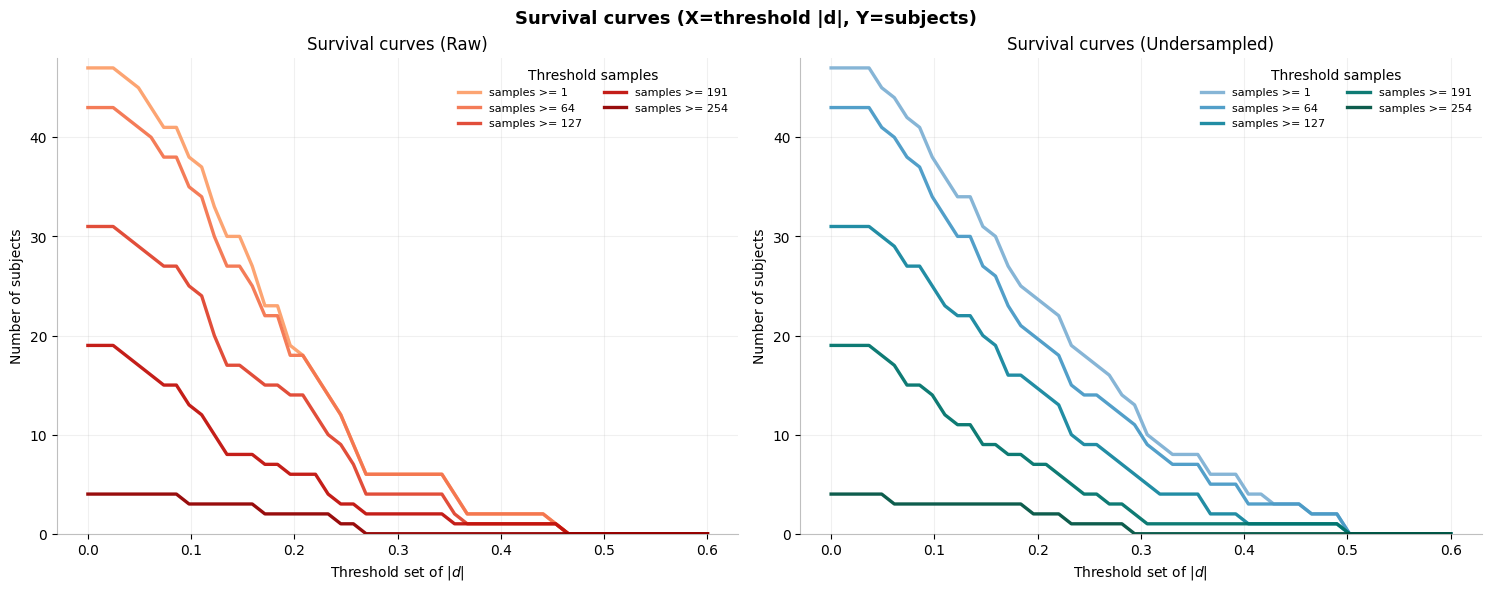

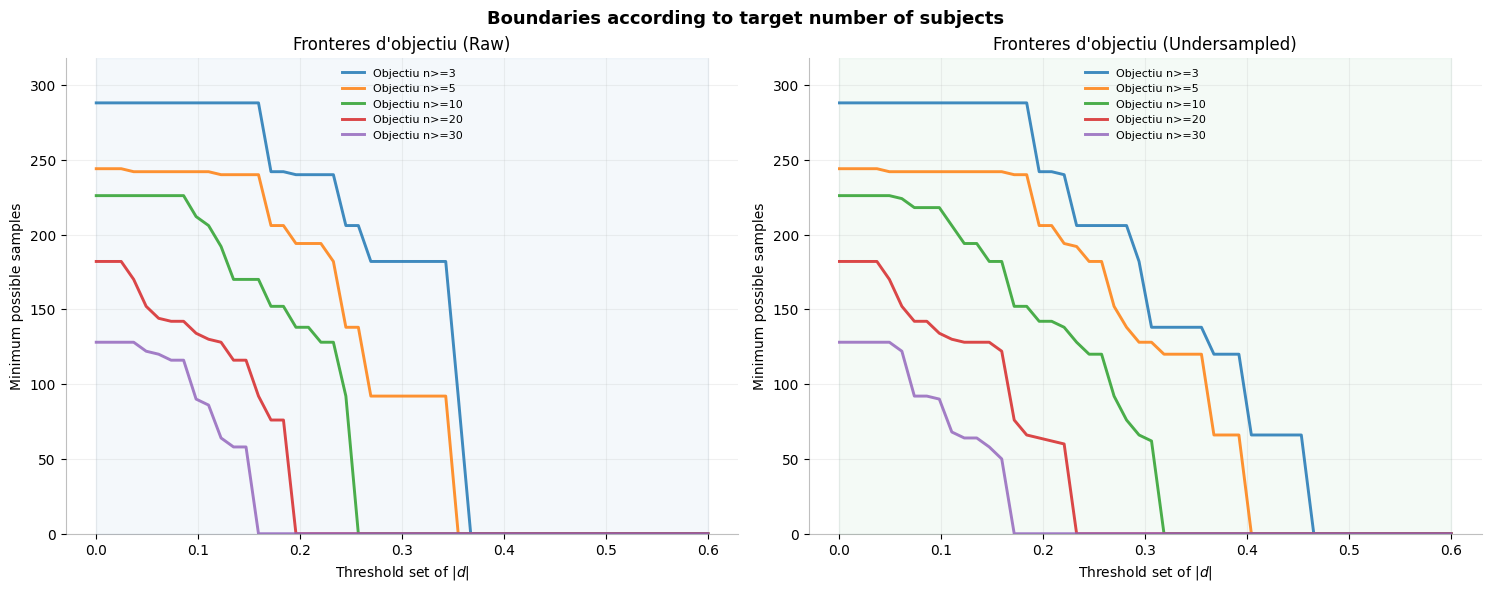

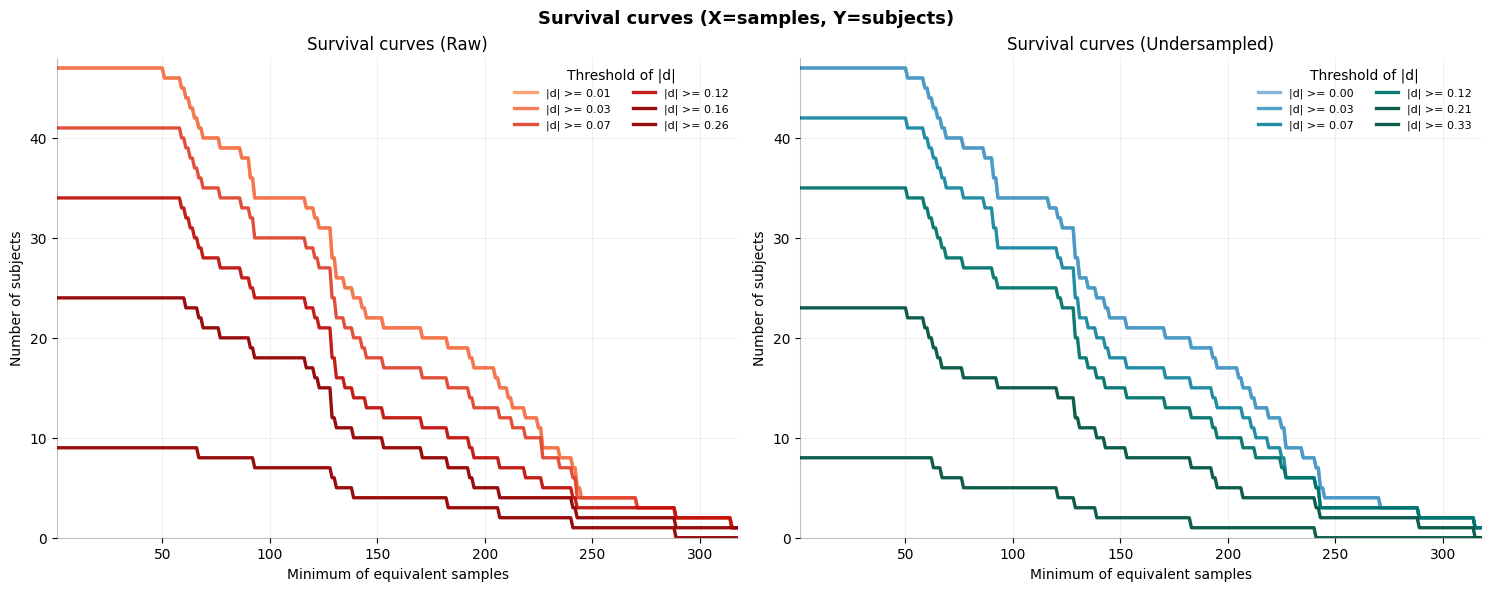

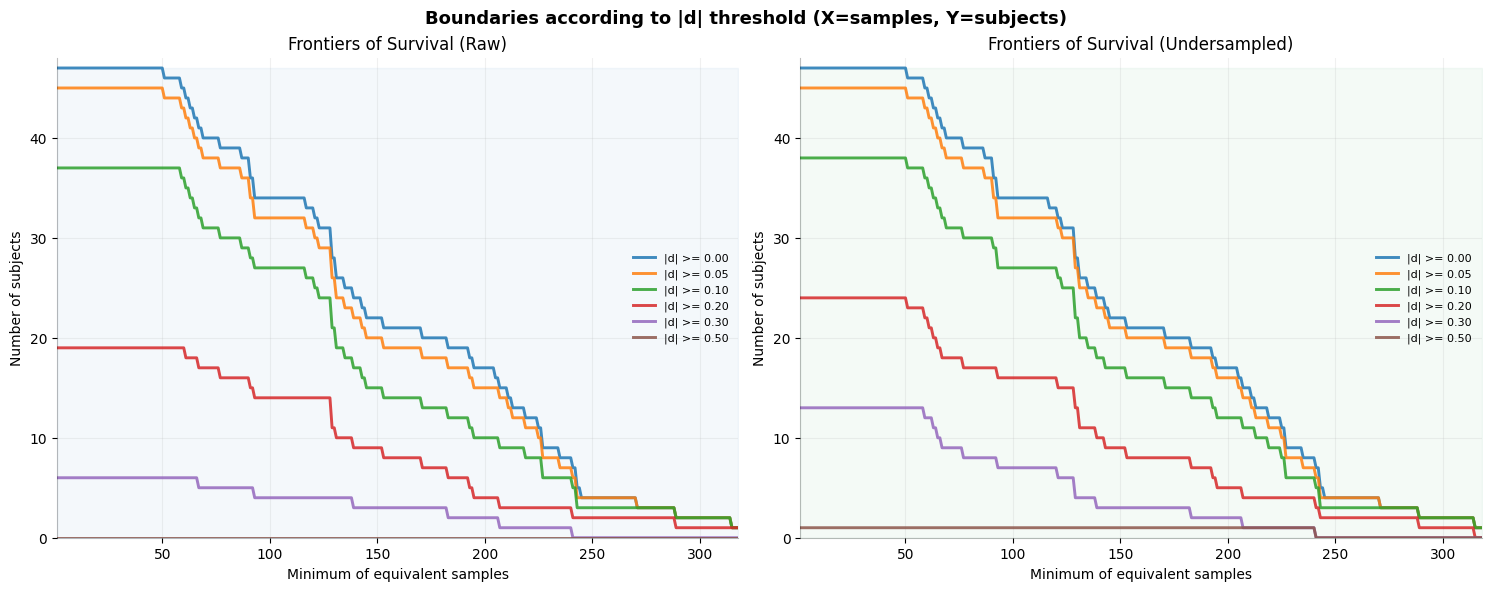

In [170]:
sample_counts = df_cohens["n_balanced_ci"].to_numpy()
d_thr_max = float(
    np.nanmax(
        df_cohens[
            [
                "cohens_d_theta_fcz",
                "cohens_d_alpha_oz",
                "cohens_d_theta_fcz_us",
                "cohens_d_alpha_oz_us",
            ]
        ]
        .abs()
        .to_numpy()
    )
)

d_thresholds = np.linspace(0.0, 0.6, 50)
sample_thresholds = np.arange(1, int(np.nanmax(sample_counts)) + 1)

specs = {
    "Raw": {
        "theta": df_cohens["cohens_d_theta_fcz"].abs().to_numpy(),
        "alpha": df_cohens["cohens_d_alpha_oz"].abs().to_numpy(),
        "color": "#2C7FB8",
    },
    "Undersampled": {
        "theta": df_cohens["cohens_d_theta_fcz_us"].abs().to_numpy(),
        "alpha": df_cohens["cohens_d_alpha_oz_us"].abs().to_numpy(),
        "color": "#2CA25F",
    },
}


def build_grid(theta_vals, alpha_vals, d_thresholds):
    grid = np.zeros((len(sample_thresholds), len(d_thresholds)), dtype=int)
    for i, n_thr in enumerate(sample_thresholds):
        for j, d_thr in enumerate(d_thresholds):
            keep = ((theta_vals >= d_thr) | (alpha_vals >= d_thr)) & (sample_counts >= n_thr)
            grid[i, j] = int(keep.sum())
    return grid


grid_by_name = {name: build_grid(vals["theta"], vals["alpha"], d_thresholds) for name, vals in specs.items()}

# --- Plot A: Isocontorns suaus (raw vs undersampled) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)
for ax, (name, vals) in zip(axes, specs.items()):
    grid = grid_by_name[name]
    levels = np.arange(0, len(df_cohens) + 1, max(1, len(df_cohens) // 8))

    cf = ax.contourf(
        d_thresholds,
        sample_thresholds,
        grid,
        levels=levels,
        cmap="YlGnBu",
        alpha=0.95,
    )
    c = ax.contour(
        d_thresholds,
        sample_thresholds,
        grid,
        levels=levels,
        colors="white",
        linewidths=0.8,
        alpha=0.75,
    )
    ax.clabel(c, fmt="%d", fontsize=8)

    ax.set_title(f"Subject isocontours ({name})")
    ax.set_xlabel(r"Joint threshold of $|d|$ (theta or alpha)")
    ax.set_ylabel("Minimum of equivalent samples")
    ax.grid(alpha=0.14)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02)
cbar.set_label("Number of subjects")
fig.suptitle("Mapa d'isocontorns", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_isocontorns_im_vs_ip.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot B: Classic survival curves (X=threshold |d|, Y=subjects) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

palette_by_name = {
    "Raw": plt.cm.OrRd(np.linspace(0.45, 0.95, 5)),
    "Undersampled": plt.cm.PuBuGn(np.linspace(0.45, 0.95, 5)),
}

for ax, (name, vals) in zip(axes, specs.items()):
    # Include 0 percentile (minimum samples) to see the loosest scenario.
    q_levels = np.quantile(sample_thresholds, [0.0, 0.2, 0.4, 0.6, 0.8]).astype(int)
    q_levels = np.unique(np.clip(q_levels, sample_thresholds.min(), sample_thresholds.max()))
    palette = palette_by_name[name]

    for k, n_thr in enumerate(q_levels):
        counts = []
        for d_thr in d_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            d_thresholds,
            counts,
            color=palette[min(k, len(palette) - 1)],
            linewidth=2.4,
            alpha=0.95,
            label=f"samples >= {n_thr}",
        )

    ax.set_title(f"Survival curves ({name})")
    ax.set_xlabel(r"Threshold set of $|d|$")
    ax.set_ylabel("Number of subjects")
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8, ncol=2, title="Threshold samples")

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Survival curves (X=threshold |d|, Y=subjects)", fontsize=13, fontweight="bold")
plt.savefig(
    FIGURES_DIR / "cohens_d_multicondicions_corbes_supervivencia_x_d_im_vs_ip.png", dpi=300, bbox_inches="tight"
)
plt.show()

# --- Plot C: Classical borders (X=threshold |d|, Y=samples) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

n_targets = [3, 5, 10, 20, 30]
n_targets = [n for n in n_targets if n <= len(df_cohens)]
if len(n_targets) == 0:
    n_targets = [max(1, len(df_cohens) // 2)]

for ax, (name, vals) in zip(axes, specs.items()):
    grid = grid_by_name[name]
    color = vals["color"]

    for target_n in n_targets:
        frontier = []
        for j in range(len(d_thresholds)):
            col = grid[:, j]
            rows_ok = np.where(col >= target_n)[0]
            if len(rows_ok) == 0:
                frontier.append(0)
            else:
                frontier.append(sample_thresholds[rows_ok.max()])

        ax.plot(
            d_thresholds,
            frontier,
            linewidth=2.1,
            alpha=0.85,
            label=f"Objectiu n>={target_n}",
        )

    ax.fill_between(d_thresholds, 0, np.nanmax(sample_thresholds), color=color, alpha=0.05)
    ax.set_title(f"Fronteres d'objectiu ({name})")
    ax.set_xlabel(r"Threshold set of $|d|$")
    ax.set_ylabel("Minimum possible samples")
    ax.set_ylim(0, sample_thresholds.max())
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Boundaries according to target number of subjects", fontsize=13, fontweight="bold")
plt.savefig(FIGURES_DIR / "cohens_d_multicondicions_fronteres_objectiu_x_d_im_vs_ip.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Plot D: New survival curves (X=samples, Y=subjects) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

# Separate vanes to improve visibility between curves and between panels.
palette_by_name = {
    "Raw": plt.cm.OrRd(np.linspace(0.45, 0.95, 5)),
    "Undersampled": plt.cm.PuBuGn(np.linspace(0.45, 0.95, 5)),
}

for ax, (name, vals) in zip(axes, specs.items()):
    # Curves for threshold quantiles of |d|; each point is n_subjects with samples >= x.
    d_pool = np.concatenate([vals["theta"], vals["alpha"]])
    d_levels = np.quantile(d_pool, [0.0, 0.1, 0.3, 0.5, 0.7, 0.9])
    d_levels = np.unique(np.clip(d_levels, d_thresholds.min(), d_thresholds.max()))
    palette = palette_by_name[name]

    for k, d_thr in enumerate(d_levels):
        counts = []
        for n_thr in sample_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            sample_thresholds,
            counts,
            color=palette[min(k, len(palette) - 1)],
            linewidth=2.4,
            alpha=0.95,
            label=f"|d| >= {d_thr:.2f}",
        )

    ax.set_title(f"Survival curves ({name})")
    ax.set_xlabel("Minimum of equivalent samples")
    ax.set_ylabel("Number of subjects")
    ax.set_xlim(sample_thresholds.min(), sample_thresholds.max())
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8, ncol=2, title="Threshold of |d|")

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Survival curves (X=samples, Y=subjects)", fontsize=13, fontweight="bold")
plt.savefig(
    FIGURES_DIR / "cohens_d_multicondicions_corbes_supervivencia_x_samples_im_vs_ip.png", dpi=300, bbox_inches="tight"
)
plt.show()

# --- Plot E: New bounds for fixed thresholds of |d| (X=samples, Y=subjects) ---
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), constrained_layout=True)

d_targets = [0.00, 0.05, 0.10, 0.20, 0.30, 0.50]
d_targets = [d for d in d_targets if d <= d_thresholds.max()]
if len(d_targets) == 0:
    d_targets = [float(d_thresholds.max())]

for ax, (name, vals) in zip(axes, specs.items()):
    color = vals["color"]

    for d_thr in d_targets:
        counts = []
        for n_thr in sample_thresholds:
            keep = ((vals["theta"] >= d_thr) | (vals["alpha"] >= d_thr)) & (sample_counts >= n_thr)
            counts.append(int(keep.sum()))

        ax.plot(
            sample_thresholds,
            counts,
            linewidth=2.1,
            alpha=0.85,
            label=f"|d| >= {d_thr:.2f}",
        )

    ax.fill_between(sample_thresholds, 0, len(df_cohens), color=color, alpha=0.05)
    ax.set_title(f"Frontiers of Survival ({name})")
    ax.set_xlabel("Minimum of equivalent samples")
    ax.set_ylabel("Number of subjects")
    ax.set_xlim(sample_thresholds.min(), sample_thresholds.max())
    ax.set_ylim(0, len(df_cohens) + 1)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.25)
    ax.spines["bottom"].set_alpha(0.25)

fig.suptitle("Boundaries according to |d| threshold (X=samples, Y=subjects)", fontsize=13, fontweight="bold")
plt.savefig(
    FIGURES_DIR / "cohens_d_multicondicions_fronteres_objectiu_x_samples_im_vs_ip.png", dpi=300, bbox_inches="tight"
)
plt.show()

In [171]:
# Minimum number of 100 swingable trials (IM + IP) to guarantee a solid minimum base.
MIN_BALANCED_TRIALS = 100
eligible_subjects = df_cohens[df_cohens["n_balanced_ci"] >= MIN_BALANCED_TRIALS]
print(f"Eligible subjects with >= {MIN_BALANCED_TRIALS} trials balancejables: {len(eligible_subjects)}")
display(
    eligible_subjects[["subject", "cohens_d_theta_fcz_us", "cohens_d_alpha_oz_us", "n_balanced_ci"]]
    .head(10)
    .style.hide(axis="index")
    .format({"n_balanced_ci": "{:.1f}", "score_seleccio": "{:.3f}"})
)

Eligible subjects with >= 100 trials balancejables: 34


subject,cohens_d_theta_fcz_us,cohens_d_alpha_oz_us,n_balanced_ci
P002,0.300925,0.055497,206.0
P003,0.065791,0.066537,234.0
P004,-0.081593,0.202311,130.0
P005,-0.212193,-0.211021,242.0
P008,-0.020687,-0.037664,116.0
P009,0.114491,-0.165120,242.0
P010,-0.224013,-0.093686,314.0
P013,0.036329,0.193189,318.0
P014,0.145959,0.366406,138.0
P015,0.264984,0.125224,194.0


In [172]:
# Final ranking of subjects (undersampled): combine |d| theta, |d| alpha and sample size
def minmax_01(s: pd.Series) -> pd.Series:
    s = s.astype(float)
    lo, hi = float(np.nanmin(s)), float(np.nanmax(s))
    if np.isclose(hi - lo, 0.0):
        return pd.Series(np.zeros(len(s), dtype=float), index=s.index)
    return (s - lo) / (hi - lo)


# These weights can be adjusted if we want to prioritize the effect (Cohen's d) or the sample size more.
W_EFFECT = 0.75
W_SIZE = 0.25

rank_df = eligible_subjects[["subject", "cohens_d_theta_fcz_us", "cohens_d_alpha_oz_us", "n_balanced_ci"]].copy()
rank_df["d_theta_us_abs"] = rank_df["cohens_d_theta_fcz_us"].abs()
rank_df["d_alpha_us_abs"] = rank_df["cohens_d_alpha_oz_us"].abs()

# Combined effect: mean of the two-sided Cohen's d
rank_df["d_combo_us"] = (rank_df["d_theta_us_abs"] + rank_df["d_alpha_us_abs"]) / 2
rank_df["d_combo_us_norm"] = minmax_01(rank_df["d_combo_us"])
rank_df["n_balanced_norm"] = minmax_01(rank_df["n_balanced_ci"])

rank_df["score_seleccio"] = W_EFFECT * rank_df["d_combo_us_norm"] + W_SIZE * rank_df["n_balanced_norm"]

rank_df = rank_df.sort_values("score_seleccio", ascending=False).reset_index(drop=True)

cols_show = [
    "subject",
    "d_theta_us_abs",
    "d_alpha_us_abs",
    "d_combo_us",
    "n_balanced_ci",
    "score_seleccio",
]

print("Top 10 subjects")
display(
    rank_df.head(10)[cols_show]
    .style.hide(axis="index")
    .format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "d_combo_us": "{:.3f}",
            "n_balanced_ci": "{:.1f}",
            "score_seleccio": "{:.3f}",
        }
    )
)

print("Worst 5 subjects")
display(
    rank_df.tail(5)[cols_show]
    .style.hide(axis="index")
    .format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "d_combo_us": "{:.3f}",
            "n_balanced_ci": "{:.1f}",
            "score_seleccio": "{:.3f}",
        }
    )
)

Top 10 subjects


subject,d_theta_us_abs,d_alpha_us_abs,d_combo_us,n_balanced_ci,score_seleccio
P057,0.338,0.501,0.419,240.0,0.903
P053,0.115,0.293,0.204,288.0,0.553
P005,0.212,0.211,0.212,242.0,0.511
P010,0.224,0.094,0.159,314.0,0.500
P014,0.146,0.366,0.256,138.0,0.467
P056,0.392,0.127,0.260,120.0,0.451
P013,0.036,0.193,0.115,318.0,0.421
P015,0.265,0.125,0.195,194.0,0.420
P062,0.356,0.034,0.195,182.0,0.405
P002,0.301,0.055,0.178,206.0,0.403


Worst 5 subjects


subject,d_theta_us_abs,d_alpha_us_abs,d_combo_us,n_balanced_ci,score_seleccio
P058,0.057,0.165,0.111,134.0,0.186
P033,0.053,0.066,0.060,204.0,0.175
P016,0.039,0.011,0.025,244.0,0.158
P046,0.086,0.032,0.059,144.0,0.099
P008,0.021,0.038,0.029,116.0,0.008


In [173]:
# Automatic selection: 5 inflection points of the survival curve
# It identifies real transitions where the subject's fall rate changes significantly
# WITH SEPARATION: points distant from each other

score_thresholds = np.linspace(0.0, 1.0, 101)

# Calculate utility for each threshold
utility_rows = []
for t in score_thresholds:
    sel = rank_df[rank_df["score_seleccio"] >= t]
    n_sel = int(len(sel))
    if n_sel == 0:
        mean_score = np.nan
        utility = np.nan
    else:
        mean_score = float(sel["score_seleccio"].mean())
        utility = float(np.sqrt(n_sel / len(rank_df)) * mean_score)
    utility_rows.append(
        {
            "llindar": float(t),
            "n_subjectes": n_sel,
            "frac_subjectes": n_sel / len(rank_df),
            "score_mitja": mean_score,
            "utility": utility,
        }
    )

df_utility = pd.DataFrame(utility_rows).dropna().sort_values("llindar").reset_index(drop=True)

# For each threshold t, show how many subjects have score >= t.
survival_counts = np.array([(rank_df["score_seleccio"] >= t).sum() for t in score_thresholds], dtype=int)

# Calculate numerical derivative (change of N per threshold step)
diffs = np.diff(survival_counts)
abs_diffs = np.abs(diffs)

# Calculate "acceleration" (change in derivative - where the velocity of fall changes)
accel = np.diff(abs_diffs)

# Identify points where there are acceleration peaks (transitions)
threshold_accel = np.percentile(accel, 80)  # Top 30% changes
inflection_indices = np.where(accel > threshold_accel)[0]

# Group close indexes (avoid duplicates)
if len(inflection_indices) > 0:
    inflection_points = []
    current_group = [inflection_indices[0]]
    for i in range(1, len(inflection_indices)):
        if inflection_indices[i] - inflection_indices[i - 1] <= 2:
            current_group.append(inflection_indices[i])
        else:
            inflection_points.append(int(np.mean(current_group)))
            current_group = [inflection_indices[i]]
    inflection_points.append(int(np.mean(current_group)))
else:
    inflection_points = []

# Convert to df_utility indexes
inflection_thresholds = []
for idx in inflection_points:
    if idx < len(score_thresholds):
        thr = score_thresholds[idx]
        # Find the closest threshold in df_utility
        closest_idx = int((df_utility["llindar"] - thr).abs().idxmin())
        if closest_idx not in [x[0] for x in inflection_thresholds]:
            n_subj = int(df_utility.loc[closest_idx, "n_subjectes"])
            score_mean = float(df_utility.loc[closest_idx, "score_mitja"])
            utility_val = float(df_utility.loc[closest_idx, "utility"])
            inflection_thresholds.append((closest_idx, thr, n_subj, score_mean, utility_val))

# Sort by descending utility
inflection_thresholds_sorted = sorted(inflection_thresholds, key=lambda x: x[4], reverse=True)

# Select 5 points with minimum separability (minimum distance between thresholds: 0.05)
MIN_THRESHOLD_GAP = 0.05
selected_points = []
for idx, thr, n_subj, score_mean, util in inflection_thresholds_sorted:
    # Check if this point is far enough from those already selected
    if len(selected_points) == 0:
        selected_points.append((idx, thr, n_subj, score_mean, util))
    else:
        min_gap_to_existing = min(abs(thr - sp[1]) for sp in selected_points)
        if min_gap_to_existing >= MIN_THRESHOLD_GAP:
            selected_points.append((idx, thr, n_subj, score_mean, util))
    if len(selected_points) == 5:
        break

# Convertir a DataFrame final
selected_indices = [sp[0] for sp in selected_points]
df_key = (
    df_utility.loc[selected_indices, ["llindar", "n_subjectes", "score_mitja", "utility"]]
    .sort_values("llindar")  # Sort by increasing threshold for best display
    .reset_index(drop=True)
)

display(
    df_key.style.hide(axis="index").format(
        {
            "llindar": "{:.3f}",
            "n_subjectes": "{:d}",
            "score_mitja": "{:.3f}",
            "utility": "{:.3f}",
        }
    )
)

# Show top-10 and automatic selection by reference
top_pairs = [
    (row["subject"], f"{row['score_seleccio']:.2f}")
    for _, row in rank_df.head(10)[["subject", "score_seleccio"]].iterrows()
]

auto_threshold = float(df_key.loc[0, "llindar"])  # Best proposition for utility
auto_df = rank_df[rank_df["score_seleccio"] >= auto_threshold][["subject", "score_seleccio"]]
auto_pairs = [(row["subject"], f"{row['score_seleccio']:.2f}") for _, row in auto_df.iterrows()]

print(f"Top-10 (Subj, score):")
print(top_pairs)
print(f"\nAutomatic selection (Proposition 1, Subj, score) [{len(auto_pairs)}]:")
print(auto_pairs)

llindar,n_subjectes,score_mitja,utility
0.080,33,0.328,0.323
0.150,32,0.335,0.325
0.200,29,0.352,0.325
0.310,15,0.455,0.302
0.400,11,0.494,0.281


Top-10 (Subj, score):
[('P057', '0.90'), ('P053', '0.55'), ('P005', '0.51'), ('P010', '0.50'), ('P014', '0.47'), ('P056', '0.45'), ('P013', '0.42'), ('P015', '0.42'), ('P062', '0.40'), ('P002', '0.40')]

Automatic selection (Proposition 1, Subj, score) [33]:
[('P057', '0.90'), ('P053', '0.55'), ('P005', '0.51'), ('P010', '0.50'), ('P014', '0.47'), ('P056', '0.45'), ('P013', '0.42'), ('P015', '0.42'), ('P062', '0.40'), ('P002', '0.40'), ('P021', '0.40'), ('P009', '0.37'), ('P031', '0.37'), ('P067', '0.33'), ('P017', '0.32'), ('P023', '0.28'), ('P024', '0.27'), ('P030', '0.27'), ('P045', '0.26'), ('P022', '0.26'), ('P068', '0.25'), ('P051', '0.25'), ('P004', '0.24'), ('P061', '0.23'), ('P003', '0.22'), ('P066', '0.22'), ('P065', '0.21'), ('P025', '0.21'), ('P048', '0.20'), ('P058', '0.19'), ('P033', '0.18'), ('P016', '0.16'), ('P046', '0.10')]


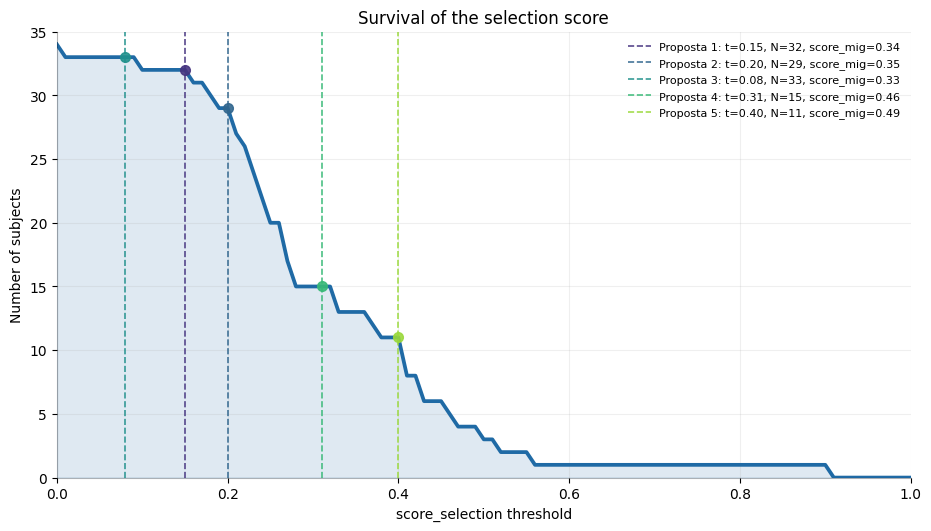

In [174]:
# Selection score survival plot with proposed thresholds

# We order proposals by balance (utility): Proposal 1 = best, ..., Proposal 5 = fifth best.
proposed_df = (
    df_key.sort_values("utility", ascending=False)
    .dropna(subset=["llindar"])
    .drop_duplicates(subset=["llindar"], keep="first")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
ax.plot(
    score_thresholds,
    survival_counts,
    color="#1f6aa5",
    linewidth=2.7,
)
ax.fill_between(score_thresholds, survival_counts, color="#1f6aa5", alpha=0.14)

th_colors = plt.cm.viridis(np.linspace(0.15, 0.85, max(1, len(proposed_df))))
proposal_handles = []
proposal_labels = []
for i, (_, row) in enumerate(proposed_df.iterrows()):
    thr = float(row["llindar"])
    n_subj = int(row["n_subjectes"])
    score_mean = float(row["score_mitja"])

    # Vertical line on the threshold
    line = ax.axvline(
        thr,
        color=th_colors[i],
        linestyle="--",
        linewidth=1.2,
        alpha=0.9,
    )

    # Marker (point) at the intersection with the curve
    ax.plot(thr, n_subj, "o", color=th_colors[i], markersize=7, alpha=0.9, zorder=5)

    proposal_handles.append(line)
    proposal_labels.append(f"Proposta {i + 1}: t={thr:.2f}, N={n_subj}, score_mig={score_mean:.2f}")

ax.set_title("Survival of the selection score")
ax.set_xlabel("score_selection threshold")
ax.set_ylabel("Number of subjects")
ax.set_xlim(0, 1)
ax.set_ylim(0, len(rank_df) + 1)
ax.grid(alpha=0.2)

# Legend only with proposals, to maximize interpretability.
ax.legend(proposal_handles, proposal_labels, frameon=False, loc="upper right", fontsize=8)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_alpha(0.25)
ax.spines["bottom"].set_alpha(0.25)

plt.savefig(FIGURES_DIR / "cohens_d_score_seleccio_survival_im_vs_ip.png", dpi=300, bbox_inches="tight")
plt.show()

### Subjectes seleccionats IM vs IP

In [177]:
# All subjects selected by the automatic criterion, ordered by score
subjectes_seleccionats_df = rank_df[rank_df["score_seleccio"] >= auto_threshold][
    ["subject", "d_theta_us_abs", "d_alpha_us_abs", "n_balanced_ci", "score_seleccio"]
]

subjectes_seleccionats_df = subjectes_seleccionats_df.rename(columns={"n_balanced_ci": "n_mostres"})
subjectes_seleccionats_df["n_mostres"] = subjectes_seleccionats_df["n_mostres"].astype("Int64")

subjectes_seleccionats_df = subjectes_seleccionats_df.sort_values("score_seleccio", ascending=False).reset_index(
    drop=True
)

# Single selection dataset: The classification notebook will now be able to decide how many to take
subjectes_seleccionats_df.to_csv(TABLES_DIR / "subjectes_seleccionats_im_vs_ip.csv", index=False)

print(f"Selected subjects saved: {len(subjectes_seleccionats_df)}")
display(
    subjectes_seleccionats_df.style.hide(axis="index").format(
        {
            "d_theta_us_abs": "{:.3f}",
            "d_alpha_us_abs": "{:.3f}",
            "score_seleccio": "{:.3f}",
            "n_mostres": "{:d}",
        }
    )
)

Selected subjects saved: 33


subject,d_theta_us_abs,d_alpha_us_abs,n_mostres,score_seleccio
P057,0.338,0.501,240,0.903
P053,0.115,0.293,288,0.553
P005,0.212,0.211,242,0.511
P010,0.224,0.094,314,0.500
P014,0.146,0.366,138,0.467
P056,0.392,0.127,120,0.451
P013,0.036,0.193,318,0.421
P015,0.265,0.125,194,0.420
P062,0.356,0.034,182,0.405
P002,0.301,0.055,206,0.403


## Part 1: Individual exploration (P002)
I start with a single participant/subject to familiarize myself with the data and make simple plots. Then I will go on to do the grand average with all the subjects.

### ERP (time vs. voltage)
Mean signal ± SEM for Fz, FCz, Cz. It serves as a sanity check: if the stimulus produces a clear and consistent evoked response across conditions, the data are good.

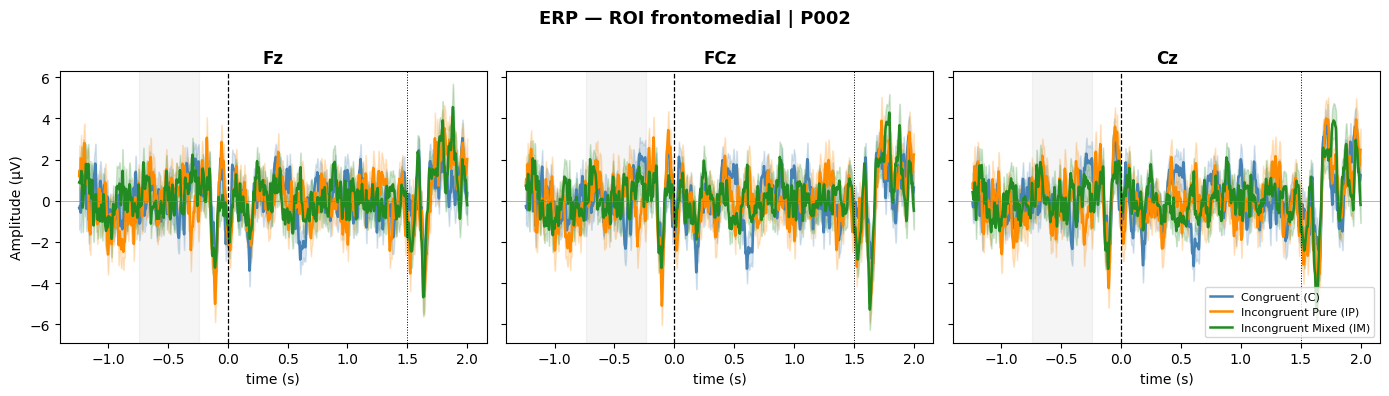

In [184]:
fig, axes = plt.subplots(1, len(ROI_FRONTAL), figsize=(14, 4), sharey=True)
times = epochs_all.times

for ax, ch in zip(axes, ROI_FRONTAL):
    for cond, ep in epochs_cond.items():
        if cond == "Incongruent":
            continue
        data = ep.get_data(picks=[ch]).squeeze() * 1e6
        mean, sem = data.mean(axis=0), data.std(axis=0) / np.sqrt(len(ep))
        ax.plot(times, mean, label=LABELS[cond], color=COLORS[cond], linewidth=1.8)
        ax.fill_between(times, mean - sem, mean + sem, color=COLORS[cond], alpha=0.2)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.9)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.7)
    ax.axhline(0, color="gray", linewidth=0.4)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08)
    ax.set_title(ch, fontsize=12, fontweight="bold")
    ax.set_xlabel("time (s)")

axes[0].set_ylabel("Amplitude (µV)")
axes[-1].legend(fontsize=8, loc="lower right")
fig.suptitle(f"ERP — ROI frontomedial | {SUBJ}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "erp_roi_frontomedial_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### Theta power time-course (time vs. power, dB)
Theta power (5–7 Hz) baseline-corrected, averaged over Fz/FCz/Cz.
**This is the central plot of the TFG**: If conflict activates the monitoring system, IP should show more theta power than C during stimulus presentation.
Equivalent to Figure 2B of the article.

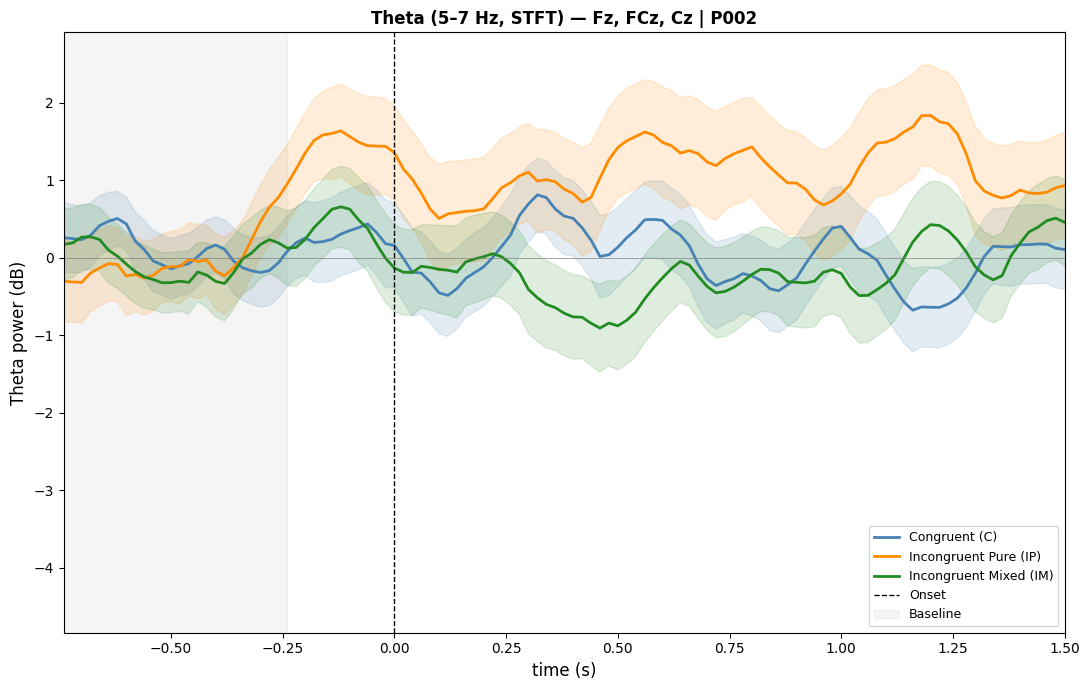

In [186]:
theta_tc = {}
for cond, ep in epochs_cond.items():
    t, mean_ts, sem_ts = stft_band_timecourse(ep, ROI_FRONTAL, band=(5, 7), baseline=BASELINE)
    theta_tc[cond] = (t, mean_ts, sem_ts)

# Baseline correction: subtract the average of the baseline period
baseline_mask = (t >= BASELINE[0]) & (t <= BASELINE[1])
baseline_mean = np.mean([ts[baseline_mask].mean() for ts in [power_ts for _, (_, power_ts, _) in theta_tc.items()]])

fig, ax = plt.subplots(figsize=(11, 7))
for cond, (times, power_ts, sem_ts) in theta_tc.items():
    if cond == "Incongruent":
        continue
    power_corrected = power_ts - baseline_mean
    ax.plot(times, power_corrected, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times, power_corrected - sem_ts, power_corrected + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
ax.set_xlabel("time (s)", fontsize=12)
ax.set_ylabel("Theta power (dB)", fontsize=12)
ax.set_title(f"Theta (5–7 Hz, STFT) — Fz, FCz, Cz | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "theta_5_7hz_stft_roi_frontal_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### TFR differential map. Figure 3 (A and C)
Power difference (IP−C and IP−IM) across the spectrum and all electrodes. 
Red = more power in IP; blue = less. The theta and alpha bands marked.

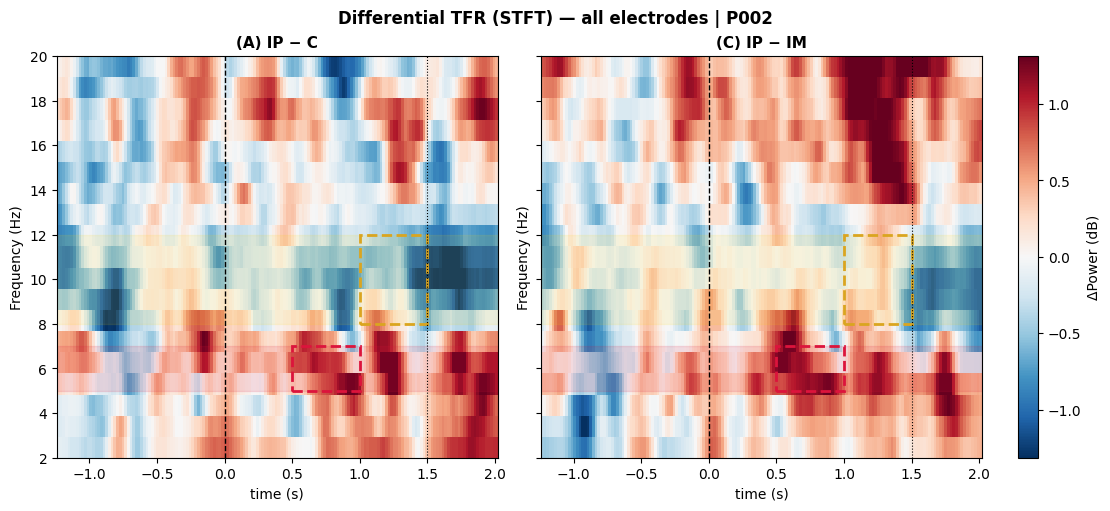

In [188]:
tfr_cond_mean = {}
for cond, ep in epochs_cond.items():
    f, t, mean_db = stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4)
    tfr_cond_mean[cond] = {"freqs": f, "times": t, "mean_db": mean_db}  # (n_freq, n_t)

# Baseline correction for each condition
baseline_mask = (tfr_cond_mean["Congruent"]["times"] >= BASELINE[0]) & (
    tfr_cond_mean["Congruent"]["times"] <= BASELINE[1]
)
for cond in tfr_cond_mean:
    baseline_mean = tfr_cond_mean[cond]["mean_db"][:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_cond_mean[cond]["mean_db"] -= baseline_mean

contrasts = [
    ("A", "Incongruent_Pure", "Congruent", "IP − C"),
    ("C", "Incongruent_Pure", "Incongruent_Mixed", "IP − IM"),
]
raw_diffs = [tfr_cond_mean[ca]["mean_db"] - tfr_cond_mean[cb]["mean_db"] for _, ca, cb, _ in contrasts]
VLIM = float(np.quantile(np.abs(np.concatenate([d.ravel() for d in raw_diffs])), 0.98))
VLIM = max(VLIM, 1e-6)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, constrained_layout=True)
for ax, (panel, ca, cb, title), diff in zip(axes, contrasts, raw_diffs):
    t = tfr_cond_mean[ca]["times"]
    f = tfr_cond_mean[ca]["freqs"]
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        extent=[t[0], t[-1], f[0], f[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="nearest",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.axhspan(5, 7, color="crimson", alpha=0.12)
    ax.axhspan(8, 12, color="gold", alpha=0.10)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="goldenrod", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(2, 20)

fig.colorbar(im, ax=axes.ravel().tolist(), location="right", fraction=0.046, pad=0.03, label="ΔPower (dB)")
fig.suptitle(f"Differential TFR (STFT) — all electrodes | {SUBJ}", fontsize=12, fontweight="bold")
plt.savefig(FIGURES_DIR / "tfr_diferencial_stft_tots_electrodes_individual.png", dpi=300, bbox_inches="tight")
plt.show()

### Alpha suppression. Figure 4A
Alpha power (8–12 Hz) over parieto-occipital ROI. Alpha suppression = greater visual activation.
Hypothesis: IP and IM should show more suppression (lower values) than C.

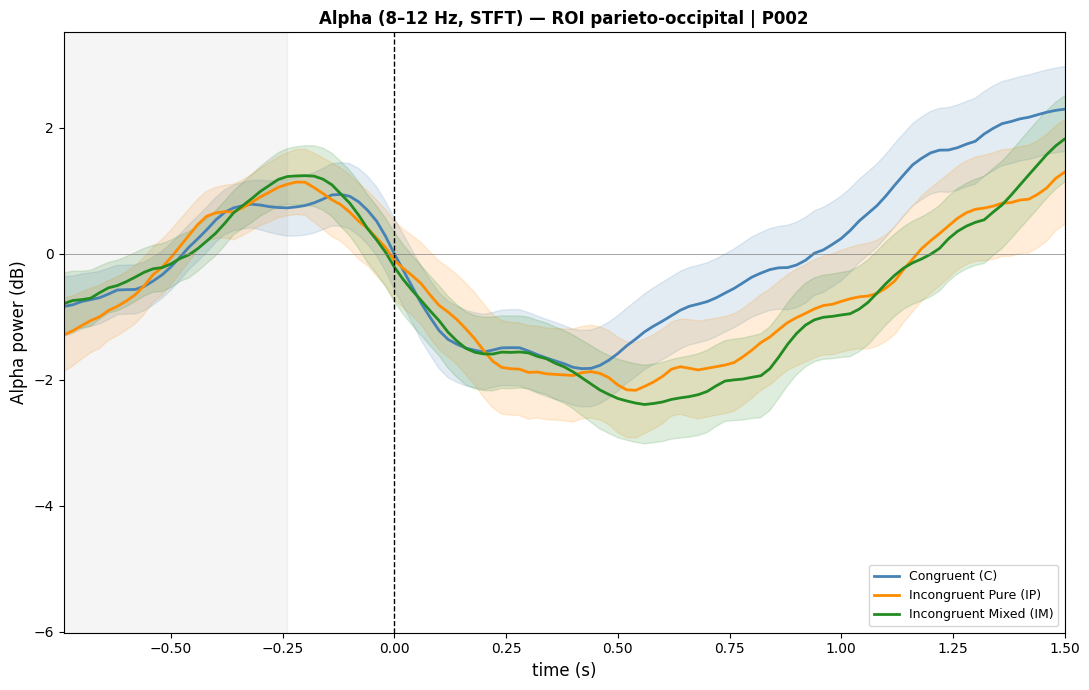

In [189]:
alpha_tc = {}
for cond, ep in epochs_cond.items():
    po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
    if not po_ok:
        continue
    t, mean_ts, sem_ts = stft_band_timecourse(ep, po_ok, band=(8, 12), baseline=BASELINE)
    alpha_tc[cond] = (t, mean_ts, sem_ts)

# Baseline correction: make baseline period average 0 (same 'nudge' for all conditions)
times = next(iter(alpha_tc.values()))[0]
baseline_mask = (times >= BASELINE[0]) & (times <= BASELINE[1])
baseline_mean = np.mean([power_ts[baseline_mask].mean() for _, (_, power_ts, _) in alpha_tc.items()])

fig, ax = plt.subplots(figsize=(11, 7))
for cond, (times, power_ts, sem_ts) in alpha_tc.items():
    if cond == "Incongruent":
        continue
    power_corrected = power_ts - baseline_mean
    ax.plot(times, power_corrected, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times, power_corrected - sem_ts, power_corrected + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("time (s)", fontsize=12)
ax.set_ylabel("Alpha power (dB)", fontsize=12)
ax.set_title(f"Alpha (8–12 Hz, STFT) — ROI parieto-occipital | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alpha_8_12hz_stft_roi_parieto_occipital_individual.png", dpi=300, bbox_inches="tight")
plt.show()

---

## Part 3: Average over all subjects

The loop loads each subject, calculates theta and alpha TFRs, and accumulates the time-courses.
At the end the average between subjects is taken and the same graphs are replotted with true SEM between subjects.

In [ ]:
# Path to save/load cached results
CACHE_FILE = ANALYSIS_ROOT / "cache_processament_subjectes.pkl"

# 1. Try to load from the cache if it exists
if CACHE_FILE.exists():
    print(f"Loading precalculated results from cache...")
    with open(CACHE_FILE, "rb") as f:
        cache_data = pickle.load(f)

    all_theta = cache_data["all_theta"]
    all_alpha = cache_data["all_alpha"]
    subjects_inclosos = cache_data["subjectes_inclosos"]
    ga_tfr_sum = cache_data["ga_tfr_sum"]
    ga_tfr_n = cache_data["ga_tfr_n"]
    times_ga = cache_data["times_ga"]
    freqs_tfr_ga = cache_data["freqs_tfr_ga"]
    times_tfr_ga = cache_data["times_tfr_ga"]

    print(f"✓ Cache loaded: {len(subjectes_inclosos)} subjects")
else:
    # Function that processes ONE file and returns its results.
    def processa_un_subjecte(fif_path):
        subj_id = fif_path.stem
        ep_all, ep_cond = load_subject(fif_path)

        # Local dictionary to store this subject's work
        res = {
            "subj_id": subj_id,
            "theta": {},
            "alpha": {},
            "ga_sum": {},
            "freqs": None,
            "times": None,
            "times_ga": None,
        }

        try:
            for cond, ep in ep_cond.items():
                if len(ep) == 0:
                    continue

                # Theta
                t, ts_theta, _ = stft_band_timecourse(ep, ROI_FRONTAL, band=(5, 7))
                res["theta"][cond] = ts_theta
                if res["times_ga"] is None:
                    res["times_ga"] = t

                # Alpha
                po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
                if po_ok:
                    _, ts_alpha, _ = stft_band_timecourse(ep, po_ok, band=(8, 12))
                    res["alpha"][cond] = ts_alpha

                # TFR Global (ch_block=2 to reduce memory)
                f_tfr, t_tfr, mean_db = stft_condition_mean_db_chunked(
                    ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=2
                )

                res["ga_sum"][cond] = mean_db

                if res["freqs"] is None:
                    res["freqs"] = f_tfr
                    res["times"] = t_tfr

        finally:
            del ep_cond, ep_all
            gc.collect()

        return res

    # 2. Sequential processing to reduce memory spikes
    fif_files = sorted(DATA_DIR.glob("*.fif"))[
        :2
    ]  # TEST: Only 2 subjects for debugging - change [:2] to [:] for full run

    all_theta = {cond: [] for cond in COND_EVENTS_CODES}
    all_alpha = {cond: [] for cond in COND_EVENTS_CODES}
    subjects_inclosos = []
    ga_tfr_sum = {}
    ga_tfr_n = {cond: 0 for cond in COND_EVENTS_CODES}
    times_ga, freqs_tfr_ga, times_tfr_ga = None, None, None

    print(f"Starting sequential processing of {len(fif_files)} subjects...")
    for ruta in fif_files:
        res = processa_un_subjecte(ruta)
        subjects_inclosos.append(res["subj_id"])

        if times_ga is None and res["times_ga"] is not None:
            times_ga = res["times_ga"]
        if freqs_tfr_ga is None and res["freqs"] is not None:
            freqs_tfr_ga = res["freqs"]
            times_tfr_ga = res["times"]

        for cond in COND_EVENTS_CODES:
            if cond in res["theta"]:
                all_theta[cond].append(res["theta"][cond])
            if cond in res["alpha"]:
                all_alpha[cond].append(res["alpha"][cond])

            if cond in res["ga_sum"]:
                if cond not in ga_tfr_sum:
                    ga_tfr_sum[cond] = np.zeros_like(res["ga_sum"][cond], dtype=np.float32)
                ga_tfr_sum[cond] += res["ga_sum"][cond].astype(np.float32, copy=False)
                ga_tfr_n[cond] += 1

        del res
        gc.collect()

    print(f"✓ Processing completed: {len(subjectes_inclosos)} subjects.")

    # 3. Save the results in cache for future executions
    print(f"\nDesant resultats en cache: {CACHE_FILE}")
    cache_data = {
        "all_theta": all_theta,
        "all_alpha": all_alpha,
        "subjectes_inclosos": subjects_inclosos,
        "ga_tfr_sum": ga_tfr_sum,
        "ga_tfr_n": ga_tfr_n,
        "times_ga": times_ga,
        "freqs_tfr_ga": freqs_tfr_ga,
        "times_tfr_ga": times_tfr_ga,
    }
    with open(CACHE_FILE, "wb") as f:
        pickle.dump(cache_data, f)
    print(f"✓ Cache guardat correctament")

Iniciant processament seqüencial de 47 subjectes...

Inclosos : 47 subjectes.


### Differential TFR map (grand average)
Same calculation as in the individual case, but looping through the subjects one by one and accumulating only the mean TFR map per condition to reduce memory usage.

In [ ]:
# Only keep the keys of interest for subsequent analyzes (C, IP, IM)
all_alpha_cipim = {
    cond: all_alpha[cond] for cond in ["Congruent", "Incongruent_Pure", "Incongruent_Mixed"] if all_alpha[cond]
}
all_theta_cipim = {
    cond: all_theta[cond] for cond in ["Congruent", "Incongruent_Pure", "Incongruent_Mixed"] if all_theta[cond]
}
ga_tfr_sum_cipim = {
    cond: ga_tfr_sum[cond] for cond in ["Congruent", "Incongruent_Pure", "Incongruent_Mixed"] if cond in ga_tfr_sum
}
ga_tfr_n_cipim = {cond: ga_tfr_n[cond] for cond in ["Congruent", "Incongruent_Pure", "Incongruent_Mixed"]}

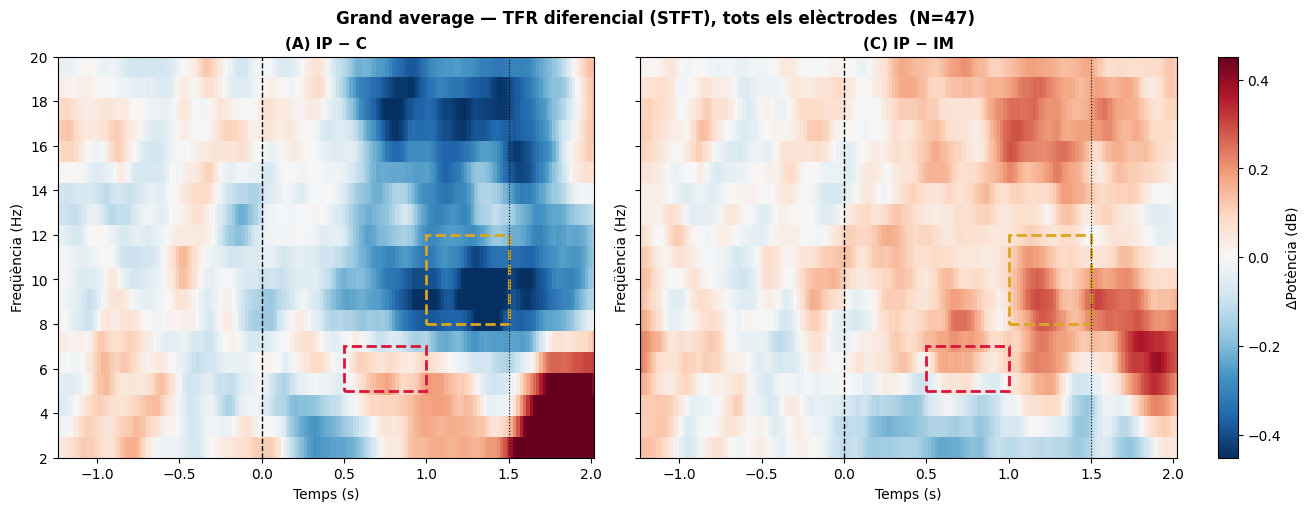

Subjectes contribuents per condició:
  Congruent (C)           : 47
  Incongruent Pur (IP)    : 47
  Incongruent Mixt (IM)   : 47
  Incongruent (I)         : 47
  Errors                  : 36


In [ ]:
tfr_ga_mean = {}
for cond, sum_db in ga_tfr_sum_cipim.items():
    if ga_tfr_n_cipim[cond] > 0:
        tfr_ga_mean[cond] = sum_db / ga_tfr_n_cipim[cond]

contrasts = [
    ("A", "Incongruent_Pure", "congruent", "IP − C"),
    ("C", "Incongruent_Pure", "Incongruent_Mixed", "IP − IM"),
]
raw_diffs = [tfr_ga_mean[ca] - tfr_ga_mean[cb] for _, ca, cb, _ in contrasts]
VLIM = float(np.quantile(np.abs(np.concatenate([d.ravel() for d in raw_diffs])), 0.98))
VLIM = max(VLIM, 1e-6)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
for ax, (panel, ca, cb, title), diff in zip(axes, contrasts, raw_diffs):
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        extent=[times_tfr_ga[0], times_tfr_ga[-1], freqs_tfr_ga[0], freqs_tfr_ga[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="nearest",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="goldenrod", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(2, 20)

fig.colorbar(im, ax=axes.ravel().tolist(), location="right", fraction=0.046, pad=0.03, label="ΔPower (dB)")

conds_used = sorted({ca for _, ca, _, _ in contrasts} | {cb for _, _, cb, _ in contrasts})
n_tfr = min(ga_tfr_n[c] for c in conds_used)
fig.suptitle(
    f"Grand average — differential TFR (STFT), all electrodes (N={n_tfr})",
    fontsize=12,
    fontweight="bold",
)
plt.savefig(FIGURES_DIR / "grand_average_tfr_diferencial_stft_tots_electrodes.png", dpi=300, bbox_inches="tight")
plt.show()

print("Contributing subjects by condition:")
for cond in COND_EVENTS_CODES:
    print(f"  {LABELS[cond]:24s}: {ga_tfr_n[cond]:2d}")

### Theta power time-course
Each line is the mean across subjects. The shaded area is the SEM between subjects (not between trials or between channels as in the individual plots).

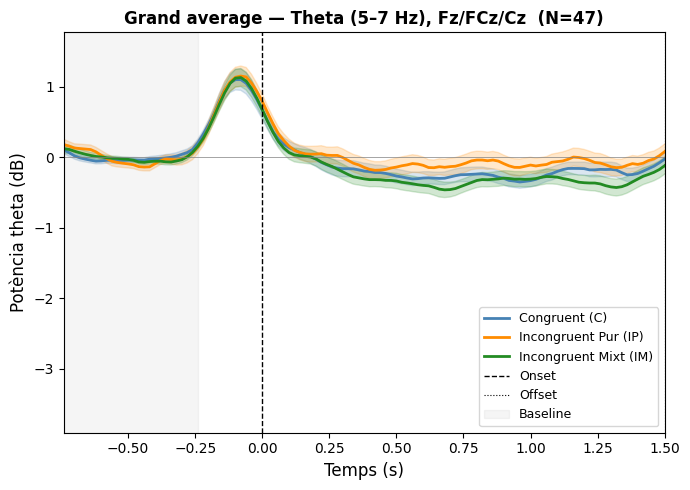

In [ ]:
def plot_timecourse_ga(accumulator, times, ylabel, title, output_name, baseline=BASELINE):
    """Grand average plot with SEM between subjects (baseline corrected)."""
    fig, ax = plt.subplots(figsize=(7, 5))
    n_subj = len(next(iter(accumulator.values())))

    for cond, ts_list in accumulator.items():
        mat = np.array(ts_list)  # (n_subjectes, n_times)

        # Baseline correction: subtract the average of the baseline period
        baseline_mask = (times >= baseline[0]) & (times <= baseline[1])
        baseline_mean = mat[:, baseline_mask].mean(axis=1, keepdims=True)
        mat_corrected = mat - baseline_mean

        mean_ga = mat_corrected.mean(axis=0)
        sem_ga = mat_corrected.std(axis=0) / np.sqrt(len(ts_list))
        ax.plot(times, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
        ax.fill_between(times, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvspan(*baseline, color="gray", alpha=0.08, label="Baseline")
    ax.set_xlabel("time (s)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(f"{title}  (N={n_subj})", fontsize=12, fontweight="bold")
    ax.set_xlim(FULL_TRIAL)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / output_name, dpi=300, bbox_inches="tight")
    plt.show()


plot_timecourse_ga(
    all_theta_cipim,
    times_ga,
    ylabel="Theta power (dB)",
    title="Grand average — Theta (5–7 Hz), Fz/FCz/Cz",
    output_name="grand_average_theta_5_7hz_roi_frontal.png",
    baseline=BASELINE,
)

### Alpha suppression

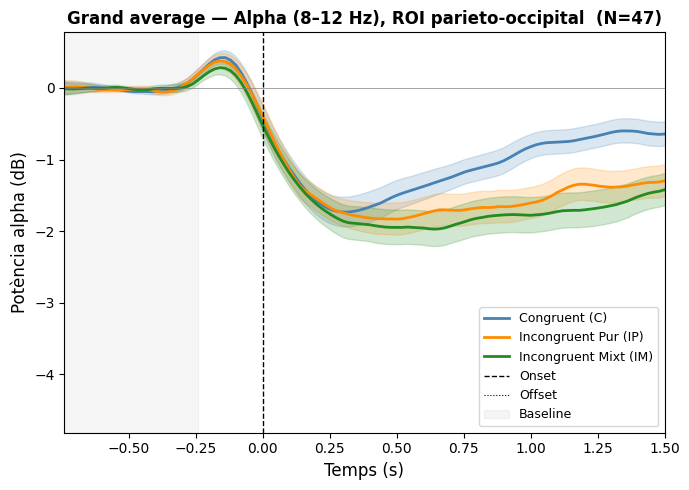

In [ ]:
plot_timecourse_ga(
    all_alpha_cipim,
    times_ga,
    ylabel="Alpha power (dB)",
    title="Grand average — Alpha (8–12 Hz), ROI parieto-occipital",
    output_name="grand_average_alpha_8_12hz_roi_parieto_occipital.png",
)

### ERP (Event-Related Potential)
Averaging the signal in the time domain. Here you need to recalculate because we need the raw data (µV), not the TFRs.

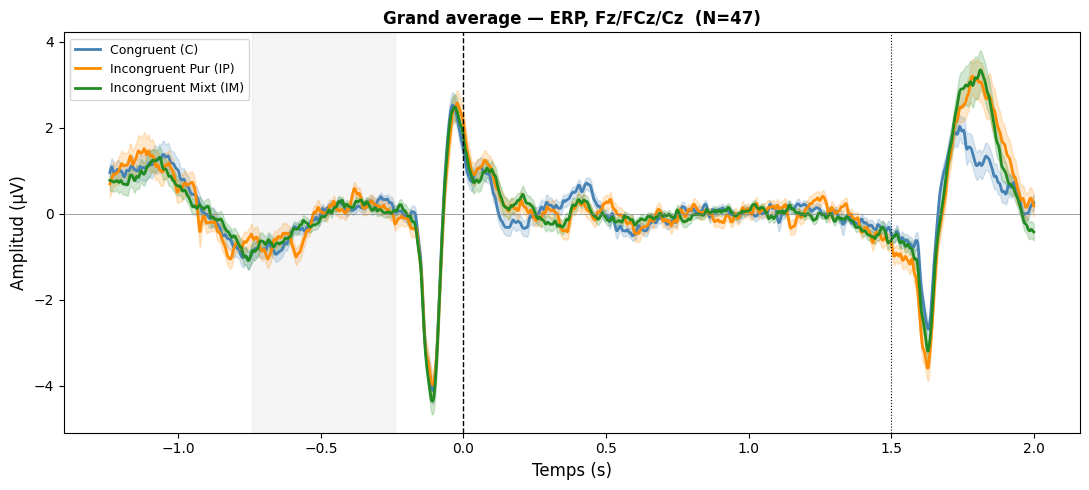

In [ ]:
all_erp = {
    cond: [] for cond in COND_EVENTS_CODES if cond not in ["Incongruent", "Errors"]
}  # (n_subjects, n_times) per average channel
times_erp = None

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    if subj_id not in subjects_inclosos:
        continue

    ep_all, ep_cond = load_subject(fif_path)
    if times_erp is None:
        times_erp = ep_all.times
    for cond, ep in ep_cond.items():
        if cond in ["Incongruent", "Errors"]:
            continue
        # Promig sobre trials i sobre canals ROI → (n_times,)
        data = ep.get_data(picks=ROI_FRONTAL).mean(axis=0).mean(axis=0) * 1e6
        all_erp[cond].append(data)

    del ep_cond, ep_all
    gc.collect()

fig, ax = plt.subplots(figsize=(11, 5))
n_subj = len(subjectes_inclosos)
for cond, ts_list in all_erp.items():
    mat = np.array(ts_list)
    mean_ga = mat.mean(axis=0)
    sem_ga = mat.std(axis=0) / np.sqrt(n_subj)
    ax.plot(times_erp, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times_erp, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("time (s)", fontsize=12)
ax.set_ylabel("Amplitud (µV)", fontsize=12)
ax.set_title(f"Grand average — ERP, Fz/FCz/Cz  (N={n_subj})", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "grand_average_erp_fz_fcz_cz.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 4: Fatigue throughout the session

Research question: **Is there visible fatigue?**

We answer the question in two separate parts:
1. **Errors towards the end**: Let's see if the error rate increases from the first third to the last third of trials.
2. **Decreasing ERP amplitude**: Let's see if the ERP amplitude decreases from the first third to the last third.

For each part we do:
- **Global analysis** (aggregate on subjects)
- **Analysis by subject** (individual trend table)

In [ ]:
def build_bootstrap_curve(series_list, n_bootstrap=1000, smooth_win=5, min_subjects=5, seed=42):
    """Returns dictionary with x, valid, mean, low, high, n_subjects and max_n."""
    if len(series_list) == 0:
        return None

    cleaned = []
    for s in series_list:
        arr = np.asarray(s, dtype=float).ravel()
        if arr.size > 0:
            cleaned.append(arr)

    min_subjects = int(min_subjects)
    if len(cleaned) < max(1, min_subjects):
        return None

    max_n = max(arr.size for arr in cleaned)
    n_subjects = len(cleaned)
    all_values = np.full((n_subjects, max_n), np.nan, dtype=float)
    for i, arr in enumerate(cleaned):
        all_values[i, : arr.size] = arr

    valid_counts = np.sum(~np.isnan(all_values), axis=0)
    has_any = valid_counts > 0
    valid_mask = valid_counts >= min_subjects
    if not np.any(valid_mask):
        return None

    n_bootstrap = int(n_bootstrap)
    rng = np.random.default_rng(seed)
    bootstrap_means = np.full((n_bootstrap, max_n), np.nan, dtype=float)
    for i in range(n_bootstrap):
        sample_idx = rng.integers(0, n_subjects, size=n_subjects)
        sample = all_values[sample_idx, :]
        bootstrap_means[i, has_any] = np.nanmean(sample[:, has_any], axis=0)

    mean_curve = np.nanmean(all_values, axis=0)
    low_ci = np.nanpercentile(bootstrap_means, 2.5, axis=0)
    high_ci = np.nanpercentile(bootstrap_means, 97.5, axis=0)

    if smooth_win is not None and int(smooth_win) > 1:
        win = int(smooth_win)
        kernel = np.ones(win, dtype=float) / float(win)

        def _smooth_nan(arr):
            numer = np.convolve(np.nan_to_num(arr, nan=0.0), kernel, mode="same")
            denom = np.convolve(np.isfinite(arr).astype(float), kernel, mode="same")
            out = np.full_like(arr, np.nan, dtype=float)
            mask = denom > 0
            out[mask] = numer[mask] / denom[mask]
            return out

        mean_curve = _smooth_nan(mean_curve)
        low_ci = _smooth_nan(low_ci)
        high_ci = _smooth_nan(high_ci)

    return {
        "x": np.arange(max_n),
        "valid": valid_mask,
        "mean": mean_curve,
        "low": low_ci,
        "high": high_ci,
        "n_subjects": n_subjects,
        "max_n": max_n,
    }


# Single calculation of fatigue metrics and ERP series per subject
df_fatigue, subject_amp_series = compute_fatigue_metrics(DATA_DIR)

PART A — Errors cap al final
Global (macro-average per subjecte):
  Error T1 (inici) : 0.0050
  Error T2 (mig)   : 0.0040
  Error T3 (final) : 0.0085
  Delta T3-T1      : +0.004
  Subjectes amb augment d'errors (T3>T1): 13/47
  Test de signe (unilateral, augment): p=0.1917


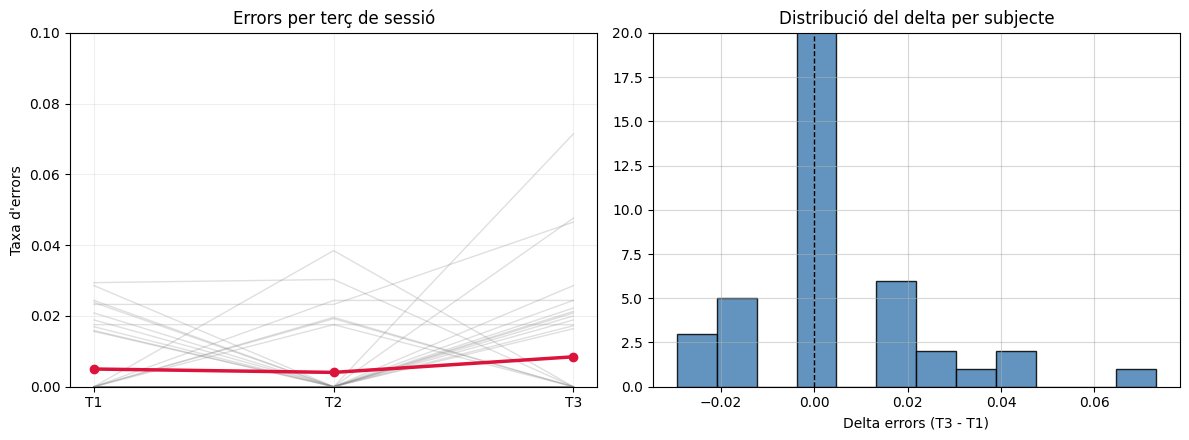

Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\fatiga_errors_subjectes.csv


,subjecte,n_trials,error_t1,error_t2,error_t3,error_delta_t3_t1,error_slope,error_rho,error_p
0,P014,416,0.0000,0.0000,0.0476,0.0732,0.0588,0.1111,0.0235
1,P040,495,0.0000,0.0000,0.0000,0.0408,0.0719,0.1558,0.0005
2,P008,254,0.0000,0.0385,0.0000,0.0400,0.0254,0.0484,0.4421
3,P017,579,0.0000,0.0000,0.0172,0.0351,0.0749,0.1247,0.0026
4,P062,413,0.0000,0.0000,0.0000,0.0244,0.0103,0.0273,0.5801
5,P069,427,0.0233,0.0233,0.0465,0.0244,0.0108,0.0190,0.6959
6,P035,494,0.0000,0.0000,0.0200,0.0204,0.0237,0.0686,0.1280
7,P022,512,0.0000,0.0192,0.0000,0.0196,-0.0138,-0.0343,0.4385
8,P051,529,0.0189,0.0000,0.0189,0.0196,0.0182,0.0369,0.3974
9,P056,520,0.0000,0.0000,0.0000,0.0192,0.0114,0.0753,0.0863


In [ ]:
# PART A — Errors cap al final

# Global trend (macro, same weight per subject)
global_err_t1 = float(df_fatigue["error_t1"].mean())
global_err_t2 = float(df_fatigue["error_t2"].mean())
global_err_t3 = float(df_fatigue["error_t3"].mean())
global_err_delta = float(df_fatigue["error_delta_t3_t1"].mean())

n_pos = int((df_fatigue["error_delta_t3_t1"] > 0).sum())
n_neg = int((df_fatigue["error_delta_t3_t1"] < 0).sum())
n_nonzero = n_pos + n_neg
p_sign = binomtest(n_pos, n=n_nonzero, p=0.5, alternative="greater").pvalue if n_nonzero > 0 else np.nan

print("PART A — Errors cap al final")
print("Global (macro-average by subject):")
print(f"  Error T1 (inici) : {global_err_t1:.4f}")
print(f"  Error T2 (mig)   : {global_err_t2:.4f}")
print(f"  Error T3 (final) : {global_err_t3:.4f}")
print(f"  ΔErrors T3-T1    : {global_err_delta:+.3f}")
print(f"  Subjects with increased errors (T3>T1): {n_pos}/{len(df_fatigue)}")
print(f"  Sign test (one-sided, increase): p={p_sign:.4g}")

# Global view + individual trajectories
x = np.array([1, 2, 3])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

for _, r in df_fatigue.iterrows():
    axes[0].plot(x, [r["error_t1"], r["error_t2"], r["error_t3"]], color="gray", alpha=0.25, linewidth=1)

axes[0].plot(x, [global_err_t1, global_err_t2, global_err_t3], color="crimson", marker="o", linewidth=2.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["T1", "T2", "T3"])
axes[0].set_ylabel("Taxa d'errors")
axes[0].set_title("Errors per third session")
axes[0].set_ylim(0, 0.1)
axes[0].grid(alpha=0.2)

axes[1].hist(df_fatigue["error_delta_t3_t1"], bins=12, color="steelblue", edgecolor="black", alpha=0.85)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_xlabel("Δ errors (T3 - T1)")
axes[1].set_title("Delta distribution by subject")
axes[1].set_ylim(0, 20)
axes[1].grid(alpha=0.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "errors_cap_al_final_i_distribucio_delta.png", dpi=300, bbox_inches="tight")
plt.show()

# Summary by subject
cols_error = [
    "subject",
    "n_trials",
    "error_t1",
    "error_t2",
    "error_t3",
    "error_delta_t3_t1",
    "error_slope",
    "error_rho",
    "error_p",
]
df_fatigue[cols_error].sort_values("error_delta_t3_t1", ascending=False).reset_index(drop=True).round(4).to_csv(
    TABLES_DIR / "fatiga_errors_subjectes.csv", index=False
)
print(f"Saved table: {TABLES_DIR / 'fatiga_errors_subjectes.csv'}")
display(df_fatigue[cols_error].sort_values("error_delta_t3_t1", ascending=False).reset_index(drop=True).round(4))

C:\Users\nils\AppData\Local\Temp\ipykernel_16732\2089904988.py:34: RuntimeWarning: Mean of empty slice
  bootstrap_means[i, has_any] = np.nanmean(sample[:, has_any], axis=0)


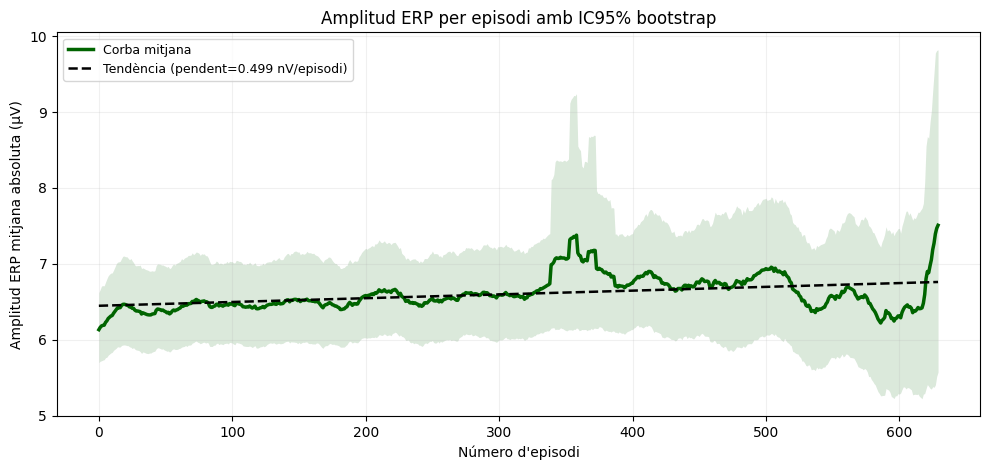

Subjectes inclosos: 47
Episodis màxims: 651
Pendent línia de tendència (tots): 0.499 nV/episodi


In [ ]:
# PART B — ERP amplitude per episode with bootstrap 95% CI (all subjects)
subject_labels = sorted(subject_amp_series.keys())
subject_series = [subject_amp_series[s] for s in subject_labels]

curve = build_bootstrap_curve(
    series_list=subject_series,
    n_bootstrap=BOOT_N,
    smooth_win=20,
    min_subjects=5,
    seed=42,
)

if curve is None:
    print("There is no ERP data to build the curve.")
else:
    x = curve["x"]
    valid = curve["valid"]
    mean_s = curve["mean"]
    low_s = curve["low"]
    high_s = curve["high"]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.fill_between(x[valid], low_s[valid], high_s[valid], color="darkgreen", alpha=0.14, linewidth=0)
    ax.plot(x[valid], mean_s[valid], color="darkgreen", linewidth=2.5, label="Average curve")

    x_fit = x[valid].astype(float)
    y_fit_uv = mean_s[valid]
    m_all_uv, b_all_uv = np.polyfit(x_fit, y_fit_uv, 1)
    m_all_nv = m_all_uv * 1000.0
    y_trend = m_all_uv * x_fit + b_all_uv
    ax.plot(
        x_fit,
        y_trend,
        color="black",
        linestyle="--",
        linewidth=1.8,
        label=f"Trend (slope={m_all_nv:.3f} nV/episodi)",
    )

    ax.set_xlabel("Episode number")
    ax.set_ylabel("Amplitud ERP mitjana absoluta (µV)")
    ax.set_title("ERP amplitude per episode with bootstrap 95% CI")
    ax.grid(alpha=0.18)
    ax.legend(fontsize=9, loc="best")

    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "amplitud_erp_per_episodi_ic95_bootstrap_tots_subjectes.png", dpi=300, bbox_inches="tight"
    )
    plt.show()

    print(f"Included subjects: {curve['n_subjects']}")
    print(f"Maximum Episodes: {curve['max_n']}")
    print(f"Trend line slope (all): {m_all_nv:.3f} nV/episodi")

Subjectes seleccionats (augment d'errors T3>T2 o T3>T1): 14
['P014', 'P017', 'P020', 'P021', 'P024', 'P025', 'P031', 'P035', 'P039', 'P041', 'P051', 'P060', 'P068', 'P069']


C:\Users\nils\AppData\Local\Temp\ipykernel_16732\2089904988.py:34: RuntimeWarning: Mean of empty slice
  bootstrap_means[i, has_any] = np.nanmean(sample[:, has_any], axis=0)


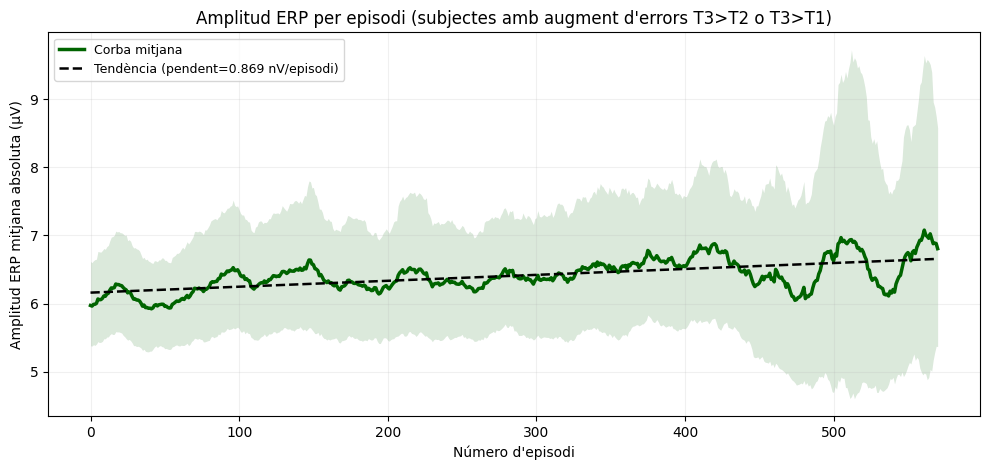

Pendent línia de tendència (subconjunt): 0.869 nV/episodi


In [ ]:
# Same plot as the previous cell, but only for subjects with increased errors
# criteri relaxat: T3 > T2 o T3 > T1
selected_subjects = []

for _, r in df_fatigue.iterrows():
    e1 = float(r["error_t1"])
    e2 = float(r["error_t2"])
    e3 = float(r["error_t3"])

    if (e3 > e2) or (e3 > e1):
        selected_subjects.append(r["subject"])

print(f"Subjectes seleccionats (augment d'errors T3>T2 o T3>T1): {len(selected_subjects)}")
print(selected_subjects)

subject_series_sig = [subject_amp_series[s] for s in selected_subjects if s in subject_amp_series]

curve_sig = build_bootstrap_curve(
    series_list=subject_series_sig,
    n_bootstrap=BOOT_N,
    smooth_win=20,
    min_subjects=3,
    seed=42,
)

if curve_sig is None:
    print("No hi ha subjects que compleixin el criteri T3>T2 o T3>T1.")
else:
    x = curve_sig["x"]
    valid = curve_sig["valid"]
    mean_s = curve_sig["mean"]
    low_s = curve_sig["low"]
    high_s = curve_sig["high"]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.fill_between(x[valid], low_s[valid], high_s[valid], color="darkgreen", alpha=0.14, linewidth=0)
    ax.plot(x[valid], mean_s[valid], color="darkgreen", linewidth=2.5, label="Average curve")

    x_fit = x[valid].astype(float)
    y_fit_uv = mean_s[valid]
    m_sel_uv, b_sel_uv = np.polyfit(x_fit, y_fit_uv, 1)
    m_sel_nv = m_sel_uv * 1000.0
    y_trend = m_sel_uv * x_fit + b_sel_uv
    ax.plot(
        x_fit,
        y_trend,
        color="black",
        linestyle="--",
        linewidth=1.8,
        label=f"Trend (slope={m_sel_nv:.2f} nV/episodi)",
    )

    ax.set_xlabel("Episode number")
    ax.set_ylabel("Amplitud ERP mitjana absoluta (µV)")
    ax.set_title("ERP amplitude per episode (subjects with increased errors T3>T2 or T3>T1)")
    ax.grid(alpha=0.18)
    ax.legend(fontsize=9, loc="best")

    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "amplitud_erp_per_episodi_subjectes_amb_augment_errors_t3_t2_o_t3_t1.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    print(f"Trend line slope (subset): {m_sel_nv:.2f} nV/episodi")

We can confirm that there is a small increase in errors from the middle of the session, but it is not a dramatic increase, and it remains fairly stable until the end of the test.

In terms of ERP amplitude, there is definitely not a clear decrease as I expected, but actually increases over time. This does not confirm that there is no fatigue, but it could be that more brain activity was in fact a sign that the subjects were thinking about other things to distract themselves or to avoid being bored. Further analyzes of specific channels or even new experiments would be necessary to explore this issue further.

In the subjects with more errors at the end than at the beginning and in the middle (first and second third), we also see an increase in ERP amplitude (increase of 0.5 nV/episode vs 0.87 nV/episode, growing faster when there are more errors), which reinforces the idea that this increase is not a signal of greater attention but possibly of distraction or boredom.